# Planificador de builds de Path of Exile 2 con un agente LangGraph

Temas del curso usados: agentes con herramientas y Agentic RAG sobre LangGraph.

#### Resumen
Un agente ReAct (Claude) compara el personaje de un jugador con una build guía y recomienda qué comprar, qué pasivos cambiar, de qué skills prescindir y qué ascendencia tomar, según la economía actual y el presupuesto del jugador. Cada recomendación se mide con el motor de Path of Building antes de entrar al plan, y cada compra trae su link directo al trade site. El resultado se compara con una línea base de reglas fijas, sin LLM.

#### Requisito: Windows
El notebook corre en Windows. El motor de cálculo es Path of Building, que está escrito en Lua y se distribuye con su intérprete (LuaJIT) y sus módulos ya compilados para Windows (`lua51.dll`, `lua-utf8.dll`, `lzip.dll`, entre otros). El proyecto carga esas librerías directamente desde Python, así que en otro sistema operativo la carga del motor falla en la sección 6.1 y, con ella, todo lo que depende de medir builds: la línea base y el agente. La descarga de datos, el RAG y su evaluación no dependen del sistema operativo.

Alternativas en otros sistemas:
- **Linux o macOS:** instalar LuaJIT con el gestor de paquetes (`apt install luajit libluajit-5.1-dev` o `brew install luajit`) y los módulos de Lua que usa Path of Building (con `luarocks`), y cambiar en el motor la librería que se carga (`libluajit-5.1.so` o `libluajit-5.1.dylib` en lugar de `lua51.dll`). Es la misma vía que usan los servidores y bots que corren Path of Building sin interfaz.
- **Máquina virtual o equipo en la nube con Windows:** corre sin cambios.

### El juego en imágenes

**Árbol de pasivos.** Un fragmento del árbol. (1) Nodos de viaje: +Fuerza, Destreza o Inteligencia, a elección. (2) Pasivos menores, con bonos pequeños. (3) Notables, al final de una cadena de menores. (4) Keystones, que cambian una mecánica del personaje (por ejemplo, Chaos Inoculation deja la vida en 1).

<img src="https://preview.redd.it/skill-tree-v0-wb2bhi1883md1.png?width=596&format=png&auto=webp&s=649716526860d17f26ec4b12215b596a0c6d57bf" alt="Árbol completo" width="300">
<img src="https://assets-ng.maxroll.gg/wordpress/poe2-skilltree-nodes-img2-1024x644.webp" alt="Árbol de pasivos" width="500">



**Equipo del personaje.** El inventario con las ranuras de equipo: dos sets de armas (I y II), casco, armadura, guantes, botas, cinturón, amuleto, dos anillos, los frascos de vida y maná y los charms.

<img src="https://www.poe2wiki.net/images/3/33/Sampleequipmentinventory.png" alt="Inventario" width="400">

**Un ítem.** El tooltip de una armadura rara: nombre aleatorio, base, requisitos, encantamiento por corrupción, bonos de las runas, implícito y seis mods explícitos (prefijos y sufijos) con su tier. Este texto es lo que el planner lee del XML de PoB y del trade site.

<img src="https://assets-ng.maxroll.gg/wordpress/anatomyofarareitemmaxrollguide-1-1024x576.webp" alt="Ítem raro" width="400">


## 1. Problema

En Path of Exile 2 un personaje se define por unos 130 pasivos de un árbol de cerca de 1 500 nodos, una ascendencia, 10 ranuras de equipo con mods aleatorios, gemas, joyas, runas y frascos. Para no enfrentar todas las combinaciones posibles, los jugadores siguen guías de las builds más populares. Pero casi nunca se puede seguir una build al pie de la letra:

- La aleatoriedad del juego hace muy difícil conseguir el ítem exacto con los mods y números de la guía. Si el ítem existe, su precio suele ser muy elevado e inviable al inicio.
- Mientras se sube de nivel el presupuesto es limitado, así que hay que priorizar las estadísticas que más ayudan a esa build a avanzar: limpiar mapas y subir de nivel en el menor tiempo posible.
- Un cambio de ítem o de pasivo mueve decenas de stats que interactúan entre sí (crítico, conversión de daño, reserva de spirit, requisitos de atributos). Sin un motor de cálculo no hay forma de saber si mejora.
- Los ítems se compran a otros jugadores en el trade site, y los precios y la oferta cambian cada hora.
- Qué stats importan para cada arquetipo y qué skills se pueden dejar está escrito en wikis y guías, en lenguaje natural.
- Cada jugador tiene sus preferencias: en un personaje a distancia, por ejemplo, se puede sacrificar algo de defensa a cambio de más daño.

La pregunta base de esta progresión e idea de estados temporales es: con este personaje y presupuesto actual (oro y currency) ¿cuáles son las mejores decisiones a tomar para acercarse más a la guía sin perder daño ni defensa y priorizando maximizar daño y/o defensa de ser posible?

Entradas: el XML del personaje (exportado de Path of Building), la guía (archivos `.build`, PoB o la página), `wallet.toml` con el oro y la currency, un objetivo en texto libre y un piso de resistencias.

Salida: un reporte con los pasos en orden (compras con link, respec, puntos al subir de nivel, ascendencia, skills a apagar), los únicos priorizados, el efecto combinado medido y las métricas de la corrida.

## 2. Datos y recursos externos

| Fuente | Qué aporta | De dónde sale |
|---|---|---|
| Personaje (`builds/*.xml`) | Árbol, gemas, ítems, nivel y liga | Path of Building importa el personaje con el OAuth oficial de GGG y guarda el XML |
| Guía (`guides/<id>/`) | Variantes de la build: árbol, gemas y equipo objetivo por nivel | Archivos `.build` del Build Planner del juego (Mobalytics), códigos PoB, pobb.in o la página guardada |
| Wallet (`wallet.toml`) | Oro y currency del jugador | Lo llena el jugador, porque PoE2 no tiene API de stash ni de oro |
| Trade site de PoE2 | Ítems en venta con sus mods, precio y vendedor, y los links de compra | API del sitio oficial, `pathofexile.com/api/trade2` (búsqueda de ítems y detalle de cada listado). No está documentada; se respeta su límite de uso |
| poe.ninja | Precios de currency y de únicos | API de economía, https://poe.ninja/docs/api |
| Path of Building | Motor de cálculo, bases, únicos, runas y descripciones de skills | Repo oficial PoB-PoE2 (MIT), https://github.com/PathOfBuildingCommunity/PathOfBuilding-PoE2, commit `7d6f530cbd`, ejecutado desde Python |
| Árbol de pasivos (`data/tree_0_5.json`) | Los ~4 900 nodos del árbol con su nombre, tipo, stats y conexiones. Sirve para leer los pasivos de las guías `.build`, que los nombran con un id de texto; completar el camino hasta un nodo; detectar los nodos que quedan sueltos en un respec; comparar el árbol del personaje con el de la guía y mostrar nombres en el reporte. Los valores de daño y defensa los sigue calculando PoB | Path of Building lo extrae de los archivos del juego y lo publica en su repositorio. Se descarga de la rama `dev` porque la versión fija del motor no trae los ids de texto que usan las guías |
| poe2wiki.net | Corpus del RAG: mecánicas, defensas y clases | API de MediaWiki (CC BY-NC-SA), más una nota propia sobre balance entre defensa y daño |
| `BAAI/bge-small-en-v1.5` | Embeddings del RAG | Hugging Face |
| Claude Opus 5.5, Sonnet 5.5 y Haiku 5.5 | Opus: agente, prioridades de la guía y dirección de la build. Haiku y Sonnet: solo en la evaluación con RAGAS (respuestas y juez) | SDK `anthropic`, con la clave en `.env` |

En la sección 6 se ve cuánto hay de cada fuente.

## 3. Línea base y solución propuesta

Se comparan dos formas de armar el plan. Las dos usan los mismos datos, el mismo motor PoB, el mismo trade site y la misma validación; lo que cambia es quién decide qué buscar y qué recomendar.

### Línea base: reglas fijas, sin LLM

La línea base hace lo que haría un script escrito a mano:

1. Revisa las stats que calcula PoB y arma una lista de necesidades. Solo conoce cinco:
   - resistencias elementales por debajo del piso que pide el jugador,
   - Fuerza, Destreza o Inteligencia por debajo de lo que piden los ítems y gemas,
   - spirit sobre-reservado (las skills piden más spirit del que hay),
   - resistencia al caos baja cuando el caos es el daño que más le pega al personaje,
   - y siempre, más Energy Shield o más vida (la reserva de defensa que sea mayor).
2. Por cada necesidad busca en el trade site ítems para hasta dos slots que no tengan un único, pidiendo que el reemplazo conserve las resistencias y atributos que ya aporta el ítem actual. Hace como máximo 10 búsquedas por ronda.
3. Mide cada ítem encontrado en PoB y le pone un puntaje fijo: cuántos problemas arregla, cuánto cambian el EHP y el daño, y un pequeño castigo por el precio.
4. Se queda con el mejor ítem de cada slot que entre en el presupuesto. Si las compras juntas pasan los límites de daño o de EHP, saca la de menor puntaje.
5. Repite una segunda ronda sobre el personaje con esas compras.
6. Si al final sigue faltando spirit, apaga la skill que según PoB menos daño pierde, siempre que el plan siga dentro de los límites.

No lee la guía (solo la usa para elegir la variante), no toca el árbol de pasivos, las joyas ni las runas, y si sus reglas no encuentran una salida no prueba otra cosa.

### Solución: agente ReAct con Claude

La solución es Claude Opus dentro de un subgrafo de LangGraph con 15 tools. Recibe el personaje, el presupuesto, el objetivo del jugador, las prioridades de la guía (extraídas con citas) y la dirección de la build, y decide por su cuenta qué buscar, qué medir y qué recomendar: compras, joyas, calidad y runas, respec, próximos puntos, ascendencia y qué skills apagar. Las tools le devuelven números de PoB o del trade site, así que el agente no inventa stats ni precios.

| | Línea base | Agente ReAct |
|---|---|---|
| Qué buscar en trade | Las cinco necesidades de arriba | Lo decide el agente |
| Medir cada candidato | Motor PoB | Motor PoB, desde las tools |
| Decidir el plan | Greedy por puntaje fijo | Opus en un loop ReAct |
| Acciones posibles | Comprar equipo y apagar una skill que reserva spirit | Compras, joyas, runas, respec, puntos, ascendencia y skills |
| Uso de la guía | Solo para elegir la variante | Prioridades con citas y dirección de la build (Opus) |
| RAG | No | Consulta la wiki cuando lo necesita |
| Validación | PoB: presupuesto, requisitos, hasta -10% de daño y -15% de EHP | Igual, con hasta 2 reintentos |

Para comparar se usa la misma medida en las dos opciones, calculada con PoB sobre el plan final: el cambio de BuildDPS (la suma del daño de las skills, incluido el Comet que dispara Cast on Crit), el cambio de EHP, cuántos problemas se resolvieron, si el plan es válido (cabe en el presupuesto, no crea problemas nuevos y respeta los límites de daño y EHP) y si la tarea quedó resuelta (plan válido y sin problemas pendientes). Para el costo se miden el tiempo, las llamadas al LLM, los tokens, los dólares, las búsquedas en trade y las evaluaciones del motor.

El RAG se evalúa por separado en la sección 6.2: primero la recuperación y después la respuesta generada, con RAGAS.

El grafo tiene cuatro etapas: preparación, planificación, validación y reporte. La preparación carga la build y elige la guía y la variante; si el nivel del personaje no alcanza, se detiene y pide otra guía. La planificación es un subgrafo: en la línea base es un solo paso, y en el agente hay un nodo para la llamada a Claude y un nodo por cada tool. Después de cada respuesta de Claude, el grafo pasa por las tools que pidió y vuelve al modelo, hasta que el agente termina. La validación revisa el plan y, en el caso del agente, puede devolvérselo hasta dos veces.

## 4. Instalación y código del proyecto

Las primeras celdas instalan las dependencias, crean las carpetas y descargan Path of Building y el árbol de pasivos. Después, cada celda escribe un archivo del paquete `planner/`.

In [1]:
%pip install -q anthropic langgraph sentence-transformers numpy beautifulsoup4 truststore nbformat matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
for d in ["planner", "tests", "data/kb/curated", "guides", "builds", "reports"]:
    os.makedirs(d, exist_ok=True)
for f in ["planner/__init__.py", "tests/__init__.py"]:
    open(f, "a").close()
%load_ext autoreload
%autoreload 2

In [3]:
import subprocess, pathlib, urllib.request
POB_DIR = pathlib.Path("vendor/PathOfBuilding-PoE2")
POB_COMMIT = "7d6f530cbdab20389ff8bc6ba97a37ac27f74e41"
if not (POB_DIR / "src" / "HeadlessWrapper.lua").exists():   # ~750 MB, una sola vez
    POB_DIR.mkdir(parents=True, exist_ok=True)
    for cmd in (["git", "init"],
                ["git", "remote", "add", "origin", "https://github.com/PathOfBuildingCommunity/PathOfBuilding-PoE2.git"],
                ["git", "fetch", "--depth", "1", "origin", POB_COMMIT], ["git", "checkout", "FETCH_HEAD"]):
        subprocess.run(cmd, cwd=POB_DIR, check=True)
tree_path = pathlib.Path("data/tree_0_5.json")
if not tree_path.exists():
    urllib.request.urlretrieve("https://raw.githubusercontent.com/PathOfBuildingCommunity/PathOfBuilding-PoE2/dev/src/TreeData/0_5/tree.json", tree_path)
print("PoB:", subprocess.run(["git", "log", "-1", "--format=%h %cd"], cwd=POB_DIR, capture_output=True, text=True).stdout.strip(),
      "| árbol:", tree_path.stat().st_size, "bytes")

PoB: 7d6f530 Tue Jul 28 11:23:28 2026 +1000 | árbol: 2052797 bytes


### 4.1 Infraestructura
HTTP con caché y rate limit.

In [4]:
%%writefile planner/net.py
import hashlib
import os
import json
import time
from pathlib import Path
from urllib.error import HTTPError
from urllib.request import Request, urlopen

USER_AGENT = f"OAuth poe2planner/0.1 (contact: {os.environ.get('POE2PLANNER_CONTACT', 'https://github.com/Ericson3100/poe2-build-planner-agent')})"
CACHE_DIR = Path(__file__).resolve().parent.parent / ".cache"

# llamadas reales por política (sin contar caché)
CALLS: dict[str, int] = {}
# cuándo se puede hacer la siguiente
_next_allowed: dict[str, float] = {}
# historial de llamadas por política
_history: dict[str, list[float]] = {}
MIN_INTERVAL = {"trade-search": 10.5, "trade-fetch": 1.5}


def _wait_seconds(headers, policy: str = "default") -> float:
    # segundos a esperar según los headers de rate limit de GGG
    wait = 0.0
    rules = headers.get("X-Rate-Limit-Rules")
    if not rules:
        return wait
    now = time.monotonic()
    for rule in rules.split(","):
        limits = headers.get(f"X-Rate-Limit-{rule}", "")
        states = headers.get(f"X-Rate-Limit-{rule}-State", "")
        for limit, state in zip(limits.split(","), states.split(",")):
            max_hits, period, _ = (int(x) for x in limit.split(":"))
            hits, _, penalty = (int(x) for x in state.split(":"))
            if penalty:
                wait = max(wait, penalty)
            elif hits >= max_hits - 1:
                mine = [t for t in _history.get(policy, []) if now - t < period]
                excess = hits - (max_hits - 2)
                wait = max(wait, mine[excess - 1] + period - now + 1 if len(mine) >= hits else period)
    return wait


def request_json(url: str, *, body: dict | None = None, ttl: float = 0, policy: str = "default"):
    cache_file = None
    if ttl > 0:
        key = hashlib.sha1((url + json.dumps(body, sort_keys=True)).encode()).hexdigest()
        cache_file = CACHE_DIR / f"{key}.json"
        if cache_file.exists() and time.time() - cache_file.stat().st_mtime < ttl:
            return json.loads(cache_file.read_text(encoding="utf-8"))

    delay = _next_allowed.get(policy, 0) - time.monotonic()
    if delay > 0:
        time.sleep(delay)

    headers = {"User-Agent": USER_AGENT}
    data = None
    if body is not None:
        headers["Content-Type"] = "application/json"
        data = json.dumps(body).encode()

    for attempt in range(2):
        try:
            with urlopen(Request(url, data=data, headers=headers), timeout=30) as resp:
                calls = _history.setdefault(policy, [])
                calls.append(time.monotonic())
                del calls[:-1000]
                _next_allowed[policy] = time.monotonic() + max(_wait_seconds(resp.headers, policy),
                                                               MIN_INTERVAL.get(policy, 0))
                payload = json.load(resp)
                CALLS[policy] = CALLS.get(policy, 0) + 1
                break
        except HTTPError as err:
            if err.code == 429 and attempt == 0:
                time.sleep(int(err.headers.get("Retry-After", "60")))
                continue
            raise

    if cache_file is not None:
        CACHE_DIR.mkdir(exist_ok=True)
        cache_file.write_text(json.dumps(payload), encoding="utf-8")
    return payload

Overwriting planner/net.py


### 4.2 Lectura de builds
XML de PoB, códigos PoB, árbol de pasivos y archivos `.build`.

In [5]:
%%writefile planner/pob_xml.py
import re
import xml.etree.ElementTree as ET
from dataclasses import dataclass, field
from pathlib import Path

_PROPERTY_KEYS = {
    "Unique ID", "Item Level", "LevelReq", "Quality", "Sockets", "Rune",
    "Armour", "Evasion", "Energy Shield", "Ward", "Charm Slots", "Radius",
}
_TAG_RE = re.compile(r"\{([^}]*)\}")


@dataclass
class Mod:
    text: str
    tags: list[str] = field(default_factory=list)


@dataclass
class Item:
    id: int
    rarity: str
    name: str
    base: str
    properties: dict[str, str] = field(default_factory=dict)
    runes: list[str] = field(default_factory=list)
    implicits: list[Mod] = field(default_factory=list)
    explicits: list[Mod] = field(default_factory=list)
    corrupted: bool = False

    @property
    def item_level(self) -> int | None:
        value = self.properties.get("Item Level")
        return int(value) if value else None


@dataclass
class Gem:
    name: str
    gem_id: str
    level: int
    quality: int
    enabled: bool
    is_support: bool


@dataclass
class SkillGroup:
    gems: list[Gem]
    slot: str | None
    granted_by: str | None
    enabled: bool
    is_main: bool


@dataclass
class Build:
    class_name: str
    ascendancy: str
    level: int
    tree_version: str
    league: str | None
    nodes: set[int]
    weapon_set_nodes: dict[int, set[int]]
    jewel_sockets: dict[int, int]
    skills: list[SkillGroup]
    items: dict[int, Item]
    slots: dict[str, int]
    stats: dict[str, float]
    config: dict[str, str | float]

    def equipped(self) -> dict[str, Item]:
        return {slot: self.items[item_id] for slot, item_id in self.slots.items() if item_id in self.items}


def _split_tags(line: str) -> Mod:
    tags = _TAG_RE.findall(line)
    return Mod(text=_TAG_RE.sub("", line).strip(), tags=tags)


def parse_item_text(item_id: int, raw: str) -> Item:
    lines = [ln.strip() for ln in raw.strip().splitlines() if ln.strip()]
    rarity = lines[0].removeprefix("Rarity: ").strip()
    # raros y únicos tienen línea de nombre y de base
    if rarity in ("RARE", "UNIQUE"):
        name, base, rest = lines[1], lines[2], lines[3:]
    else:
        name, base, rest = lines[1], lines[1], lines[2:]

    item = Item(id=item_id, rarity=rarity, name=name, base=base)
    i = 0
    while i < len(rest):
        line = rest[i]
        key, sep, value = line.partition(": ")
        if line.startswith("Implicits: "):
            count = int(value)
            item.implicits = [_split_tags(ln) for ln in rest[i + 1 : i + 1 + count]]
            for ln in rest[i + 1 + count :]:
                if ln == "Corrupted":
                    item.corrupted = True
                else:
                    item.explicits.append(_split_tags(ln))
            break
        if sep and key == "Rune":
            if value != "None":
                item.runes.append(value)
        elif sep and key in _PROPERTY_KEYS:
            item.properties[key] = value
        i += 1
    return item


def _attr(elem: ET.Element, name: str, default: str = "") -> str:
    value = elem.get(name, default)
    return default if value == "nil" else value


def _node_list(value: str) -> set[int]:
    return {int(n) for n in value.split(",") if n}


BUILDS_DIR = Path(__file__).resolve().parent.parent / "builds"


def resolve_build(name: str | Path | None = None, folder: str | Path | None = None) -> Path:
    folder = Path(folder) if folder else BUILDS_DIR
    files = sorted(folder.glob("*.xml"), key=lambda p: p.stat().st_mtime, reverse=True)
    if name:
        path = Path(name)
        if path.is_file():
            return path
        path = folder / (path.name if path.suffix.lower() == ".xml" else f"{path.name}.xml")
        if path.is_file():
            return path
        raise FileNotFoundError(f"No existe la build '{name}' en {folder}. Disponibles: {[p.name for p in files]}")
    if not files:
        raise FileNotFoundError(f"No hay builds en {folder}: guarda tu personaje desde PoB2 en esa carpeta.")
    if len(files) > 1:
        print(f"{len(files)} builds en {folder.name}/; se usa la más reciente: {files[0].name}")
    return files[0]


def load_build(path: str | Path) -> Build:
    root = ET.parse(path).getroot()
    build_el = root.find("Build")
    spec = root.find("Tree/Spec")

    stats = {ps.get("stat"): float(ps.get("value")) for ps in build_el.findall("PlayerStat")}

    weapon_sets = {}
    for ws in spec:
        if ws.tag.startswith("WeaponSet"):
            weapon_sets[int(ws.tag.removeprefix("WeaponSet"))] = _node_list(ws.get("nodes", ""))
    jewel_sockets = {int(s.get("nodeId")): int(s.get("itemId")) for s in spec.findall("Sockets/Socket")}

    skills_el = root.find("Skills")
    active_set = skills_el.get("activeSkillSet", "1")
    main_group = int(_attr(build_el, "mainSocketGroup", "0") or 0)
    skills = []
    for index, skill_el in enumerate(skills_el.findall(f"SkillSet[@id='{active_set}']/Skill"), 1):
        gems = [
            Gem(
                name=g.get("nameSpec"),
                gem_id=g.get("gemId"),
                level=int(_attr(g, "level", "0")),
                quality=int(_attr(g, "quality", "0")),
                enabled=_attr(g, "enabled") == "true",
                is_support="SupportGem" in g.get("gemId", ""),
            )
            for g in skill_el.findall("Gem")
        ]
        skills.append(SkillGroup(
            gems=gems,
            slot=_attr(skill_el, "slot") or None,
            granted_by=_attr(skill_el, "source") or None,
            enabled=_attr(skill_el, "enabled") == "true",
            is_main=index == main_group,
        ))

    items_el = root.find("Items")
    items = {}
    for item_el in items_el.findall("Item"):
        item_id = int(item_el.get("id"))
        items[item_id] = parse_item_text(item_id, item_el.text or "")
    active_item_set = items_el.get("activeItemSet", "1")
    slots = {
        s.get("name"): int(s.get("itemId"))
        for s in items_el.findall(f"ItemSet[@id='{active_item_set}']/Slot")
        if s.get("itemId", "0") != "0"
    }

    config_el = root.find(f"Config/ConfigSet[@id='{root.find('Config').get('activeConfigSet', '1')}']")
    config = {}
    for inp in list(config_el) if config_el is not None else []:
        name = inp.get("name")
        if inp.get("number") is not None:
            config[name] = float(inp.get("number"))
        else:
            config[name] = inp.get("string") or inp.get("boolean", "")

    import_el = root.find("Import")
    return Build(
        class_name=build_el.get("className"),
        ascendancy=build_el.get("ascendClassName"),
        level=int(build_el.get("level")),
        tree_version=spec.get("treeVersion"),
        league=import_el.get("lastLeague") if import_el is not None else None,
        nodes=_node_list(spec.get("nodes", "")),
        weapon_set_nodes=weapon_sets,
        jewel_sockets=jewel_sockets,
        skills=skills,
        items=items,
        slots=slots,
        stats=stats,
        config=config,
    )

Overwriting planner/pob_xml.py


In [6]:
%%writefile planner/pob_code.py
import base64
import re
import zlib
from urllib.request import Request, urlopen

from planner.net import USER_AGENT

_POBBIN_RE = re.compile(r"pobb\.in/(?:u/[^/]+/)?([A-Za-z0-9_-]+)")


def decode_code(code: str) -> str:
    code = code.strip().replace("+", "-").replace("/", "_")
    padded = code + "=" * (-len(code) % 4)
    return zlib.decompress(base64.urlsafe_b64decode(padded)).decode("utf-8")


def resolve(code_or_link: str) -> str:
    text = code_or_link.strip()
    match = _POBBIN_RE.search(text)
    if match:
        req = Request(f"https://pobb.in/{match.group(1)}/raw", headers={"User-Agent": USER_AGENT})
        with urlopen(req, timeout=30) as resp:
            text = resp.read().decode("utf-8")
    return decode_code(text)

Overwriting planner/pob_code.py


In [7]:
%%writefile planner/tree.py
import json
from dataclasses import dataclass
from functools import lru_cache
from pathlib import Path

DATA_DIR = Path(__file__).resolve().parent.parent / "data"


@dataclass(frozen=True)
class Node:
    id: int
    string_id: str | None
    name: str
    stats: tuple[str, ...]
    kind: str
    connections: tuple[int, ...]


def _kind(raw: dict) -> str:
    if raw.get("isKeystone"):
        return "keystone"
    if raw.get("isNotable"):
        return "notable"
    if raw.get("isJewelSocket"):
        return "jewel"
    if raw.get("ascendancyName"):
        return "ascendancy"
    if raw.get("isAttribute"):
        return "attribute"
    return "small"


class Tree:
    def __init__(self, version: str = "0_5") -> None:
        raw = json.loads((DATA_DIR / f"tree_{version}.json").read_text(encoding="utf-8"))
        self.nodes: dict[int, Node] = {}
        for key, n in raw["nodes"].items():
            if not key.isdigit():
                continue
            self.nodes[int(key)] = Node(
                id=int(key),
                string_id=n.get("stringId"),
                name=n.get("name", ""),
                stats=tuple(n.get("stats", [])),
                kind=_kind(n),
                connections=tuple(c["id"] for c in n.get("connections", [])),
            )
        self.by_string_id = {n.string_id: n.id for n in self.nodes.values() if n.string_id}
        self.ascendancy = {int(k): n.get("ascendancyName") for k, n in raw["nodes"].items()
                           if k.isdigit() and n.get("ascendancyName")}
        self.class_start = {int(k): n["classesStart"] for k, n in raw["nodes"].items()
                            if k.isdigit() and n.get("classesStart")}
        # los nodos que son solo imagen no se pueden asignar
        image_only = {int(k) for k, n in raw["nodes"].items() if k.isdigit() and n.get("isOnlyImage")}
        # el archivo del árbol guarda cada conexión una sola vez
        self.adjacent: dict[int, set[int]] = {i: set() for i in self.nodes if i not in image_only}
        for node in self.nodes.values():
            if node.id in image_only:
                continue
            for other in node.connections:
                if other in self.adjacent:
                    self.adjacent[node.id].add(other)
                    self.adjacent[other].add(node.id)

    def path_to(self, allocated: set[int], target: int) -> list[int]:
        # camino más corto, por nodos libres, hasta el nodo buscado
        if target in allocated:
            return []
        # los nodos de ascendencia se buscan dentro de su propio árbol
        domain = self.ascendancy.get(target)
        in_domain = lambda n: self.ascendancy.get(n) == domain
        start_ok = lambda n: n not in self.class_start or n in allocated
        frontier = [n for n in allocated if in_domain(n)]
        parent: dict[int, int | None] = {n: None for n in frontier}
        queue = list(frontier)
        while queue:
            nxt = []
            for node in queue:
                for other in self.adjacent.get(node, ()):
                    if other in parent or not in_domain(other) or not start_ok(other):
                        continue
                    parent[other] = node
                    if other == target:
                        path = [other]
                        while parent[path[-1]] not in allocated and parent[path[-1]] is not None:
                            path.append(parent[path[-1]])
                        return list(reversed(path))
                    nxt.append(other)
            queue = nxt
        return []

    def orphans(self, allocated: set[int], removed: set[int]) -> set[int]:
        # nodos que quedan sueltos al quitar otros
        remaining = allocated - removed
        starts = [n for n in remaining if n in self.class_start]
        seen = set(starts)
        queue = list(starts)
        while queue:
            node = queue.pop()
            for other in self.adjacent.get(node, ()):
                if other in remaining and other not in seen and other not in self.ascendancy:
                    seen.add(other)
                    queue.append(other)
        return {n for n in remaining if n not in seen and n not in self.ascendancy}


@lru_cache(maxsize=4)
def load_tree(version: str = "0_5") -> Tree:
    return Tree(version)

Overwriting planner/tree.py


In [8]:
%%writefile planner/build_file.py
import json
import re
from dataclasses import dataclass, field
from pathlib import Path

from planner.tree import load_tree


@dataclass
class LevelRange:
    low: int = 0
    high: int = 100

    @classmethod
    def parse(cls, value) -> "LevelRange":
        if value is None:
            return cls()
        if isinstance(value, int):
            return cls(value, 100)
        return cls(value[0], value[1] if len(value) > 1 else 100)

    def contains(self, level: int) -> bool:
        return self.low <= level <= self.high


@dataclass
class PlannedPassive:
    string_id: str
    node_id: int | None
    levels: LevelRange
    weapon_set: int | None
    note: str | None


@dataclass
class PlannedGem:
    gem_id: str
    levels: LevelRange
    note: str | None
    supports: list["PlannedGem"] = field(default_factory=list)

    @property
    def short_name(self) -> str:
        return self.gem_id.rsplit("/", 1)[-1].removeprefix("SkillGem").removeprefix("SupportGem")


@dataclass
class SlotHint:
    inventory_id: str
    levels: LevelRange
    unique_name: str | None
    note: str | None


@dataclass
class BuildPlan:
    name: str
    author: str | None
    description: str | None
    ascendancy: str | None
    passives: list[PlannedPassive]
    skills: list[PlannedGem]
    slots: list[SlotHint]

    def passives_at(self, level: int) -> set[int]:
        return {p.node_id for p in self.passives if p.node_id is not None and p.levels.contains(level)}

    def gear_level(self) -> int:
        return max((s.levels.low for s in self.slots if s.levels.low > 0), default=0)

    def slot_hints_at(self, level: int) -> dict[str, SlotHint]:
        out: dict[str, SlotHint] = {}
        for hint in self.slots:
            slot = pob_slot(hint.inventory_id)
            if slot and hint.levels.contains(level):
                if slot not in out or hint.levels.low >= out[slot].levels.low:
                    out[slot] = hint
        return out


# ids de inventario del juego -> slots de PoB
_SLOT_NAMES = {"Weapon1": "Weapon 1", "Weapon2": "Weapon 1 Swap", "Offhand1": "Weapon 2", "Offhand2": "Weapon 2 Swap",
               "Helm1": "Helmet", "BodyArmour1": "Body Armour", "Gloves1": "Gloves", "Boots1": "Boots",
               "Amulet1": "Amulet", "Ring1": "Ring 1", "Ring2": "Ring 2", "Belt1": "Belt"}


def pob_slot(inventory_id: str) -> str | None:
    return _SLOT_NAMES.get(inventory_id)


def hint_item_text(hint: SlotHint) -> str | None:
    if hint.unique_name or not hint.note:
        return None
    lines = [ln.strip() for ln in hint.note.splitlines() if ln.strip()]
    mods = [re.sub(r"^\d+\.\s*", "", ln) for ln in lines[1:] if re.match(r"^\d+\.", ln)]
    if not mods:
        return None
    return "\n".join(["Rarity: RARE", "Guide Target", lines[0], "Implicits: 0", *mods])


def _entry(value) -> dict:
    return {"id": value} if isinstance(value, str) else value


def _gem(raw) -> PlannedGem:
    raw = _entry(raw)
    return PlannedGem(
        gem_id=raw["id"],
        levels=LevelRange.parse(raw.get("level_interval")),
        note=raw.get("additional_text"),
        supports=[_gem(s) for s in raw.get("support_skills", [])],
    )


def load_build_file(path: str | Path, tree_version: str = "0_5") -> BuildPlan:
    raw = json.loads(Path(path).read_text(encoding="utf-8-sig"))
    tree = load_tree(tree_version)
    passives = []
    for p in map(_entry, raw.get("passives", [])):
        passives.append(PlannedPassive(
            string_id=p["id"],
            node_id=tree.by_string_id.get(p["id"]),
            levels=LevelRange.parse(p.get("level_interval")),
            weapon_set=p.get("weapon_set"),
            note=p.get("additional_text"),
        ))
    return BuildPlan(
        name=raw["name"],
        author=raw.get("author"),
        description=raw.get("description"),
        ascendancy=raw.get("ascendancy"),
        passives=passives,
        skills=[_gem(s) for s in raw.get("skills", [])],
        slots=[SlotHint(
            inventory_id=s["inventory_id"],
            levels=LevelRange.parse(s.get("level_interval")),
            unique_name=s.get("unique_name"),
            note=s.get("additional_text"),
        ) for s in raw.get("inventory_slots", [])],
    )

Overwriting planner/build_file.py


### 4.3 Economía y datos de ítems
Wallet, precios de poe.ninja, trade site, runas, calidad y datos de PoB.

In [9]:
%%writefile planner/wallet.py
import tomllib
from dataclasses import dataclass, field
from pathlib import Path


@dataclass
class Wallet:
    league: str
    gold: int
    currency: dict[str, int] = field(default_factory=dict)
    costs: dict[str, float] = field(default_factory=dict)


def load_wallet(path: str | Path) -> Wallet:
    data = tomllib.loads(Path(path).read_text(encoding="utf-8"))
    return Wallet(
        league=data["league"],
        gold=int(data.get("gold", 0)),
        currency={name: int(count) for name, count in data.get("currency", {}).items() if int(count) > 0},
        costs={k: float(v) for k, v in data.get("costs", {}).items()},
    )

Overwriting planner/wallet.py


In [10]:
%%writefile planner/prices.py
from dataclasses import dataclass
from urllib.parse import urlencode

from planner.net import request_json

NINJA = "https://poe.ninja/poe2/api/economy"
TTL = 3600

EXCHANGE_TYPES = [
    "Currency", "Fragments", "Abyss", "UncutGems", "LineageSupportGems", "Essences",
    "SoulCores", "Idols", "Runes", "Ritual", "Expedition", "Delirium", "Breach", "Verisium",
]
UNIQUE_TYPES = [
    "UniqueWeapons", "UniqueArmours", "UniqueAccessories", "UniqueFlasks",
    "UniqueCharms", "UniqueJewels", "UniqueSanctumRelics", "UniqueTablets",
]


@dataclass
class Price:
    name: str
    divine: float
    category: str
    base_type: str | None = None
    listings: int | None = None


class PriceBook:

    def __init__(self, league: str) -> None:
        self.league = league
        self._prices: dict[str, Price] = {}
        self._by_trade_id: dict[str, float] = {}
        self._loaded: set[str] = set()
        self.exalted_per_divine: float | None = None

    def _get(self, path: str, type_: str) -> dict:
        query = urlencode({"league": self.league, "type": type_})
        return request_json(f"{NINJA}/{path}?{query}", ttl=TTL, policy="ninja")

    def load_exchange(self, type_: str) -> None:
        if type_ in self._loaded:
            return
        data = self._get("exchange/current/overview", type_)
        names = {it["id"]: it["name"] for it in data.get("items", [])}
        names.update({it["id"]: it["name"] for it in data["core"].get("items", [])})
        rates = data["core"].get("rates", {})
        if "exalted" in rates:
            self.exalted_per_divine = rates["exalted"]
        for line in data["lines"]:
            name = names.get(line["id"], line["id"])
            self._prices[name] = Price(name=name, divine=line["primaryValue"], category=type_)
            self._by_trade_id[line["id"]] = line["primaryValue"]
        self._by_trade_id.setdefault("divine", 1.0)
        self._loaded.add(type_)

    def load_uniques(self, type_: str) -> None:
        if type_ in self._loaded:
            return
        for line in self._get("stash/current/item/overview", type_)["lines"]:
            key = line["name"]
            # el mismo único sale varias veces (corrupto, otras bases): se guarda el más barato
            if key in self._prices and self._prices[key].divine <= line["primaryValue"]:
                continue
            self._prices[key] = Price(
                name=key, divine=line["primaryValue"], category=type_,
                base_type=line.get("baseType"), listings=line.get("listingCount"),
            )
        self._loaded.add(type_)

    def load_all(self) -> None:
        for t in EXCHANGE_TYPES:
            self.load_exchange(t)
        for t in UNIQUE_TYPES:
            self.load_uniques(t)

    def get(self, name: str) -> Price | None:
        if name not in self._prices:
            self.load_all()
        return self._prices.get(name)

    def listing_in_exalted(self, amount: float, currency: str) -> float | None:
        self.load_exchange("Currency")
        divines = self._by_trade_id.get(currency)
        return None if divines is None else self.to_exalted(amount * divines)

    def to_exalted(self, divine: float) -> float:
        if self.exalted_per_divine is None:
            self.load_exchange("Currency")
        return divine * self.exalted_per_divine

    def wallet_value(self, currency: dict[str, int]) -> float:
        total = 0.0
        for name, count in currency.items():
            price = self.get(name)
            if price:
                total += price.divine * count
            elif name == "Divine Orb":
                total += count
        return total

Overwriting planner/prices.py


In [11]:
%%writefile planner/trade.py
import json
import re
from dataclasses import dataclass, field
from urllib.parse import quote

from planner.net import request_json

BASE = "https://www.pathofexile.com/api/trade2"
SITE = "https://www.pathofexile.com/trade2"
SEARCH_TTL = 900
_BRACKET_RE = re.compile(r"\[(?:[^|\]]*\|)?([^\]]*)\]")


@dataclass
class StatFilter:
    stat_id: str
    min: float | None = None
    max: float | None = None


@dataclass
class Listing:
    id: str
    name: str
    base_type: str
    ilvl: int | None
    price_amount: float | None
    price_currency: str | None
    rarity: str = "RARE"
    implicits: list[str] = field(default_factory=list)
    explicits: list[str] = field(default_factory=list)
    corrupted: bool = False
    whisper_account: str | None = None
    stash: str | None = None
    fee_gold: int | None = None
    query: dict | None = None
    search_id: str | None = None
    quality: int = 0
    sockets: int = 0
    runes: list[str] = field(default_factory=list)
    requirements: dict[str, int] = field(default_factory=dict)

    def purchase_link(self, league: str) -> str:
        body = json.loads(json.dumps(self.query or {"query": {}}))
        q = body.setdefault("query", {})
        q.setdefault("filters", {}).setdefault("trade_filters", {}).setdefault("filters", {})
        if self.whisper_account:
            q["filters"]["trade_filters"]["filters"]["account"] = {"input": self.whisper_account}
        return search_link(league, body)

    @property
    def mods(self) -> list[str]:
        return self.implicits + self.explicits

    def to_pob_text(self) -> str:
        lines = [f"Rarity: {self.rarity}"]
        if self.rarity in ("RARE", "UNIQUE"):
            lines += [self.name or "Trade Item", self.base_type]
        else:
            lines.append(self.base_type)
        if self.ilvl:
            lines.append(f"Item Level: {self.ilvl}")
        if self.requirements.get("Level"):
            lines.append(f"LevelReq: {self.requirements['Level']}")
        if self.quality:
            lines.append(f"Quality: {self.quality}")
        if self.sockets:
            lines.append("Sockets: " + " ".join(["S"] * self.sockets))
            lines += [f"Rune: {r}" for r in self.runes] + ["Rune: None"] * (self.sockets - len(self.runes))
        lines.append(f"Implicits: {len(self.implicits)}")
        lines += self.implicits + self.explicits
        if self.corrupted:
            lines.append("Corrupted")
        return "\n".join(lines)


def _quality(item: dict) -> int:
    for prop in item.get("properties", []):
        if "Quality" in prop.get("name", "") and prop.get("values"):
            m = re.search(r"\d+", prop["values"][0][0])
            return int(m.group(0)) if m else 0
    return 0


def _requirements(item: dict) -> dict[str, int]:
    out = {}
    for req in item.get("requirements", []):
        name = clean_mod_text(req.get("name", "")).strip()
        name = {"Strength": "Str", "Dexterity": "Dex", "Intelligence": "Int"}.get(name, name)
        m = re.search(r"\d+", (req.get("values") or [[""]])[0][0])
        if m:
            out[name] = int(m.group(0))
    return out


def clean_mod_text(text: str) -> str:
    return _BRACKET_RE.sub(r"\1", text)


def stats_catalog() -> dict[str, str]:
    data = request_json(f"{BASE}/data/stats", ttl=24 * 3600, policy="trade-data")
    return {entry["id"]: entry["text"] for group in data["result"] for entry in group["entries"]}


def find_stats(text: str, kind: str = "explicit") -> list[tuple[str, str]]:
    needle = text.lower()
    return [(sid, t) for sid, t in stats_catalog().items() if sid.startswith(kind + ".") and needle in t.lower()]


def build_query(*, name: str | None = None, base_type: str | None = None, category: str | None = None,
                stats: list[StatFilter] | None = None, max_price: float | None = None,
                price_currency: str = "exalted", max_level: int | None = None, rarity: str | None = None,
                any_of: list[StatFilter] | None = None) -> dict:
    query: dict = {"status": {"option": "securable"}}
    if name:
        query["name"] = name
    if base_type:
        query["type"] = base_type
    def stat_filters(group):
        return [{"id": s.stat_id, "value": {k: v for k, v in (("min", s.min), ("max", s.max)) if v is not None}}
                for s in group]
    if stats:
        query["stats"] = [{"type": "and", "filters": stat_filters(stats)}]
    if any_of:
        query.setdefault("stats", []).append({"type": "count", "value": {"min": 1}, "filters": stat_filters(any_of)})
    filters: dict = {}
    if category or rarity:
        type_filters = {"category": {"option": category}} if category else {}
        if rarity:
            type_filters["rarity"] = {"option": rarity}
        filters["type_filters"] = {"filters": type_filters}
    if max_price is not None:
        filters["trade_filters"] = {"filters": {"price": {"max": max_price, "option": price_currency}}}
    if max_level is not None:
        filters["req_filters"] = {"filters": {"lvl": {"max": max_level}}}
    if filters:
        query["filters"] = filters
    return {"query": query, "sort": {"price": "asc"}}


def search_link(league: str, body: dict) -> str:
    return f"{SITE}/search/poe2/{quote(league)}?q={quote(json.dumps(body, separators=(',', ':')))}"


def search(league: str, body: dict, limit: int = 10, ttl: float = SEARCH_TTL) -> tuple[int, list[Listing]]:
    found = request_json(f"{BASE}/search/poe2/{quote(league)}", body=body, ttl=ttl, policy="trade-search")
    ids = found.get("result", [])[: min(limit, 10)]  # máximo 10 ids por fetch
    if not ids:
        return found.get("total", 0), []
    fetched = request_json(f"{BASE}/fetch/{','.join(ids)}?query={found['id']}", ttl=ttl, policy="trade-fetch")
    listings = []
    for res in fetched["result"]:
        item, listing = res["item"], res["listing"]
        price = listing.get("price") or {}

        def texts(key: str, tag: str = "") -> list[str]:
            return [tag + clean_mod_text(m["description"] if isinstance(m, dict) else m) for m in item.get(key, [])]

        listings.append(Listing(
            id=res["id"], name=item.get("name", ""), base_type=item.get("baseType", ""),
            ilvl=item.get("ilvl"), price_amount=price.get("amount"), price_currency=price.get("currency"),
            rarity=item.get("rarity", "Rare").upper(),
            implicits=texts("enchantMods", "{enchant}") + texts("runeMods", "{enchant}{rune}") + texts("implicitMods"),
            explicits=texts("explicitMods") + texts("craftedMods", "{crafted}") + texts("desecratedMods"),
            corrupted=bool(item.get("corrupted")),
            whisper_account=(listing.get("account") or {}).get("name"),
            stash=(f"{listing['stash'].get('name')} ({listing['stash'].get('x')}, {listing['stash'].get('y')})"
                   if listing.get("stash") else None),
            fee_gold=listing.get("fee"),
            query=body,
            search_id=found.get("id"),
            quality=_quality(item),
            sockets=len(item.get("sockets") or []),
            runes=[x.get("typeLine", "") for x in item.get("socketedItems") or []],
            requirements=_requirements(item),
        ))
    return found.get("total", 0), listings

Overwriting planner/trade.py


In [12]:
%%writefile planner/runes.py
import re
from functools import lru_cache
from pathlib import Path

RUNES_FILE = Path(__file__).resolve().parent.parent / "vendor" / "PathOfBuilding-PoE2" / "src" / "Data" / "ModRunes.lua"
_ENTRY_RE = re.compile(r'^\t\["(?P<name>[^"]+)"\] = \{\n(?P<body>.*?)^\t\},?$', re.M | re.S)
_SLOT_RE = re.compile(r'^\t\t\["(?P<slot>[^"]+)"\] = \{\n(?P<body>.*?)^\t\t\},?$', re.M | re.S)
_MOD_RE = re.compile(r'^\t\t\t\t"(?P<mod>.+)",$', re.M)

@lru_cache(maxsize=1)
def rune_table() -> dict[str, dict[str, list[str]]]:
    text = RUNES_FILE.read_text(encoding="utf-8")
    table: dict[str, dict[str, list[str]]] = {}
    for entry in _ENTRY_RE.finditer(text):
        slots = {m["slot"]: _MOD_RE.findall(m["body"]) for m in _SLOT_RE.finditer(entry["body"])}
        if slots:
            table[entry["name"]] = slots
    return table


def runes_for(kind: str) -> dict[str, list[str]]:
    return {name: slots[kind] for name, slots in rune_table().items() if kind in slots}

Overwriting planner/runes.py


In [13]:
%%writefile planner/upgrades.py
import re
import xml.etree.ElementTree as ET

from planner.runes import runes_for

ARMOUR_SLOTS_SET = {"Helmet", "Body Armour", "Gloves", "Boots", "Weapon 2"}
TWO_HANDED = ("staff", "bow", "crossbow", "quarterstaff", "two hand")
QUALITY_ORB = {"armour": "Armourer's Scrap", "weapon": "Blacksmith's Whetstone", "caster": "Arcanist's Etcher"}
# runas que le sirven a un caster o a alguna defensa
RELEVANT = re.compile(r"Resist|Energy Shield|Life|Mana|Spell|Cold|Critical|Spirit|Cast Speed|Attribute|"
                      r"Intelligence|Strength|Dexterity|Armour, Evasion", re.I)


def kinds(slot: str, base: str) -> list[str]:
    b = base.lower()
    if slot in ("Helmet", "Body Armour", "Gloves", "Boots"):
        return [slot.lower(), "armour"]
    if slot.startswith("Weapon 2") and ("shield" in b or "buckler" in b or "focus" in b):
        return ["shield", "buckler", "focus", "armour"]
    if slot.startswith("Weapon"):
        if "staff" in b and "quarter" not in b:
            return ["staff", "caster", "martial weapon wand or staff", "weapon"]
        if "wand" in b or "sceptre" in b:
            return ["wand", "sceptre", "caster", "martial weapon wand or staff", "weapon"]
        return ["weapon"]
    return []


def max_sockets(slot: str, base: str) -> int:
    if slot == "Body Armour":
        return 2
    if slot.startswith("Weapon"):
        return 2 if any(t in base.lower() for t in TWO_HANDED) else 1
    if slot in ("Helmet", "Gloves", "Boots"):
        return 1
    return 0


def rune_lines(name: str, slot: str, base: str) -> list[str] | None:
    for kind in kinds(slot, base):
        lines = runes_for(kind).get(name)
        if lines:
            return lines
    return None


def candidate_runes(slot: str, base: str) -> dict[str, list[str]]:
    out: dict[str, list[str]] = {}
    for kind in reversed(kinds(slot, base)):
        for name, lines in runes_for(kind).items():
            if any(RELEVANT.search(ln) for ln in lines):
                out[name] = lines
    return out


def item_state(text: str) -> dict:
    lines = text.splitlines()
    quality = next((int(m.group(1)) for ln in lines if (m := re.match(r"Quality: \+?(\d+)", ln.strip()))), 0)
    sockets = next((ln.strip().split(":", 1)[1].split() for ln in lines if ln.strip().startswith("Sockets:")), [])
    runes = [ln.strip().split(":", 1)[1].strip() for ln in lines if ln.strip().startswith("Rune:")]
    rarity = lines[0].split(":", 1)[1].strip().upper() if lines and lines[0].startswith("Rarity:") else "RARE"
    base = lines[2].strip() if rarity in ("RARE", "UNIQUE") and len(lines) > 2 else lines[1].strip()
    return {"quality": quality, "sockets": len(sockets), "runes": [r for r in runes if r != "None"],
            "rarity": rarity, "base": base}


def finished(text: str, slot: str, rune: str | None) -> tuple[str, dict]:
    # el item con 20% de calidad y todas las ranuras de runa llenas
    st = item_state(text)
    room = max_sockets(slot, st["base"])
    add = max(0, room - len(st["runes"])) if rune else 0
    new_sockets = max(st["sockets"], len(st["runes"]) + add)
    extra = rune_lines(rune, slot, st["base"]) if rune and add else None
    if not extra:
        add, new_sockets = 0, st["sockets"]

    out, implicits_seen = [], False
    for ln in text.splitlines():
        s = ln.strip()
        if s.startswith(("Quality:", "Sockets:", "Rune:")):
            continue
        if s.startswith("Implicits:") and not implicits_seen:
            implicits_seen = True
            count = int(s.split(":", 1)[1])
            out.append("Quality: 20")
            if new_sockets:
                out.append("Sockets: " + " ".join(["S"] * new_sockets))
                runes = st["runes"] + [rune] * add
                out += [f"Rune: {r}" for r in runes] + ["Rune: None"] * (new_sockets - len(runes))
            added = [f"{{enchant}}{{rune}}{line}" for line in (extra or []) for _ in range(add)]
            out.append(f"Implicits: {count + len(added)}")
            out += added
            continue
        out.append(ln)
    change = {"quality_from": st["quality"], "runes_added": add, "sockets_added": max(0, new_sockets - st["sockets"]),
              "rune": rune if add else None, "rarity": st["rarity"], "base": st["base"]}
    return "\n".join(out), change


def finish_cost(change: dict, slot: str, prices) -> dict:
    def price(name):
        p = prices.get(name)
        return prices.to_exalted(p.divine) if p else None

    kind = "armour" if not slot.startswith("Weapon") else ("caster" if any(
        k in change["base"].lower() for k in ("staff", "wand", "sceptre")) else "weapon")
    per_orb = {"RARE": 1, "UNIQUE": 1, "MAGIC": 2}.get(change["rarity"], 5)
    q_orbs = -(-max(0, 20 - change["quality_from"]) // per_orb)
    parts = {
        f"{QUALITY_ORB[kind]} x{q_orbs}": (price(QUALITY_ORB[kind]) or 0) * q_orbs if q_orbs else 0,
        f"Artificer's Orb x{change['sockets_added']}": (price("Artificer's Orb") or 0) * change["sockets_added"],
        f"{change['rune']} x{change['runes_added']}": ((price(change["rune"]) or 0) * change["runes_added"]
                                                       if change["rune"] else 0),
    }
    parts = {k: round(v, 1) for k, v in parts.items() if not k.endswith("x0") and v is not None}
    return {"items": parts, "total_exalted": round(sum(parts.values()), 1)}


def equipped_text(xml_text: str, slot: str) -> str | None:
    root = ET.fromstring(xml_text)
    items = root.find("Items")
    item_set = items.find(f"ItemSet[@id='{items.get('activeItemSet', '1')}']")
    slot_el = item_set.find(f"Slot[@name='{slot}']") if item_set is not None else None
    if slot_el is None or slot_el.get("itemId", "0") == "0":
        return None
    item_el = items.find(f"Item[@id='{slot_el.get('itemId')}']")
    return (item_el.text or "").strip() if item_el is not None else None

Overwriting planner/upgrades.py


In [14]:
%%writefile planner/skilldata.py
import re
from functools import lru_cache
from pathlib import Path

SKILLS_DIR = Path(__file__).resolve().parent.parent / "vendor" / "PathOfBuilding-PoE2" / "src" / "Data" / "Skills"
_ENTRY_RE = re.compile(r'^\tname = "(?P<name>[^"]+)",\n(?P<body>.*?)^\tdescription = "(?P<desc>(?:[^"\\]|\\.)*)",', re.M | re.S)


@lru_cache(maxsize=1)
def descriptions() -> dict[str, str]:
    out: dict[str, str] = {}
    for f in sorted(SKILLS_DIR.glob("*.lua")):
        for m in _ENTRY_RE.finditer(f.read_text(encoding="utf-8")):
            if "\n\tname = " in m["body"]:  # se juntaron dos entradas
                continue
            out.setdefault(m["name"], m["desc"].replace('\\"', '"'))
    return out


def describe(name: str) -> str | None:
    return descriptions().get(name)

Overwriting planner/skilldata.py


In [15]:
%%writefile planner/itemdata.py
import re
from dataclasses import dataclass
from functools import lru_cache
from pathlib import Path

DATA_DIR = Path(__file__).resolve().parent.parent / "vendor" / "PathOfBuilding-PoE2" / "src" / "Data"
_BASE_RE = re.compile(r'^itemBases\["(?P<name>[^"]+)"\] = \{\n(?P<body>.*?)^\}', re.M | re.S)
_TYPE_RE = re.compile(r'^\ttype = "(?P<value>[^"]*)"', re.M)
_REQ_LEVEL_RE = re.compile(r"req = \{[^}]*\blevel = (\d+)")
_UNIQUE_RE = re.compile(r"\[\[\n(?P<text>.*?)\]\]", re.S)
_UNIQUE_LEVEL_RE = re.compile(r"^Requires Level (\d+)", re.M)


@dataclass
class Base:
    name: str
    type: str
    level: int


@dataclass
class Unique:
    name: str
    base: str
    kind: str
    text: str
    level: int

    def item_text(self) -> str:
        return "Rarity: UNIQUE\n" + self.text


@lru_cache(maxsize=1)
def bases() -> dict[str, Base]:
    out: dict[str, Base] = {}
    for f in sorted((DATA_DIR / "Bases").glob("*.lua")):
        for m in _BASE_RE.finditer(f.read_text(encoding="utf-8")):
            kind = _TYPE_RE.search(m["body"])
            level = _REQ_LEVEL_RE.search(m["body"])
            out[m["name"]] = Base(m["name"], kind["value"] if kind else "", int(level.group(1)) if level else 0)
    return out


@lru_cache(maxsize=1)
def uniques() -> dict[str, Unique]:
    out: dict[str, Unique] = {}
    for f in sorted((DATA_DIR / "Uniques").glob("*.lua")):
        for m in _UNIQUE_RE.finditer(f.read_text(encoding="utf-8")):
            text = m["text"].strip("\n")
            lines = text.splitlines()
            if len(lines) < 2:
                continue
            name, base = lines[0].strip(), lines[1].strip()
            level = _UNIQUE_LEVEL_RE.search(text)
            base_info = bases().get(base)
            out.setdefault(name, Unique(
                name=name, base=base, kind=f.stem, text=text,
                level=int(level.group(1)) if level else (base_info.level if base_info else 0),
            ))
    return out

Overwriting planner/itemdata.py


### 4.4 Motor PoB headless
Path of Building corriendo desde Python, sin abrir la aplicación.

In [16]:
%%writefile planner/pob_engine.py
import ctypes
import json
import os
import xml.etree.ElementTree as ET
from pathlib import Path

POB_DIR = Path(__file__).resolve().parent.parent / "vendor" / "PathOfBuilding-PoE2"
LUA_GLOBALSINDEX = -10002

_HELPERS = r"""
local dkjson = require("dkjson")

function __pp_output_json()
    local out = {}
    for k, v in pairs(build.calcsTab.mainOutput) do
        local t = type(v)
        if t == "number" and v == v and v ~= math.huge and v ~= -math.huge then
            out[k] = v
        elseif t == "boolean" then
            out[k] = v
        end
    end
    return dkjson.encode(out)
end

function __pp_load_xml(xml)
    loadBuildFromXML(xml, "planner")
    return __pp_output_json()
end
"""


class LuaError(RuntimeError):
    pass


class Engine:
    def __init__(self, pob_dir: Path = POB_DIR) -> None:
        self.src = pob_dir / "src"
        self.evals = 0
        runtime = pob_dir / "runtime"
        os.add_dll_directory(str(runtime))
        self.lua = ctypes.CDLL(str(runtime / "lua51.dll"))
        self._bind()

        self.L = self.lua.luaL_newstate()
        self.lua.luaL_openlibs(self.L)
        lua_dir = (runtime / "lua").as_posix()
        self._exec(
            f'package.path = "{lua_dir}/?.lua;{lua_dir}/?/init.lua;" .. package.path\n'
            f'package.cpath = "{runtime.as_posix()}/?.dll;" .. package.cpath\n'
            # PoB espera los argumentos de la línea de comandos, aunque estén vacíos
            "arg = {}"
        )
        # PoB carga sus datos con rutas relativas a src/
        cwd = os.getcwd()
        os.chdir(self.src)
        try:
            self._exec('dofile("HeadlessWrapper.lua")')
        finally:
            os.chdir(cwd)
        self._exec(_HELPERS)

    def _bind(self) -> None:
        lua = self.lua
        lua.luaL_newstate.restype = ctypes.c_void_p
        lua.luaL_openlibs.argtypes = [ctypes.c_void_p]
        lua.luaL_loadbuffer.argtypes = [ctypes.c_void_p, ctypes.c_char_p, ctypes.c_size_t, ctypes.c_char_p]
        lua.lua_pcall.argtypes = [ctypes.c_void_p, ctypes.c_int, ctypes.c_int, ctypes.c_int]
        lua.lua_tolstring.argtypes = [ctypes.c_void_p, ctypes.c_int, ctypes.POINTER(ctypes.c_size_t)]
        lua.lua_tolstring.restype = ctypes.c_void_p
        lua.lua_settop.argtypes = [ctypes.c_void_p, ctypes.c_int]
        lua.lua_gettop.argtypes = [ctypes.c_void_p]
        lua.lua_getfield.argtypes = [ctypes.c_void_p, ctypes.c_int, ctypes.c_char_p]
        lua.lua_pushlstring.argtypes = [ctypes.c_void_p, ctypes.c_char_p, ctypes.c_size_t]

    def _pop_string(self) -> str:
        size = ctypes.c_size_t()
        ptr = self.lua.lua_tolstring(self.L, -1, ctypes.byref(size))
        text = ctypes.string_at(ptr, size.value).decode("utf-8", "replace") if ptr else ""
        self.lua.lua_settop(self.L, -2)
        return text

    def _exec(self, code: str) -> None:
        data = code.encode("utf-8")
        if self.lua.luaL_loadbuffer(self.L, data, len(data), b"=planner") != 0:
            raise LuaError(self._pop_string())
        if self.lua.lua_pcall(self.L, 0, 0, 0) != 0:
            raise LuaError(self._pop_string())

    def _call(self, func: str, *args: str) -> str:
        self.lua.lua_getfield(self.L, LUA_GLOBALSINDEX, func.encode())
        for arg in args:
            data = arg.encode("utf-8")
            self.lua.lua_pushlstring(self.L, data, len(data))
        cwd = os.getcwd()
        os.chdir(self.src)
        try:
            if self.lua.lua_pcall(self.L, len(args), 1, 0) != 0:
                raise LuaError(self._pop_string())
        finally:
            os.chdir(cwd)
        return self._pop_string()

    def evaluate_xml(self, xml_text: str) -> dict[str, float | bool]:
        self.evals += 1
        return json.loads(self._call("__pp_load_xml", xml_text))


# cada what-if recarga el XML completo (~0.4 s)

def with_item(xml_text: str, slot: str, item_text: str) -> str:
    root = ET.fromstring(xml_text)
    items = root.find("Items")
    new_id = max((int(i.get("id")) for i in items.findall("Item")), default=0) + 1
    item_el = ET.Element("Item", id=str(new_id))
    item_el.text = item_text
    items.insert(0, item_el)
    item_set = items.find(f"ItemSet[@id='{items.get('activeItemSet', '1')}']")
    slot_el = item_set.find(f"Slot[@name='{slot}']")
    if slot_el is None:
        slot_el = ET.SubElement(item_set, "Slot", name=slot)
    slot_el.set("itemId", str(new_id))
    return ET.tostring(root, encoding="unicode")


def with_main_skill(xml_text: str, group: int, active: int = 1) -> str:
    root = ET.fromstring(xml_text)
    root.find("Build").set("mainSocketGroup", str(group))
    skills = root.find("Skills")
    skill_set = skills.find(f"SkillSet[@id='{skills.get('activeSkillSet', '1')}']")
    groups = skill_set.findall("Skill")
    if 1 <= group <= len(groups):
        groups[group - 1].set("mainActiveSkill", str(active))
        groups[group - 1].set("mainActiveSkillCalcs", str(active))
    return ET.tostring(root, encoding="unicode")


def damage_skills(engine: "Engine", xml_text: str, min_share: float = 0.05) -> list[dict]:
    root = ET.fromstring(xml_text)
    skills = root.find("Skills")
    skill_set = skills.find(f"SkillSet[@id='{skills.get('activeSkillSet', '1')}']")
    found = []
    for idx, grp in enumerate(skill_set.findall("Skill"), 1):
        if grp.get("source") or grp.get("enabled") == "false":
            continue
        actives = [g.get("nameSpec") for g in grp.findall("Gem") if "SupportGem" not in (g.get("gemId") or "")]
        for a_idx, name in enumerate(actives, 1):
            dps = engine.evaluate_xml(with_main_skill(xml_text, idx, a_idx)).get("CombinedDPS", 0) or 0
            if dps > 0:
                found.append({"group": idx, "active": a_idx, "skill": name, "dps": dps})
    if not found:
        return []
    top = max(f["dps"] for f in found)
    return [f for f in found if f["dps"] >= min_share * top]


def skills_dps(engine: "Engine", xml_text: str, skills: list[dict]) -> dict[str, dict]:
    root = ET.fromstring(xml_text)
    sk = root.find("Skills")
    elements = sk.find(f"SkillSet[@id='{sk.get('activeSkillSet', '1')}']").findall("Skill")
    out = {}
    for f in skills:
        # un grupo apagado no hace daño
        if f["group"] <= len(elements) and elements[f["group"] - 1].get("enabled") == "false":
            out[f["skill"]] = {"dps": 0.0, "crit": 0.0}
            continue
        st = engine.evaluate_xml(with_main_skill(xml_text, f["group"], f["active"]))
        out[f["skill"]] = {"dps": st.get("CombinedDPS", 0) or 0, "crit": st.get("CritChance", 0) or 0}
    return out


def with_skills_enabled(xml_text: str, groups: dict[int, bool]) -> str:
    root = ET.fromstring(xml_text)
    skills = root.find("Skills")
    skill_set = skills.find(f"SkillSet[@id='{skills.get('activeSkillSet', '1')}']")
    elements = skill_set.findall("Skill")
    for group, enabled in groups.items():
        if 1 <= group <= len(elements):
            elements[group - 1].set("enabled", "true" if enabled else "false")
    return ET.tostring(root, encoding="unicode")


def with_jewel(xml_text: str, node_id: int, item_text: str | None) -> str:
    root = ET.fromstring(xml_text)
    tree = root.find("Tree")
    spec = tree.findall("Spec")[int(tree.get("activeSpec", "1")) - 1]
    sockets = spec.find("Sockets")
    if sockets is None:
        sockets = ET.SubElement(spec, "Sockets")
    sock = sockets.find(f"Socket[@nodeId='{node_id}']")
    if sock is None:
        sock = ET.SubElement(sockets, "Socket", nodeId=str(node_id))
    if item_text is None:
        sock.set("itemId", "0")
        return ET.tostring(root, encoding="unicode")
    items = root.find("Items")
    new_id = max((int(i.get("id")) for i in items.findall("Item")), default=0) + 1
    item_el = ET.Element("Item", id=str(new_id))
    item_el.text = item_text
    items.insert(0, item_el)
    sock.set("itemId", str(new_id))
    return ET.tostring(root, encoding="unicode")


def apply_item(xml_text: str, slot: str, item_text: str | None) -> str:
    if slot.startswith("Jewel "):
        return with_jewel(xml_text, int(slot.split()[1]), item_text)
    return with_item(xml_text, slot, item_text)


def with_nodes(xml_text: str, add: set[int] = frozenset(), remove: set[int] = frozenset()) -> str:
    root = ET.fromstring(xml_text)
    tree = root.find("Tree")
    spec = tree.findall("Spec")[int(tree.get("activeSpec", "1")) - 1]
    nodes = {int(n) for n in spec.get("nodes", "").split(",") if n}
    nodes = (nodes | set(add)) - set(remove)
    spec.set("nodes", ",".join(str(n) for n in sorted(nodes)))
    return ET.tostring(root, encoding="unicode")


def diff_stats(before: dict, after: dict, keys: list[str]) -> dict[str, tuple[float, float, float]]:
    out = {}
    for k in keys:
        a, b = before.get(k, 0), after.get(k, 0)
        if isinstance(a, (int, float)) and isinstance(b, (int, float)):
            out[k] = (a, b, b - a)
    return out

Overwriting planner/pob_engine.py


### 4.5 Guías y LLM
Repertorio de guías, cliente de Claude, prioridades de la guía con citas y dirección de la build.

In [17]:
%%writefile planner/guides.py
import re
import shutil
import zipfile
from dataclasses import dataclass, field
from pathlib import Path
from urllib.request import Request, urlopen

from bs4 import BeautifulSoup

from planner.build_file import BuildPlan, load_build_file
from planner.net import USER_AGENT
from planner.pob_code import resolve

GUIDES_DIR = Path(__file__).resolve().parent.parent / "guides"


@dataclass
class Guide:
    id: str
    path: Path
    url: str | None
    texts: dict[str, str] = field(default_factory=dict)
    pob_xml: dict[str, str] = field(default_factory=dict)
    build_plans: dict[str, BuildPlan] = field(default_factory=dict)

    def full_text(self) -> str:
        return "\n\n".join(f"=== Variant: {v} ===\n{t}" for v, t in self.texts.items())


def _variant(stem: str) -> str:
    return stem.split("_", 1)[1] if "_" in stem else "main"


def html_to_text(html: str) -> str:
    soup = BeautifulSoup(html, "html.parser")
    for tag in soup(["script", "style", "noscript", "svg", "nav", "footer", "header"]):
        tag.decompose()
    text = soup.get_text("\n")
    lines = (re.sub(r"[ \t ]+", " ", ln).strip() for ln in text.splitlines())
    return "\n".join(ln for ln in lines if ln)


def list_guides() -> list[str]:
    if not GUIDES_DIR.exists():
        return []
    return sorted(p.name for p in GUIDES_DIR.iterdir() if p.is_dir())


def load_guide(guide_id: str) -> Guide:
    path = GUIDES_DIR / guide_id
    if not path.is_dir():
        raise FileNotFoundError(f"Guide folder not found: {path}")
    url_file = path / "url.txt"
    guide = Guide(id=guide_id, path=path, url=url_file.read_text(encoding="utf-8").strip() if url_file.exists() else None)

    for f in sorted(path.glob("page*")):
        raw = f.read_text(encoding="utf-8", errors="replace")
        guide.texts[_variant(f.stem)] = html_to_text(raw) if f.suffix.lower() in (".html", ".htm") else raw.strip()
    for f in sorted(path.glob("pob*.txt")):
        guide.pob_xml[_variant(f.stem)] = resolve(f.read_text(encoding="utf-8"))
    for f in sorted(path.glob("pob*.xml")):
        guide.pob_xml[_variant(f.stem)] = f.read_text(encoding="utf-8")
    for f in sorted(path.glob("*.build")):
        guide.build_plans[f.stem] = load_build_file(f)
    # cada variante .build lleva el texto de la guía más sus propias gemas y equipo
    if guide.build_plans:
        prose = "\n\n".join(guide.texts.values())
        guide.texts = {variant: (f"{prose}\n\n" if prose else "") + build_plan_text(plan)
                       for variant, plan in guide.build_plans.items()}
    return guide


GUIDE_FILES = (".build", ".xml", ".html", ".htm", ".txt")


def _slug(text: str) -> str:
    return re.sub(r"[^a-z0-9]+", "-", text.lower()).strip("-") or "main"


def _variant_file(name: str) -> str:
    stem, suffix = Path(name).stem, Path(name).suffix.lower()
    variant = _slug(stem.split(" - ")[0])
    if suffix == ".build":
        return f"{variant}.build"
    if suffix == ".xml":
        return f"pob_{variant}.xml"
    if suffix in (".html", ".htm"):
        return f"page_{variant}{suffix}"
    return f"page_{variant}.txt"


def import_guide(source: str | Path, guide_id: str | None = None) -> str:
    text = str(source).strip()
    path = Path(text) if len(text) < 260 else None
    is_file = bool(path and path.exists())
    is_pob = not is_file and ("pobb.in" in text or re.fullmatch(r"[A-Za-z0-9_\-+/=]{200,}", text) is not None)
    if guide_id is None:
        if is_file:
            guide_id = _slug(path.stem.split(" - ")[-1] if path.is_file() else path.name)
        else:
            n = 1
            while (GUIDES_DIR / f"custom-{n}").exists():
                n += 1
            guide_id = f"custom-{n}"
    folder = GUIDES_DIR / guide_id
    if folder.exists():
        print(f"La guía '{guide_id}' ya está en el repertorio; no se modifica.")
        return guide_id
    folder.mkdir(parents=True)
    if is_file and path.suffix.lower() == ".zip":
        with zipfile.ZipFile(path) as z:
            for info in z.infolist():
                if Path(info.filename).suffix.lower() in GUIDE_FILES and not info.is_dir():
                    (folder / _variant_file(Path(info.filename).name)).write_bytes(z.read(info))
    elif is_file and path.is_dir():
        for f in path.iterdir():
            if f.suffix.lower() in GUIDE_FILES:
                shutil.copy(f, folder / _variant_file(f.name))
    elif is_file:
        shutil.copy(path, folder / _variant_file(path.name))
    elif is_pob:
        (folder / "pob_main.txt").write_text(text, encoding="utf-8")
    elif text.startswith("http"):
        (folder / "url.txt").write_text(text, encoding="utf-8")
        try:
            req = Request(text, headers={"User-Agent": USER_AGENT})
            (folder / "page.html").write_bytes(urlopen(req, timeout=60).read())
        except Exception as e:
            print(f"No se pudo descargar la página ({e}); guárdala a mano como {folder / 'page.html'}.")
    else:
        shutil.rmtree(folder)
        raise ValueError(f"Fuente de guía no reconocida: {text[:80]}")
    print(f"Guía '{guide_id}' importada: {sorted(p.name for p in folder.iterdir())}")
    return guide_id


def build_plan_text(plan: BuildPlan) -> str:
    lines = [f"Build: {plan.name}" + (f" by {plan.author}" if plan.author else "")]
    if plan.description:
        lines.append(plan.description)
    lines.append("Skill gems (level range):")
    for gem in plan.skills:
        supports = ", ".join(s.short_name for s in gem.supports)
        lines.append(f"- {gem.short_name} (levels {gem.levels.low}-{gem.levels.high})" + (f" with {supports}" if supports else ""))
    lines.append("Gear targets (level range):")
    for hint in plan.slots:
        what = hint.unique_name or (hint.note or "").replace("\n", "; ")
        lines.append(f"- {hint.inventory_id} (levels {hint.levels.low}-{hint.levels.high}): {what}")
    return "\n".join(lines)

Overwriting planner/guides.py


In [18]:
%%writefile planner/llm.py
import os
from pathlib import Path

from pydantic import BaseModel

ROOT = Path(__file__).resolve().parent.parent


def _env(key: str, default: str = "") -> str:
    if key in os.environ:
        return os.environ[key]
    env_file = ROOT / ".env"
    if env_file.exists():
        for line in env_file.read_text(encoding="utf-8").splitlines():
            k, _, v = line.partition("=")
            if k.strip() == key:
                return v.strip()
    return default


CLAUDE_MODEL = "claude-opus-5-5"
PLANNER_MODEL = _env("CLAUDE_PLANNER_MODEL", CLAUDE_MODEL)
EXTRACT_MODEL = _env("CLAUDE_EXTRACT_MODEL", CLAUDE_MODEL)
FALLBACK_BETA = "server-side-fallback-2026-07-01"

PRICES = {
    # USD por millón de tokens: input, output, cache read, cache write
    "claude-opus-5-5": {"input": 4.00, "output": 20.00, "cache_read": 0.20, "cache_write": 5.00},
    "claude-sonnet-5-5": {"input": 2.00, "output": 10.00, "cache_read": 0.20, "cache_write": 2.50},
    # Haiku 5.5: $0.10 / $0.50 hasta 100K tokens
    "claude-haiku-5-5": {"input": 0.10, "output": 0.50, "cache_read": 0.01, "cache_write": 0.125},
}

_clients: dict = {}


def short(model: str) -> str:
    return model.removeprefix("claude-")


def anthropic_client():
    if "anthropic" not in _clients:
        import anthropic
        key = _env("ANTHROPIC_API_KEY")
        if key:
            os.environ.setdefault("ANTHROPIC_API_KEY", key)
        # las keys sin workspace tienen que indicarlo en cada request
        workspace = _env("ANTHROPIC_WORKSPACE_ID")
        headers = {"anthropic-workspace-id": workspace} if workspace else None
        _clients["anthropic"] = anthropic.Anthropic(default_headers=headers)
    return _clients["anthropic"]


def _claude_params(effort: str, model: str | None = None) -> dict:
    return {"model": model or PLANNER_MODEL, "output_config": {"effort": effort},
            "betas": [FALLBACK_BETA], "fallbacks": "default"}


class UsageMeter:

    def __init__(self) -> None:
        self.tokens = {"input": 0, "output": 0, "cache_read": 0, "cache_write": 0}
        self.requests = 0
        self.usd_total = 0.0
        self.models: set[str] = set()

    def add(self, usage, model: str | None = None) -> None:
        if usage is None:
            return
        self.requests += 1
        t = {"input": usage.input_tokens or 0, "output": usage.output_tokens or 0,
             "cache_read": getattr(usage, "cache_read_input_tokens", 0) or 0,
             "cache_write": getattr(usage, "cache_creation_input_tokens", 0) or 0}
        for k, v in t.items():
            self.tokens[k] += v
        model = model or PLANNER_MODEL
        self.models.add(model)
        price = PRICES.get(model, PRICES[CLAUDE_MODEL])
        self.usd_total += sum(t[k] * price[k] / 1e6 for k in t)

    @property
    def usd(self) -> float:
        return self.usd_total

    def add_to(self, totals: dict | None) -> dict:
        out = dict(totals or {"requests": 0, **{k: 0 for k in self.tokens}})
        out["requests"] += self.requests
        for k, v in self.tokens.items():
            out[k] += v
        return out

    def summary(self) -> str:
        t = self.tokens
        return (f"{'+'.join(sorted(self.models)) or 'claude'}: {self.requests} requests, in {t['input']:,}, "
                f"cache read {t['cache_read']:,}, cache write {t['cache_write']:,}, out {t['output']:,}, ${self.usd:.2f}")


class RefusalError(RuntimeError):
    pass


def _check_refusal(message) -> None:
    if message.stop_reason == "refusal":
        details = getattr(message, "stop_details", None)
        raise RefusalError(f"Claude declined the request ({getattr(details, 'category', None)})")


def structured(system: str, user: str, schema: type[BaseModel], effort: str = "medium",
               meter: UsageMeter | None = None, model: str | None = None) -> BaseModel:
    meter = meter or UsageMeter()
    model = model or EXTRACT_MODEL
    response = anthropic_client().beta.messages.parse(
        **_claude_params(effort, model), max_tokens=16000, system=system,
        messages=[{"role": "user", "content": user}], output_format=schema)
    _check_refusal(response)
    meter.add(response.usage, model)
    return response.parsed_output

Overwriting planner/llm.py


In [19]:
%%writefile planner/priorities.py
import hashlib
import json
from typing import Literal

from pydantic import BaseModel, Field

from planner.guides import Guide
from planner.llm import UsageMeter, structured

# stats de PoB que se pueden revisar sin LLM
StatKey = Literal[
    "FireResist", "ColdResist", "LightningResist", "ChaosResist", "Life", "EnergyShield", "Mana",
    "Spirit", "SpiritUnreserved", "TotalEHP", "CombinedDPS", "Str", "Dex", "Int", "Evasion",
    "Armour", "Ward", "BlockChance", "DeflectChance", "PhysicalMaximumHitTaken", "ChaosMaximumHitTaken",
    "MovementSpeedMod", "CritChance", "ManaRegen",
]
Slot = Literal[
    "Weapon 1", "Weapon 2", "Weapon 1 Swap", "Weapon 2 Swap", "Helmet", "Body Armour", "Gloves",
    "Boots", "Amulet", "Ring 1", "Ring 2", "Belt", "Flask 1", "Flask 2", "Charm", "Jewel", "Any",
]


class Stage(BaseModel):
    name: str = Field(description="Stage or variant name as the guide calls it, e.g. 'League start', 'Endgame'")
    min_level: int = Field(description="Lowest character level the guide states for this stage; 1 if the guide states none")
    level_quote: str = Field(description="Verbatim guide text that states that level, or empty string if none")
    max_level: int | None = Field(description="Highest level for this stage, null if open-ended")
    pob_variant: str | None = Field(description="Matching PoB/text variant name from the input files, if any")
    budget_hint: str | None = Field(description="Budget the guide mentions for this stage, verbatim, or null")
    summary: str


class Threshold(BaseModel):
    stat: StatKey
    target: float = Field(description="Minimum value the guide asks for")
    priority: int = Field(description="1 = most important, 5 = nice to have")
    stage: str | None = Field(description="Stage name it applies to, null for all stages")
    quote: str = Field(description="Verbatim sentence from the guide that states this")


class SlotPriority(BaseModel):
    slot: Slot
    desired_stats: list[str] = Field(description="Item stats in the guide's order of importance")
    key_unique: str | None = Field(description="Unique item the guide recommends for the slot, or null")
    priority: int = Field(description="1 = upgrade this slot first, 5 = last")
    quote: str


class Advice(BaseModel):
    text: str
    priority: int
    quote: str


class GuidePriorities(BaseModel):
    build_name: str
    archetype: str = Field(description="Main skill(s) and scaling, e.g. 'Spark crit, Cast on Crit Comet'")
    stages: list[Stage]
    thresholds: list[Threshold]
    slot_priorities: list[SlotPriority]
    general_advice: list[Advice] = Field(description="Ordered progression advice: what to get or do first")
    warnings: list[Advice] = Field(description="Pitfalls the guide warns about")


SYSTEM = """You extract structured build priorities from Path of Exile 2 build guides.
Use only what the guide states. Every quote field must be copied verbatim from the guide text.
If the guide gives no number for something, leave it out instead of estimating.
Thresholds are final character-sheet values as Path of Building reports them (resistances after penalties,
capped at 75% by default). Skip statements about gear totals or raw sums needed to reach a cap
(e.g. "110% resistance on gear to cap") and anything that is not a target value for the character.
Stages: list each progression stage or variant the guide describes (league start, early maps, endgame, budget tiers).
Map each stage to an input variant name when the file names make it clear."""


def extract_priorities(guide: Guide, variant: str | None = None, refresh: bool = False) -> GuidePriorities:
    per_variant = variant is not None and variant in guide.texts and len(guide.texts) > 1
    # caché por variante, modelo y texto de la guía
    from planner import llm
    model = llm.short(llm.EXTRACT_MODEL)
    source = guide.texts.get(variant, "") if per_variant else guide.full_text()
    digest = hashlib.sha1(source.encode("utf-8")).hexdigest()[:8]
    cache = guide.path / (f"priorities_{variant}_{model}_{digest}.json" if per_variant else f"priorities_{model}_{digest}.json")
    if cache.exists() and not refresh:
        return GuidePriorities.model_validate_json(cache.read_text(encoding="utf-8"))
    if not guide.texts:
        raise ValueError(f"Guide '{guide.id}' has no page*.html or page*.txt to extract priorities from")

    variants = [variant] if per_variant else sorted(set(guide.texts) | set(guide.pob_xml) | set(guide.build_plans))
    text = f"=== Variant: {variant} ===\n{guide.texts[variant]}" if per_variant else guide.full_text()
    user = (
        f"Input variant names: {', '.join(variants)}\n"
        f"Guide URL: {guide.url or 'unknown'}\n\n"
        f"<guide>\n{text}\n</guide>\n\n"
        "Extract the build priorities."
    )
    meter = UsageMeter()
    result = structured(SYSTEM, user, GuidePriorities, effort="medium", meter=meter)
    print(f"  priorities extraction usage: {meter.summary()}")
    cache.write_text(json.dumps(result.model_dump(), indent=1, ensure_ascii=False), encoding="utf-8")
    return result

Overwriting planner/priorities.py

In [20]:
%%writefile planner/direction.py
import hashlib
import io
import json

from pydantic import BaseModel, Field

from planner import llm
from planner.guides import Guide
from planner.pob_xml import Build, load_build
from planner.priorities import StatKey
from planner.tree import load_tree

KEY_KINDS = ("keystone", "notable", "ascendancy")


class Transition(BaseModel):
    node: str = Field(description="Keystone or key node name, exactly as listed")
    when: str = Field(description="When to take it, e.g. 'once energy shield clearly exceeds life'")
    requires: str = Field(description="What must be in place first, or empty string")
    effect: str = Field(description="What changes for the build when it is taken")


class Note(BaseModel):
    text: str
    node: str = Field(description="Node name that supports the note")


class BuildDirection(BaseModel):
    summary: str = Field(description="4-6 sentences: how the build works and where it is heading, in Spanish")
    ignore_stats: list[StatKey] = Field(description="Stats that stop mattering in the planned endgame (e.g. Life and "
                                                    "ChaosResist under Chaos Inoculation); empty if none")
    prioritize_stats: list[StatKey] = Field(description="Stats the endgame build scales or depends on")
    transitions: list[Transition] = Field(description="Keystones / build-defining nodes still to take, in order")
    notes: list[Note] = Field(description="Other key facts: synergies, nodes the guide drops, conflicts")


def final_variant(guide: Guide, stage: str | None) -> str | None:
    variants = list(guide.build_plans) or list(guide.pob_xml)
    if not variants:
        return None
    named = [v for v in variants if "endgame" in v.lower()]
    if named:
        return min(named, key=len)

    def level(v):
        if v in guide.build_plans:
            return guide.build_plans[v].gear_level()
        b = load_build(io.StringIO(guide.pob_xml[v]))
        return b.level
    return max(variants, key=level)


def _variant_nodes(guide: Guide, variant: str | None, level: int) -> set[int]:
    if not variant:
        return set()
    if variant in guide.build_plans:
        return guide.build_plans[variant].passives_at(100 if "endgame" in variant.lower() else level)
    return set(load_build(io.StringIO(guide.pob_xml[variant])).nodes)


def key_nodes(build: Build, guide: Guide, stage: str | None, final: str | None) -> dict[str, list[dict]]:
    tree = load_tree(build.tree_version)
    now = set(build.nodes)
    stage_nodes = _variant_nodes(guide, stage, build.level)
    final_nodes = _variant_nodes(guide, final, build.level)

    def describe(ids):
        rows = [tree.nodes[i] for i in sorted(ids) if i in tree.nodes and tree.nodes[i].kind in KEY_KINDS]
        return [{"name": n.name, "kind": n.kind, "stats": list(n.stats)} for n in rows]
    return {
        "allocated_now": describe(now),
        "missing_for_current_stage": describe(stage_nodes - now),
        "only_in_endgame": describe(final_nodes - stage_nodes - now),
        "allocated_but_not_in_guide": describe(now - stage_nodes - final_nodes),
    }


SYSTEM = """You summarise the direction of a Path of Exile 2 build from its key passive nodes.
You get the key nodes (keystones, notables, ascendancy) of the character now, of the guide variant for the
current stage and of the guide's endgame variant. Explain how the build works and where it is heading.
Keystones that redefine the character matter most (e.g. ones that set life to 1 or change how damage is taken):
spell out which stats stop mattering and which become central, and when such a keystone should be taken.
Only use the nodes given; every transition and note must name the node it comes from."""


def build_direction(build: Build, guide: Guide, stage: str | None, model: str | None = None,
                    meter: llm.UsageMeter | None = None) -> tuple[BuildDirection, str | None]:
    final = final_variant(guide, stage)
    nodes = key_nodes(build, guide, stage, final)
    model = model or llm.EXTRACT_MODEL
    key = hashlib.sha1(json.dumps([sorted(build.nodes), stage, final, model], sort_keys=True).encode()).hexdigest()[:10]
    cache = guide.path / f"direction_{stage}_{final}_{key}.json"
    if cache.exists():
        return BuildDirection.model_validate_json(cache.read_text(encoding="utf-8")), final
    user = (f"Character: {build.ascendancy} ({build.class_name}) level {build.level}.\n"
            f"Current stage variant: {stage}. Endgame variant: {final}.\n"
            f"<key_nodes>\n{json.dumps(nodes, ensure_ascii=False)}\n</key_nodes>\n\nWrite the build direction brief.")
    meter = meter or llm.UsageMeter()
    brief = llm.structured(SYSTEM, user, BuildDirection, effort="medium", meter=meter, model=model)
    print(f"  build direction usage: {meter.summary()}")
    cache.write_text(json.dumps(brief.model_dump(), indent=1, ensure_ascii=False), encoding="utf-8")
    return brief, final

Overwriting planner/direction.py


### 4.6 Análisis determinista
Elección de guía y variante, requisitos y diferencias con la guía.

In [21]:
%%writefile planner/analysis.py
import io
import re
import xml.etree.ElementTree as ET
from dataclasses import asdict, dataclass, field

from planner import itemdata
from planner.build_file import BuildPlan, hint_item_text
from planner.guides import Guide, list_guides, load_guide
from planner.pob_xml import Build, load_build, parse_item_text
from planner.priorities import GuidePriorities, Stage
from planner.tree import load_tree

# máxima diferencia de nivel entre la guía y el personaje
LEVEL_MARGIN = 15
RESISTS = ("Fire", "Cold", "Lightning", "Chaos")


@dataclass
class LevelCheck:
    ok: bool
    character_level: int
    required_level: int | None
    stage: str | None
    variant: str | None
    reason: str
    scores: dict = field(default_factory=dict)


def _guide_levels(guide: Guide) -> dict[str, int]:
    levels = {}
    for variant, xml in guide.pob_xml.items():
        build_el = ET.fromstring(xml).find("Build")
        if build_el is not None and build_el.get("level"):
            levels[variant] = int(build_el.get("level"))
    return levels


def _variant_for(stage: Stage | None, guide: Guide) -> str | None:
    if stage and stage.pob_variant in guide.pob_xml:
        return stage.pob_variant
    if len(guide.pob_xml) == 1:
        return next(iter(guide.pob_xml))
    return None


def _quoted_level(stage: Stage, guide_text: str) -> bool:
    quote = " ".join(stage.level_quote.split())
    if stage.min_level <= 1 or not quote or quote.lower() not in " ".join(guide_text.split()).lower():
        return False
    return re.search(rf"\b(level|lvl|nivel)\s*{stage.min_level}\b|\b{stage.min_level}\+?\s*(level|lvl)\b",
                     quote, re.IGNORECASE) is not None


# pesos del parecido entre personaje y variante, y mínimo para aceptarla
SIMILARITY_WEIGHTS = {"tree": 0.45, "gems": 0.35, "uniques": 0.20}
MIN_MATCH = 0.35
LEVEL_PENALTY = 0.85


def _jaccard(a: set, b: set) -> float:
    return len(a & b) / len(a | b) if a | b else 0.0


def _variant_profile(guide: Guide, variant: str, level: int) -> dict:
    if variant in guide.build_plans:
        plan = guide.build_plans[variant]
        return {
            "nodes": plan.passives_at(level),
            "gems": ({_gem_key(g.gem_id) for g in plan.skills if g.levels.contains(level)}
                     | {_gem_key(sp.gem_id) for g in plan.skills for sp in g.supports}),
            "uniques": {h.unique_name for h in plan.slots if h.unique_name},
            "required": plan.gear_level(),
        }
    target = load_build(io.StringIO(guide.pob_xml[variant]))
    return {
        "nodes": set(target.nodes),
        "gems": {_gem_key(g.gem_id) for grp in target.skills for g in grp.gems if not grp.granted_by},
        "uniques": {it.name for it in target.equipped().values() if it.rarity == "UNIQUE"},
        "required": target.level,
    }


def choose_guide(build: Build, guide_ids: list[str] | None = None) -> tuple[str | None, dict[str, float]]:
    scores: dict[str, float] = {}
    for gid in guide_ids or list_guides():
        try:
            check = choose_variant(build, load_guide(gid))
        except Exception as e:
            print(f"  guía {gid} omitida: {e}")
            continue
        if check.ok and check.scores:
            scores[gid] = max(sc["score"] for sc in check.scores.values())
    return max(scores, key=scores.get, default=None), scores


def choose_variant(build: Build, guide: Guide) -> LevelCheck:
    level = build.level
    variants = sorted(set(guide.build_plans) | set(guide.pob_xml))
    if not variants:
        return LevelCheck(True, level, None, None, None, "La guía no trae PoB ni .build; se usa solo su texto.")
    mine_nodes = set(build.nodes)
    mine_gems = {_gem_key(g.gem_id) for grp in build.skills for g in grp.gems if not grp.granted_by}
    mine_uniques = {it.name for it in build.equipped().values() if it.rarity == "UNIQUE"}

    scores = {}
    for v in variants:
        prof = _variant_profile(guide, v, level)
        parts = {
            "tree": _jaccard(mine_nodes, prof["nodes"]),
            "gems": _jaccard(mine_gems, prof["gems"]),
            "uniques": len(mine_uniques & prof["uniques"]) / len(prof["uniques"]) if prof["uniques"] else 0.0,
        }
        score = sum(SIMILARITY_WEIGHTS[k] * parts[k] for k in parts)
        if prof["required"] > level:
            score *= LEVEL_PENALTY
        scores[v] = {**{k: round(x, 2) for k, x in parts.items()}, "required_level": prof["required"],
                     "score": round(score, 3)}

    earliest = min(variants, key=lambda v: scores[v]["required_level"])
    if scores[earliest]["required_level"] - LEVEL_MARGIN > level:
        req = scores[earliest]["required_level"]
        return LevelCheck(False, level, req, None, earliest,
                          f"Hasta la variante más temprana ('{earliest}') pide nivel {req}, "
                          f"más de {LEVEL_MARGIN} niveles por encima.", scores)
    reachable = [v for v in variants if scores[v]["required_level"] - LEVEL_MARGIN <= level]
    best = max(reachable, key=lambda v: scores[v]["score"])
    name = guide.build_plans[best].name if best in guide.build_plans else best
    if scores[best]["score"] < MIN_MATCH:
        name = guide.build_plans[earliest].name if earliest in guide.build_plans else earliest
        return LevelCheck(True, level, scores[earliest]["required_level"], name, earliest,
                          f"Ninguna variante se parece lo suficiente a tu build (mejor puntaje "
                          f"{scores[best]['score']:.2f} < {MIN_MATCH}); se usa la más temprana, '{earliest}'.", scores)
    return LevelCheck(True, level, scores[best]["required_level"], name, best,
                      f"Variante '{best}': la más parecida a tu build (puntaje {scores[best]['score']:.2f}).", scores)


def level_gate(build: Build, guide: Guide, priorities: GuidePriorities | None) -> LevelCheck:
    level = build.level
    # solo cuentan las etapas cuyo nivel está citado en la guía
    stated = [s for s in priorities.stages if _quoted_level(s, guide.full_text())] if priorities else []
    if stated:
        stages = sorted(stated, key=lambda s: s.min_level)
        reachable = [s for s in stages if s.min_level <= level]
        if not reachable:
            first = stages[0]
            return LevelCheck(False, level, first.min_level, None, None,
                              f"La etapa más temprana de la guía ('{first.name}') empieza en nivel {first.min_level}.")
        stage = reachable[-1]
        return LevelCheck(True, level, stage.min_level, stage.name, _variant_for(stage, guide),
                          f"Etapa '{stage.name}' (desde nivel {stage.min_level}).")

    levels = _guide_levels(guide)
    if not levels and guide.build_plans:
        # variantes .build: la más avanzada cuyo equipo ya puede usar
        gear = {v: plan.gear_level() for v, plan in guide.build_plans.items()}
        ready = {v: lv for v, lv in gear.items() if lv <= level}
        if ready:
            variant = max(ready, key=ready.get)
            return LevelCheck(True, level, ready[variant], guide.build_plans[variant].name, variant,
                              f"Variante '{variant}' (su gear empieza en nivel {ready[variant]}).")
        variant, required = min(gear.items(), key=lambda kv: kv[1])
        if required - LEVEL_MARGIN <= level:
            return LevelCheck(True, level, required, guide.build_plans[variant].name, variant,
                              f"Variante '{variant}' (gear desde nivel {required}, dentro del margen).")
        return LevelCheck(False, level, required, None, variant,
                          f"El gear de la variante más temprana ('{variant}') empieza en nivel {required}.")
    if not levels:
        return LevelCheck(True, level, None, None, None, "La guía no indica niveles; se usa sin etapa.")
    # la variante más cercana que no esté muy por encima del nivel
    usable = {v: lv for v, lv in levels.items() if lv - LEVEL_MARGIN <= level}
    if not usable:
        variant, required = min(levels.items(), key=lambda kv: kv[1])
        return LevelCheck(False, level, required, None, variant,
                          f"El PoB más bajo de la guía ('{variant}') es de nivel {required}, "
                          f"más de {LEVEL_MARGIN} niveles por encima.")
    variant = max(usable, key=usable.get)
    return LevelCheck(True, level, usable[variant], None, variant, f"Variante PoB '{variant}' (nivel {usable[variant]}).")


def requirement_violations(stats: dict, resist_floor: float | None = None) -> list[str]:
    out = []
    for attr in ("Str", "Dex", "Int"):
        have, need = stats.get(attr, 0), stats.get(f"Req{attr}", 0)
        if isinstance(need, (int, float)) and have < need:
            out.append(f"{attr} {have:.0f} < requisito {need:.0f}")
    if stats.get("SpiritUnreserved", 0) < 0:
        out.append(f"Spirit sobre-reservado ({stats['SpiritUnreserved']:.0f})")
    for res in RESISTS[:3]:
        if resist_floor is not None:
            value = stats.get(f"{res}Resist", 0)
            if value < resist_floor:
                out.append(f"{res}Resist {value:.0f}% < mínimo {resist_floor:.0f}%")
            continue
        missing = stats.get(f"Missing{res}Resist", 0)
        if missing > 0:
            out.append(f"{res}Resist sin cap (faltan {missing:.0f}%)")
    return out


@dataclass
class Gaps:
    violations: list[str]
    thresholds: list[dict] = field(default_factory=list)
    tree: dict = field(default_factory=dict)
    gems: dict = field(default_factory=dict)
    slots: list[dict] = field(default_factory=list)

    def as_dict(self) -> dict:
        return asdict(self)


def _active_gems(skills) -> set[str]:
    return {g.name for grp in skills for g in grp.gems if not g.is_support and not grp.granted_by}


def guide_build(guide: Guide, variant: str | None):
    if not variant or variant not in guide.pob_xml:
        return None
    return load_build(io.StringIO(guide.pob_xml[variant]))


def compute_gaps(build: Build, stats: dict, guide: Guide, priorities: GuidePriorities | None,
                 check: LevelCheck, resist_floor: float | None = None) -> Gaps:
    gaps = Gaps(violations=requirement_violations(stats, resist_floor))

    if priorities:
        for t in priorities.thresholds:
            if t.stage not in (None, check.stage):
                continue
            current = stats.get(t.stat)
            if isinstance(current, (int, float)) and current < t.target:
                gaps.thresholds.append({"stat": t.stat, "current": round(current, 1), "target": t.target,
                                        "priority": t.priority, "quote": t.quote})
        gaps.thresholds.sort(key=lambda g: g["priority"])

    tree = load_tree(build.tree_version)

    def describe(ids):
        nodes = [tree.nodes[i] for i in ids if i in tree.nodes]
        important = [{"id": n.id, "name": n.name, "kind": n.kind, "stats": list(n.stats)}
                     for n in nodes if n.kind in ("keystone", "notable", "ascendancy", "jewel")]
        return {"count": len(ids), "important": important, "small_ids": [n.id for n in nodes if n.kind in ("small", "attribute")]}

    if check.variant in guide.build_plans:
        _plan_gaps(gaps, build, guide.build_plans[check.variant], describe)
        return gaps
    target = guide_build(guide, check.variant)
    if target is None:
        return gaps

    gaps.tree = {
        "character_points": len(build.nodes),
        "guide_points": len(target.nodes),
        "guide_level": target.level,
        "missing_from_character": describe(target.nodes - build.nodes),
        "not_in_guide": describe(build.nodes - target.nodes),
    }
    mine, theirs = _active_gems(build.skills), _active_gems(target.skills)
    gaps.gems = {"missing": sorted(theirs - mine), "extra": sorted(mine - theirs)}

    mine_eq, theirs_eq = build.equipped(), target.equipped()
    for slot, item in sorted(theirs_eq.items()):
        current = mine_eq.get(slot)
        gaps.slots.append({
            "slot": slot,
            "guide_item": f"{item.name} ({item.base})" if item.name != item.base else item.base,
            "guide_rarity": item.rarity,
            "guide_mods": [m.text for m in item.implicits + item.explicits],
            "guide_level_req": item.properties.get("LevelReq"),
            "current_item": f"{current.name} ({current.base})" if current else None,
            "same_unique": bool(current and item.rarity == "UNIQUE" and current.name == item.name),
        })
    return gaps


def _all_nodes(build: Build) -> set[int]:
    nodes = set(build.nodes)
    for ws in build.weapon_set_nodes.values():
        nodes |= ws
    return nodes


def _gem_key(gem_id: str) -> str:
    return gem_id.rsplit("/", 1)[-1]


def align_slots(build: Build, plan: BuildPlan) -> dict[str, str]:
    hints = plan.slot_hints_at(build.level)
    mapping = {slot: slot for slot in hints}
    eq = build.equipped()
    ring_slots = [r for r in ("Ring 1", "Ring 2") if r in hints]
    for guide_ring in ring_slots:
        name = hints[guide_ring].unique_name
        holder = next((r for r in ("Ring 1", "Ring 2") if name and r in eq and eq[r].name == name), None)
        if holder and holder != guide_ring:
            other = "Ring 2" if guide_ring == "Ring 1" else "Ring 1"
            mapping[guide_ring], mapping[other] = holder, guide_ring
    return mapping


def _plan_gaps(gaps: Gaps, build: Build, plan: BuildPlan, describe) -> None:
    target_nodes = plan.passives_at(build.level)
    mine_nodes = _all_nodes(build)
    gaps.tree = {
        "character_points": len(mine_nodes),
        "guide_points": len(target_nodes),
        "note": "guide tree is the full planned tree; it needs more points than the character has",
        "missing_from_character": describe(target_nodes - mine_nodes),
        "not_in_guide": describe(mine_nodes - target_nodes),
    }
    mine = {_gem_key(g.gem_id) for grp in build.skills for g in grp.gems if not grp.granted_by}
    theirs = {_gem_key(g.gem_id) for g in plan.skills if g.levels.contains(build.level)}
    theirs |= {_gem_key(sp.gem_id) for g in plan.skills for sp in g.supports}
    gaps.gems = {"missing": sorted(theirs - mine), "extra": sorted(mine - theirs)}

    eq = build.equipped()
    for guide_slot, mine_slot in sorted(align_slots(build, plan).items()):
        hint = plan.slot_hints_at(build.level)[guide_slot]
        current = eq.get(mine_slot)
        gaps.slots.append({
            "slot": mine_slot,
            "guide_item": hint.unique_name or (hint.note or "").split("\n")[0],
            "guide_rarity": "UNIQUE" if hint.unique_name else "RARE",
            "guide_mods": [] if hint.unique_name else [ln for ln in (hint.note or "").split("\n")[1:] if ln.strip()],
            "guide_level_from": hint.levels.low,
            "current_item": f"{current.name} ({current.base})" if current else None,
            "same_unique": bool(current and hint.unique_name and current.name == hint.unique_name),
        })


def guide_item_text(guide: Guide, variant: str, slot: str, build: Build | None = None) -> str | None:
    if variant in guide.build_plans:
        return _plan_item_text(guide.build_plans[variant], slot, build) if build else None
    root = ET.fromstring(guide.pob_xml[variant])
    items = root.find("Items")
    item_set = items.find(f"ItemSet[@id='{items.get('activeItemSet', '1')}']")
    slot_el = item_set.find(f"Slot[@name='{slot}']") if item_set is not None else None
    if slot_el is None or slot_el.get("itemId", "0") == "0":
        return None
    item_el = items.find(f"Item[@id='{slot_el.get('itemId')}']")
    if item_el is None:
        return None
    # valida que PoB lo lea
    parse_item_text(0, item_el.text or "")
    return (item_el.text or "").strip()


def _plan_item_text(plan: BuildPlan, slot: str, build: Build) -> str | None:
    hints = plan.slot_hints_at(build.level)
    for guide_slot, mine_slot in align_slots(build, plan).items():
        if mine_slot == slot:
            hint = hints[guide_slot]
            unique = itemdata.uniques().get(hint.unique_name) if hint.unique_name else None
            return unique.item_text() if unique else hint_item_text(hint)
    return None

Overwriting planner/analysis.py


### 4.7 RAG híbrido
Corpus de poe2wiki más una nota propia. La búsqueda combina BM25 y embeddings, fusionados con RRF: si los embeddings no logran entender el dominio del juego, la búsqueda literal permite no perder información.

In [22]:
%%writefile planner/kb.py
import json
import math
import os
import re
import sys
import time
from collections import Counter
from dataclasses import asdict, dataclass
from functools import lru_cache
from pathlib import Path
from urllib.parse import quote, urlencode
from urllib.error import HTTPError
from urllib.request import Request, urlopen

import numpy as np

KB_DIR = Path(__file__).resolve().parent.parent / "data" / "kb"
RAW_DIR = KB_DIR / "raw"
CURATED_DIR = KB_DIR / "curated"
WIKI_API = "https://www.poe2wiki.net/w/api.php"
WIKI_PAGE = "https://www.poe2wiki.net/wiki/"
USER_AGENT = f"poe2planner/0.1 (student project; contact: {os.environ.get('POE2PLANNER_CONTACT', 'https://github.com/Ericson3100/poe2-build-planner-agent')})"
EMBED_MODEL = "BAAI/bge-small-en-v1.5"
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "
CHUNK_WORDS = 220

WIKI_PAGES = [
    # defensas
    "Defences", "Armour", "Evasion", "Energy Shield", "Life", "Mana", "Resistance", "Chaos",
    "Elemental damage", "Physical", "Block", "Deflection", "Receiving damage", "Stun", "Ailment",
    "Freeze", "Ignite", "Shock", "Poison", "Bleeding", "Regeneration", "Recoup", "Runic Ward",
    "Armour Break", "Flask", "Charm", "Endurance charge", "Frenzy charge", "Power charge", "Movement speed",
    # recursos y atributos
    "Spirit", "Attribute", "Strength", "Dexterity", "Intelligence",
    # keystones
    "Keystone", "Mind Over Matter", "Eldritch Battery", "Chaos Inoculation", "Elemental Equilibrium",
    "Archmage", "Blood Magic", "Resolute Technique", "Iron Reflexes", "Ghost Dance", "Acrobatics",
    # ofensiva
    "Damage", "Hit", "Critical hit", "Spell", "Attack", "Skill speed", "Accuracy", "Damage conversion",
    "Penetration", "Exposure", "Curse", "Minion", "Damage over time", "Gem", "Meta", "Area of effect",
    "Projectile", "Infusion", "Remnant",
    # clases
    "Ascendancy class", "Sorceress", "Witch", "Warrior", "Ranger", "Monk", "Mercenary", "Huntress", "Druid",
    "Stormweaver", "Chronomancer", "Infernalist", "Blood Mage", "Titan", "Warbringer", "Smith of Kitava",
    "Deadeye", "Pathfinder", "Invoker", "Acolyte of Chayula", "Witchhunter", "Gemling Legionnaire",
    "Tactician", "Amazon", "Ritualist", "Oracle", "Shaman", "Lich",
]


def _embedder():
    try:
        import truststore
        truststore.inject_into_ssl()
    except ImportError:
        pass
    from sentence_transformers import SentenceTransformer
    return SentenceTransformer(EMBED_MODEL)


@dataclass
class Chunk:
    id: int
    source: str
    title: str
    section: str
    url: str
    text: str


def _fetch_extract(title: str) -> dict | None:
    params = {"action": "query", "prop": "extracts|revisions", "explaintext": 1, "rvprop": "ids|timestamp",
              "titles": title, "redirects": 1, "format": "json", "formatversion": 2}
    req = Request(f"{WIKI_API}?{urlencode(params)}", headers={"User-Agent": USER_AGENT})
    for attempt in range(3):
        try:
            with urlopen(req, timeout=30) as resp:
                page = json.load(resp)["query"]["pages"][0]
            break
        except HTTPError as err:
            if err.code != 429 or attempt == 2:
                raise
            time.sleep(int(err.headers.get("Retry-After", "60")))
    if page.get("missing") or not page.get("extract"):
        return None
    rev = (page.get("revisions") or [{}])[0]
    return {"title": page["title"], "url": WIKI_PAGE + quote(page["title"].replace(" ", "_")),
            "text": page["extract"], "revid": rev.get("revid"), "timestamp": rev.get("timestamp")}


def fetch_wiki(refresh: bool = False) -> None:
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    for title in WIKI_PAGES:
        out = RAW_DIR / f"{re.sub(r'[^A-Za-z0-9]+', '_', title)}.json"
        if out.exists() and not refresh:
            continue
        page = _fetch_extract(title)
        if page:
            out.write_text(json.dumps(page, ensure_ascii=False), encoding="utf-8")
            print(f"  fetched {page['title']} ({len(page['text'])} chars)")
        else:
            print(f"  missing {title}")
        time.sleep(3.0)


def _split_sections(text: str, heading_re: str) -> list[tuple[str, str]]:
    parts = re.split(heading_re, text, flags=re.M)
    sections = [("Overview", parts[0])]
    for i in range(1, len(parts) - 1, 2):
        sections.append((parts[i].strip(), parts[i + 1]))
    return [(t, b.strip()) for t, b in sections if b.strip()]


def _windows(body: str) -> list[str]:
    paras = [p.strip() for p in re.split(r"\n\s*\n|\n", body) if p.strip()]
    out, current = [], []
    for p in paras:
        if current and sum(len(x.split()) for x in current) + len(p.split()) > CHUNK_WORDS:
            out.append("\n".join(current))
            current = []
        current.append(p)
    if current:
        out.append("\n".join(current))
    return out


def _clean(text: str) -> str:
    text = re.sub(r"\\color \[rgb\]\{[^}]*\}", "", text)
    lines = text.splitlines()
    kept = [ln for ln in lines if len(ln.strip()) > 2 or not ln.strip()]
    return re.sub(r"\n{3,}", "\n\n", "\n".join(kept))


def build_chunks() -> list[Chunk]:
    chunks: list[Chunk] = []
    for f in sorted(RAW_DIR.glob("*.json")):
        page = json.loads(f.read_text(encoding="utf-8"))
        for section, body in _split_sections(_clean(page["text"]), r"^==+\s*(.+?)\s*==+\s*$"):
            if section.lower() in ("references", "see also", "version history", "gallery", "external links"):
                continue
            for window in _windows(body):
                if len(window.split()) < 25:  # listas vacías generadas por la wiki
                    continue
                chunks.append(Chunk(len(chunks), "wiki", page["title"], section, page["url"], window))
    for f in sorted(CURATED_DIR.glob("*.md")):
        text = f.read_text(encoding="utf-8")
        title = text.splitlines()[0].lstrip("# ").strip()
        for section, body in _split_sections(text, r"^##\s+(.+)$"):
            for window in _windows(body):
                chunks.append(Chunk(len(chunks), "curated", title, section, f"data/kb/curated/{f.name}", window))
    return chunks


def build_index() -> None:
    chunks = build_chunks()
    model = _embedder()
    texts = [f"{c.title} — {c.section}\n{c.text}" for c in chunks]
    emb = model.encode(texts, batch_size=32, normalize_embeddings=True, show_progress_bar=True)
    np.save(KB_DIR / "embeddings.npy", emb.astype(np.float32))
    with open(KB_DIR / "chunks.jsonl", "w", encoding="utf-8") as fh:
        for c in chunks:
            fh.write(json.dumps(asdict(c), ensure_ascii=False) + "\n")
    print(f"Indexed {len(chunks)} chunks from {len(list(RAW_DIR.glob('*.json')))} wiki pages "
          f"and {len(list(CURATED_DIR.glob('*.md')))} curated notes")


_TOKEN_RE = re.compile(r"[a-z0-9]+")


def _tokens(text: str) -> list[str]:
    return _TOKEN_RE.findall(text.lower())


class BM25:
    def __init__(self, docs: list[list[str]], k1: float = 1.5, b: float = 0.75) -> None:
        self.k1, self.b = k1, b
        self.tf = [Counter(d) for d in docs]
        self.len = np.array([len(d) for d in docs], dtype=np.float32)
        self.avg = float(self.len.mean())
        df = Counter(t for d in docs for t in set(d))
        n = len(docs)
        self.idf = {t: math.log(1 + (n - f + 0.5) / (f + 0.5)) for t, f in df.items()}

    def scores(self, query: list[str]) -> np.ndarray:
        out = np.zeros(len(self.tf), dtype=np.float32)
        for t in set(query):
            idf = self.idf.get(t)
            if idf is None:
                continue
            for i, tf in enumerate(self.tf):
                f = tf.get(t)
                if f:
                    out[i] += idf * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return out


class KnowledgeBase:
    def __init__(self) -> None:
        lines = (KB_DIR / "chunks.jsonl").read_text(encoding="utf-8").splitlines()
        self.chunks = [Chunk(**json.loads(ln)) for ln in lines]
        self.emb = np.load(KB_DIR / "embeddings.npy")
        self.bm25 = BM25([_tokens(f"{c.title} {c.section} {c.text}") for c in self.chunks])
        self.model = _embedder()

    def search(self, query: str, k: int = 5, rrf_k: int = 60, pool: int = 30, mode: str = "hybrid") -> list[dict]:
        rankings = []
        if mode in ("hybrid", "bm25"):
            rankings.append(np.argsort(-self.bm25.scores(_tokens(query)))[:pool])
        if mode in ("hybrid", "dense"):
            q = self.model.encode([QUERY_PREFIX + query], normalize_embeddings=True)[0]
            rankings.append(np.argsort(-(self.emb @ q))[:pool])
        fused: dict[int, float] = {}
        for ranking in rankings:
            for rank, idx in enumerate(ranking):
                fused[int(idx)] = fused.get(int(idx), 0.0) + 1.0 / (rrf_k + rank + 1)
        best = sorted(fused, key=fused.get, reverse=True)[:k]
        return [{"source": self.chunks[i].source, "title": self.chunks[i].title, "section": self.chunks[i].section,
                 "url": self.chunks[i].url, "text": self.chunks[i].text, "score": round(fused[i], 4)} for i in best]


@lru_cache(maxsize=1)
def load_kb() -> KnowledgeBase:
    return KnowledgeBase()


if __name__ == "__main__":
    if sys.argv[1:2] == ["build"]:
        fetch_wiki(refresh="--refresh" in sys.argv)
        build_index()

Overwriting planner/kb.py

In [23]:
%%writefile data/kb/curated/defence_offence_balance.md
# Planner heuristics: balancing defences and damage

These notes are the planner's own heuristics, not game data. They summarise common build-planning practice and point to the wiki pages (also in this knowledge base) for the exact mechanics. When a wiki chunk contradicts a heuristic here, the wiki wins.

## Why balance matters

A character dies from the single weakest defensive layer, not from the average. Damage still matters: killing faster removes threats before they act, and a build that cannot kill its content takes more hits over a longer fight. The planner therefore treats survivability and damage as a pair: fix hard defensive holes first, then spend on whichever side gives the larger measured gain per currency for the guide's stage.

Order of priority used by the planner:
1. Hard problems PoB reports: unmet attribute requirements (the item or gem stops working), over-reserved Spirit (buffs or minions switch off), uncapped elemental resistances.
2. The weakest damage type in PoB's "maximum hit taken" numbers (Physical, Fire, Cold, Lightning, Chaos). If one of them is far below the others, raising it is usually the best survivability purchase.
3. The guide's stated thresholds and slot priorities for the current stage.
4. Damage upgrades, measured as CombinedDPS gain per exalted orb.

## Elemental and chaos resistances

Elemental resistances cap at 75% by default, and the campaign applies cumulative penalties to elemental resistance (see the wiki Resistance page for the current amounts). Each point near the cap removes a larger share of the remaining damage, so the last few percent to the cap are worth more than they look. Uncapped elemental resistance is the most common avoidable cause of deaths, so the planner fixes it before buying damage.

Chaos resistance usually starts at 0% and is not covered by "all elemental resistances" modifiers. It deserves more weight for energy-shield characters, because chaos damage removes twice as much energy shield (wiki: Energy Shield, Chaos). Characters with Chaos Inoculation are immune to chaos damage, so chaos resistance is irrelevant for them.

## The three defences and attributes

Armour, Evasion and Energy Shield are tied to Strength, Dexterity and Intelligence respectively, and armour pieces that grant a defence carry that attribute's requirement (wiki: Defences). A class's natural attribute therefore suggests its natural defence: Intelligence classes such as the Sorceress and Witch usually stack energy shield; Strength classes armour; Dexterity classes evasion; hybrids mix two.

- Armour reduces physical damage from hits and works best against many small hits; it does little against very large hits and nothing against damage over time (wiki: Armour).
- Evasion avoids hits entirely based on evasion rating versus enemy accuracy, and can downgrade critical hits (wiki: Evasion). Deflection supplements evasion builds and also works against boss attacks that evasion cannot stop (wiki: Deflection).
- Energy Shield is an extra pool on top of life that recharges when not damaged for a short time. Bleeding and poison bypass it to hit life directly, and chaos damage removes it twice as fast (wiki: Energy Shield).

## Stats that are often irrelevant

Spending on a stat the build cannot use is wasted currency. Typical cases:
- Spell builds gain nothing from attack speed, accuracy or added attack damage; attack builds gain nothing from spell damage or cast speed.
- Pure energy-shield builds with Chaos Inoculation or low-life setups gain little from maximum life; small amounts of armour or evasion on such characters add little compared with more energy shield.
- Minion stats matter only when minions deal the damage or carry the defence; a self-cast build with a utility minion should ignore most of them.
- Item rarity and light radius do not improve the build's combat numbers.
- Overcapped resistance beyond the cap only helps against curses and exposure that lower it; a small buffer is useful, a large one is wasted.

## Reading PoB numbers

- TotalEHP summarises how much damage the character can take; compare it before and after each change rather than in isolation.
- The per-type maximum hit taken shows the largest single hit of each type the character survives; the lowest one is the weakest link.
- CombinedDPS is the main damage figure; check that the guide's main skill is the one PoB is measuring.
- Requirement checks (Str, Dex, Int versus their requirements) and SpiritUnreserved below zero are hard failures, not trade-offs.

## Damage scaling basics

Damage scales multiplicatively across categories: base damage (gem level, added damage, weapon), increased modifiers (which add together), more multipliers, critical hit chance and critical damage bonus, speed, and enemy resistance reduction (penetration, exposure, curses). Adding to a category the build has little of yields more than stacking one that is already large; the engine measures this directly, so the planner compares candidates by measured CombinedDPS gain (wiki: Damage, Critical hit, Penetration, Exposure).

Overwriting data/kb/curated/defence_offence_balance.md


### 4.8 Planners y grafo
Tools del agente, línea base y grafo de LangGraph con las métricas de cada corrida.

Las tools no usan el decorador `@tool` de LangChain sino `@beta_tool` del SDK de Anthropic: arma la descripción de cada tool a partir de su firma y su docstring, y el agente la llama directamente con el cliente de Anthropic, sin una capa intermedia.

In [24]:
%%writefile planner/agent_tools.py
import json
from dataclasses import dataclass, field

from anthropic import beta_tool

from planner import trade
from planner.analysis import Gaps, LevelCheck, guide_item_text, requirement_violations
from planner.guides import Guide
from planner.kb import load_kb
from planner.pob_engine import Engine, apply_item, diff_stats, skills_dps, with_jewel, with_nodes, with_skills_enabled
from planner.pob_xml import Build, load_build
from planner.prices import PriceBook
from planner.priorities import GuidePriorities
from planner.tree import load_tree
from planner import upgrades
from planner.skilldata import describe
from planner.wallet import Wallet

KEY_STATS = [
    "BuildDPS", "CombinedDPS", "TotalEHP", "Life", "EnergyShield", "Mana", "Spirit", "SpiritUnreserved",
    "FireResist", "ColdResist", "LightningResist", "ChaosResist",
    "PhysicalMaximumHitTaken", "ChaosMaximumHitTaken", "Str", "Dex", "Int", "MovementSpeedMod",
]
MAX_SEARCHES = 20  # ~15/min en el sitio
SLOT_CATEGORY = {
    "Ring 1": "accessory.ring", "Ring 2": "accessory.ring", "Amulet": "accessory.amulet",
    "Belt": "accessory.belt", "Helmet": "armour.helmet", "Gloves": "armour.gloves",
    "Boots": "armour.boots", "Body Armour": "armour.chest", "Weapon 2": "armour.shield",
}
FUTURE_KINDS = {"level-up", "ascendancy"}
RUNE_PRICE_CAP = 50.0
RUNES_TO_TEST = 10


def slot_category(slot: str) -> str:
    return "jewel" if slot.startswith("Jewel ") else SLOT_CATEGORY.get(slot, "")


@dataclass
class PlanStep:
    kind: str
    description: str
    cost_exalted: float
    cost_gold: float
    rationale: str
    guide_quote: str
    slot: str | None = None
    listing_id: str | None = None
    add_nodes: list[int] = field(default_factory=list)
    remove_nodes: list[int] = field(default_factory=list)
    deltas: dict = field(default_factory=dict)
    link: str | None = None
    seller: str | None = None
    stash: str | None = None
    node_names: list[str] = field(default_factory=list)
    disable_groups: list[int] = field(default_factory=list)
    enable_groups: list[int] = field(default_factory=list)


@dataclass
class Session:
    engine: Engine
    build: Build
    base_xml: str
    base_stats: dict
    guide: Guide
    check: LevelCheck
    priorities: GuidePriorities | None
    gaps: Gaps
    wallet: Wallet
    prices: PriceBook
    budget_exalted: float
    listings: dict[str, tuple[trade.Listing, float | None]] = field(default_factory=dict)
    plan: list[PlanStep] = field(default_factory=list)
    searches: int = 0
    evals_since_step: int = 0
    evaluated: dict[tuple[str, str], dict] = field(default_factory=dict)
    damage: list[dict] = field(default_factory=list)
    base_skills: dict[str, dict] = field(default_factory=dict)
    best_runes: dict[str, tuple[str | None, float | None]] = field(default_factory=dict)
    spirit: list[dict] | None = None
    resist_floor: float | None = None  # None = 75%
    direction: dict | None = None
    final_variant: str | None = None

    def delta(self, xml: str) -> dict:
        after = dict(self.engine.evaluate_xml(xml))
        per_skill = skills_dps(self.engine, xml, self.damage) if self.damage else {}
        if per_skill:
            after["BuildDPS"] = sum(v["dps"] for v in per_skill.values())
        before_v = set(requirement_violations(self.base_stats, self.resist_floor))
        after_v = requirement_violations(after, self.resist_floor)
        changes = {k: {"before": round(a, 1), "after": round(b, 1), "change": round(d, 1)}
                   for k, (a, b, d) in diff_stats(self.base_stats, after, KEY_STATS).items() if abs(d) > 1e-6}
        self.evals_since_step += 1
        result = {
            "changes": changes,
            "new_violations": [v for v in after_v if v not in before_v],
            "fixed_violations": [v for v in before_v if v not in after_v],
        }
        dps = changes.get("BuildDPS") or changes.get("CombinedDPS")
        if dps and dps["before"] > 0:
            result["dps_change_pct"] = round(100 * dps["change"] / dps["before"], 1)
        if per_skill:
            result["skills"] = {
                k: {"dps_before": round(self.base_skills.get(k, {}).get("dps", 0)), "dps_after": round(v["dps"]),
                    "crit_before": round(self.base_skills.get(k, {}).get("crit", 0), 1), "crit_after": round(v["crit"], 1)}
                for k, v in per_skill.items()}
        if self.evals_since_step >= 8:
            result["hint"] = (f"{self.evals_since_step} evaluations since the last plan step: record the best "
                              "candidate found so far with add_plan_step before exploring further.")
        return result

    def expand_passives(self, add: list[int], remove: list[int]) -> tuple[list[int], list[int]]:
        tree = load_tree(self.build.tree_version)
        allocated = set(self.build.nodes) - set(remove)
        full_add: list[int] = []
        for node in add:
            for n in tree.path_to(allocated | set(full_add), node):
                if n not in full_add:
                    full_add.append(n)
        full_remove = list(dict.fromkeys(list(remove) + sorted(tree.orphans(set(self.build.nodes) | set(full_add), set(remove)))))
        return full_add, full_remove

    def score(self, result: dict) -> float:
        # % de EHP + % de daño, para comparar items
        ch = result["changes"]
        ehp = self.base_stats.get("TotalEHP", 1) or 1
        return 100 * ch.get("TotalEHP", {}).get("change", 0) / ehp + result.get("dps_change_pct", 0)

    def best_rune(self, slot: str, item_text: str) -> tuple[str | None, float | None]:
        if slot in self.best_runes:
            return self.best_runes[slot]
        base = upgrades.item_state(item_text)["base"]
        cands = []
        for name, lines in upgrades.candidate_runes(slot, base).items():
            p = self.prices.get(name)
            price = self.prices.to_exalted(p.divine) if p else None
            if price is not None and price <= RUNE_PRICE_CAP:
                cands.append((sum(bool(upgrades.RELEVANT.search(ln)) for ln in lines), -price, name, price))
        cands.sort(reverse=True)
        plain, _ = upgrades.finished(item_text, slot, None)
        plain_score = self.score(self.delta(apply_item(self.base_xml, slot, plain)))
        best = (None, None, 0.0)
        for _, _, name, price in cands[:RUNES_TO_TEST]:
            text, change = upgrades.finished(item_text, slot, name)
            if not change["runes_added"]:
                continue
            gain = self.score(self.delta(apply_item(self.base_xml, slot, text))) - plain_score
            if gain > best[2]:
                best = (name, price, gain)
        self.best_runes[slot] = best[:2]
        return self.best_runes[slot]

    def potential(self, slot: str, item_text: str) -> dict | None:
        if not (slot.startswith("Weapon") or slot in upgrades.ARMOUR_SLOTS_SET):
            return None
        st = upgrades.item_state(item_text)
        room = upgrades.max_sockets(slot, st["base"]) - len(st["runes"])
        if st["quality"] >= 20 and room <= 0:
            return None
        rune, _ = self.best_rune(slot, item_text) if room > 0 else (None, None)
        text, change = upgrades.finished(item_text, slot, rune)
        result = self.delta(apply_item(self.base_xml, slot, text))
        return {"what": change, "cost": upgrades.finish_cost(change, slot, self.prices),
                "changes": {k: v["change"] for k, v in result["changes"].items()},
                "dps_change_pct": result.get("dps_change_pct", 0.0), "new_violations": result["new_violations"]}

    def spirit_report(self) -> list[dict]:
        if self.spirit is not None:
            return self.spirit
        import xml.etree.ElementTree as ET
        from planner.analysis import _gem_key
        root = ET.fromstring(self.base_xml)
        skills = root.find("Skills")
        groups = skills.find(f"SkillSet[@id='{skills.get('activeSkillSet', '1')}']").findall("Skill")
        guide_gems = set()
        plan = self.guide.build_plans.get(self.check.variant) if self.check.variant else None
        if plan:
            guide_gems = {_gem_key(g.gem_id) for g in plan.skills if g.levels.contains(self.build.level)}
        base_free = self.base_stats.get("SpiritUnreserved", 0)
        out = []
        for idx, grp in enumerate(groups, 1):
            if grp.get("source") or grp.get("enabled") == "false":
                continue
            r = self.delta(with_skills_enabled(self.base_xml, {idx: False}))
            after_free = base_free + r["changes"].get("SpiritUnreserved", {}).get("change", 0)
            reserves = round(after_free - base_free)
            if reserves <= 0:
                continue
            gems = grp.findall("Gem")
            actives = [g.get("nameSpec") for g in gems if "SupportGem" not in (g.get("gemId") or "")]
            measured = {k: v["change"] for k, v in r["changes"].items() if k not in ("SpiritUnreserved",)}
            out.append({
                "group": idx, "skills": actives, "spirit_reserved": reserves,
                "description": " | ".join(f"{n}: {describe(n)}" for n in actives if describe(n)),
                "in_guide": any(_gem_key(g.get("gemId") or "") in guide_gems for g in gems
                                if "SupportGem" not in (g.get("gemId") or "")),
                "measured_if_disabled": measured or "PoB measures no change (event-based or manual effect)",
                "dps_change_pct_if_disabled": r.get("dps_change_pct", 0.0),
            })
        self.evals_since_step = 0
        self.spirit = out
        return out

    def plan_xml(self) -> str:
        xml = self.base_xml
        toggles = {}
        for step in self.plan:
            if step.kind in FUTURE_KINDS:
                continue
            toggles.update({g: False for g in step.disable_groups})
            toggles.update({g: True for g in step.enable_groups})
        if toggles:
            xml = with_skills_enabled(xml, toggles)
        for step in self.plan:
            if step.kind in FUTURE_KINDS:
                continue
            if step.kind == "buy" and step.listing_id:
                xml = apply_item(xml, step.slot, self.listings[step.listing_id][0].to_pob_text())
            if step.add_nodes or step.remove_nodes:
                xml = with_nodes(xml, set(step.add_nodes), set(step.remove_nodes))
        return xml

    def spent(self) -> tuple[float, float]:
        current = [s for s in self.plan if s.kind not in FUTURE_KINDS]
        return sum(s.cost_exalted for s in current), sum(s.cost_gold for s in current)


def make_tools(s: Session) -> list:
    respec_gold = s.wallet.costs.get("respec_gold_per_point", 0.0)
    tree = load_tree(s.build.tree_version)

    def node_info(ids):
        return [{"id": n, "name": tree.nodes[n].name, "kind": tree.nodes[n].kind} for n in ids if n in tree.nodes]

    @beta_tool
    def find_trade_stats(text: str, kind: str = "explicit") -> str:
        """Find trade-site stat ids whose text contains `text` (case-insensitive).

        Args:
            text: Part of the stat text, e.g. "to Chaos Resistance" or "maximum Energy Shield".
            kind: Stat group: explicit, implicit, rune, enchant, pseudo.
        """
        found = trade.find_stats(text, kind)[:15]
        return json.dumps([{"stat_id": sid, "text": t} for sid, t in found]) or "[]"

    @beta_tool
    def search_trade(slot: str, stat_ids: list[str], stat_mins: list[float], max_price_exalted: float,
                     category: str = "", name: str = "", base_type: str = "") -> str:
        """Search the trade site for items for one equipment slot or jewel socket; return the cheapest listings.

        Each search costs scarce rate limit (about 15 per minute), so combine requirements into one query.

        Args:
            slot: Target slot, e.g. "Ring 1", "Boots", "Weapon 1", or a tree jewel socket "Jewel 7960".
            stat_ids: Trade stat ids that must all be present (from find_trade_stats).
            stat_mins: Minimum value for each stat id, same order as stat_ids.
            max_price_exalted: Highest price to accept, in exalted orbs.
            category: Trade category, e.g. accessory.ring, armour.boots, weapon.staff, jewel. Empty uses the slot default.
            name: Exact unique item name, if searching for a unique.
            base_type: Exact base type, e.g. "Vile Robe" or "Sapphire". Optional.
        """
        if len(stat_ids) != len(stat_mins):
            return "Error: stat_ids and stat_mins must have the same length."
        if s.searches >= MAX_SEARCHES:
            return f"Error: search budget used ({MAX_SEARCHES}). Decide with the listings already found."
        s.searches += 1
        category = category or slot_category(slot)
        body = trade.build_query(
            name=name or None, base_type=base_type or None, category=category or None,
            stats=[trade.StatFilter(sid, min=m) for sid, m in zip(stat_ids, stat_mins)],
            max_price=max_price_exalted, max_level=s.build.level,
        )
        total, listings = trade.search(s.build.league, body, limit=8)
        out = []
        for listing in listings:
            price = (s.prices.listing_in_exalted(listing.price_amount, listing.price_currency)
                     if listing.price_amount is not None else None)
            s.listings[listing.id] = (listing, price)
            out.append({"listing_id": listing.id, "item": f"{listing.name} {listing.base_type}".strip(),
                        "price_exalted": None if price is None else round(price, 1),
                        "gold_fee": listing.fee_gold, "mods": listing.mods})
        # el sitio ordena con sus propias tasas; se reordena con las de poe.ninja
        out.sort(key=lambda o: float("inf") if o["price_exalted"] is None else o["price_exalted"])
        return json.dumps({"total_matches": total, "cheapest": out})

    @beta_tool
    def evaluate_listing(listing_id: str, slot: str) -> str:
        """Equip a trade listing (from search_trade) in a slot or jewel socket and return PoB's stat changes.

        For armour and weapons below 20% quality or with free rune sockets, also returns
        potential_if_finished: the measured value at 20% quality with the best rune in every socket
        (including sockets an Artificer's Orb can add) and the extra cost of finishing it.

        Args:
            listing_id: Id returned by search_trade.
            slot: Slot to equip it in, e.g. "Ring 1", or a jewel socket "Jewel 21984".
        """
        if listing_id not in s.listings:
            return "Error: unknown listing_id; run search_trade first."
        listing, price = s.listings[listing_id]
        if (listing_id, slot) in s.evaluated:
            return json.dumps({"already_evaluated": True, **s.evaluated[(listing_id, slot)]})
        result = s.delta(apply_item(s.base_xml, slot, listing.to_pob_text()))
        result["price_exalted"] = price
        result["gold_fee"] = listing.fee_gold
        result["quality"], result["rune_sockets"], result["runes"] = listing.quality, listing.sockets, listing.runes
        result["requirements"] = listing.requirements
        if listing.requirements.get("Level", 0) > s.build.level:
            result["new_violations"].append(f"Nivel requerido {listing.requirements['Level']} > nivel del personaje {s.build.level}")
        pot = s.potential(slot, listing.to_pob_text())
        if pot:
            result["potential_if_finished"] = pot
        s.evaluated[(listing_id, slot)] = result
        return json.dumps(result)

    @beta_tool
    def evaluate_guide_item(slot: str) -> str:
        """Equip the guide's own item for a slot in the character's build and return the stat changes.

        Shows how much the guide's target item is worth to this character, before searching trade.
        Guide uniques are measured too (their full text comes from PoB's unique data, mid rolls).

        Args:
            slot: Slot name as in the gaps list, e.g. "Body Armour".
        """
        if not s.check.variant:
            return "Error: no guide variant selected."
        text = guide_item_text(s.guide, s.check.variant, slot, s.build)
        if text is None:
            return (f"Error: no measurable guide item for slot {slot} (empty slot, or a unique missing from "
                    "PoB's data: search it on trade by name instead).")
        return json.dumps({"guide_item": text.splitlines()[:3], **s.delta(apply_item(s.base_xml, slot, text))})

    @beta_tool
    def evaluate_passives(add_node_ids: list[int], remove_node_ids: list[int]) -> str:
        """Allocate and/or refund passive nodes (main tree or ascendancy) and return the stat changes.

        Connecting paths are added automatically and nodes left disconnected by a refund are refunded too;
        the result lists the full set and the point balance.

        Args:
            add_node_ids: Numeric node ids to allocate (see the gaps tree section or suggest_passives).
            remove_node_ids: Numeric node ids to refund.
        """
        unknown = [n for n in add_node_ids + remove_node_ids if n not in tree.nodes]
        if unknown:
            return f"Error: unknown node ids {unknown}."
        full_add, full_remove = s.expand_passives(add_node_ids, remove_node_ids)
        result = s.delta(with_nodes(s.base_xml, set(full_add), set(full_remove)))
        result.update({
            "allocated": node_info(full_add), "refunded": node_info(full_remove),
            "points_needed": len(full_add), "points_refunded": len(full_remove),
            "refund_gold": len(full_remove) * respec_gold if respec_gold else "unknown (no respec_gold_per_point)",
        })
        return json.dumps(result)

    @beta_tool
    def suggest_passives(max_points: int = 6, top: int = 8) -> str:
        """Rank the guide's missing notables, keystones and jewel sockets (main tree) and its missing ascendancy
        nodes by measured value per point, including the path each one needs.

        Use it for the "next points to spend when levelling" and "next ascendancy" recommendations.

        Args:
            max_points: Skip targets whose path costs more points than this.
            top: How many main-tree suggestions to return.
        """
        plan = s.guide.build_plans.get(s.check.variant) if s.check.variant else None
        if plan is not None:
            targets = plan.passives_at(s.build.level)
        else:
            target_build = None
            if s.check.variant in s.guide.pob_xml:
                import io
                target_build = load_build(io.StringIO(s.guide.pob_xml[s.check.variant]))
            targets = target_build.nodes if target_build else set()
        missing = [n for n in targets - set(s.build.nodes)
                   if n in tree.nodes and tree.nodes[n].kind in ("notable", "keystone", "jewel", "ascendancy")]
        ehp = s.base_stats.get("TotalEHP", 1) or 1
        dps = s.base_stats.get("CombinedDPS", 1) or 1
        main, asc = [], []
        for node in missing:
            path, _ = s.expand_passives([node], [])
            if not path or len(path) > max_points:
                continue
            r = s.delta(with_nodes(s.base_xml, set(path), set()))
            ch = r["changes"]
            gain = 100 * ch.get("TotalEHP", {}).get("change", 0) / ehp + 100 * ch.get("CombinedDPS", {}).get("change", 0) / dps
            row = {"target": tree.nodes[node].name, "kind": tree.nodes[node].kind, "node_id": node,
                   "points": len(path), "path": [tree.nodes[n].name for n in path],
                   "stats": list(tree.nodes[node].stats)[:3],
                   "changes": {k: v["change"] for k, v in ch.items()},
                   "new_violations": r["new_violations"], "gain_pct_per_point": round(gain / len(path), 2)}
            (asc if node in tree.ascendancy else main).append(row)
        main.sort(key=lambda r: r["gain_pct_per_point"], reverse=True)
        s.evals_since_step = 0
        return json.dumps({"main_tree": main[:top], "ascendancy": asc,
                           "note": "keystones can change the build fundamentally (e.g. Chaos Inoculation sets life "
                                   "to 1): judge them, do not rank them by numbers alone"}, ensure_ascii=False)

    @beta_tool
    def jewel_sockets() -> str:
        """List the character's tree jewel sockets with the socketed jewel, its mods and its measured value
        (stat changes if it were removed). Socket names for trade/evaluation are "Jewel <node id>"."""
        out = []
        for node, item_id in sorted(s.build.jewel_sockets.items()):
            item = s.build.items.get(item_id)
            r = s.delta(with_jewel(s.base_xml, node, None))
            out.append({"slot": f"Jewel {node}", "jewel": f"{item.name} ({item.base})" if item else None,
                        "mods": [m.text for m in item.explicits] if item else [],
                        "value_if_removed": {k: v["change"] for k, v in r["changes"].items()}})
        s.evals_since_step = 0
        return json.dumps(out, ensure_ascii=False)

    @beta_tool
    def item_upgrades() -> str:
        """Cheap upgrades of the character's own armour and weapons: missing quality and empty or addable
        rune sockets, each measured in PoB with the best affordable rune, with the estimated cost."""
        out = []
        for slot in ["Weapon 1", "Weapon 2", "Helmet", "Body Armour", "Gloves", "Boots"]:
            text = upgrades.equipped_text(s.base_xml, slot)
            if not text:
                continue
            st = upgrades.item_state(text)
            pot = s.potential(slot, text)
            out.append({"slot": slot, "item": st["base"], "quality": st["quality"],
                        "runes": st["runes"], "max_sockets": upgrades.max_sockets(slot, st["base"]),
                        "upgrade": pot or "already at 20% quality with every rune socket filled"})
        s.evals_since_step = 0
        return json.dumps(out, ensure_ascii=False)

    @beta_tool
    def spirit_report() -> str:
        """Skills that reserve spirit: reservation, PoB description, whether the guide uses them, and what PoB
        measures when each is switched off. Use it before buying spirit gear to decide whether to keep all of
        them (and pay for spirit) or switch one or two off."""
        st = s.base_stats
        return json.dumps({"spirit_total": st.get("Spirit"), "spirit_unreserved": st.get("SpiritUnreserved"),
                           "reservers": s.spirit_report()}, ensure_ascii=False)

    @beta_tool
    def evaluate_skill_toggle(disable_groups: list[int], enable_groups: list[int] | None = None) -> str:
        """Switch skill groups off (or back on) and return PoB's changes, including SpiritUnreserved.

        Args:
            disable_groups: Group numbers from spirit_report to switch off (one or several at once).
            enable_groups: Group numbers to switch on. Optional.
        """
        toggles = {g: False for g in disable_groups} | {g: True for g in (enable_groups or [])}
        result = s.delta(with_skills_enabled(s.base_xml, toggles))
        result["spirit_unreserved_after"] = (s.base_stats.get("SpiritUnreserved", 0)
                                             + result["changes"].get("SpiritUnreserved", {}).get("change", 0))
        return json.dumps(result)

    @beta_tool
    def price_lookup(names: list[str]) -> str:
        """Current poe.ninja price of uniques, currency, runes, soul cores or gems, in exalted orbs.

        An estimate: for cheap uniques (flasks, charms) the trade price can differ a lot, so confirm a
        unique with search_trade (name + base_type) before adding it to the plan.

        Args:
            names: Exact item names, e.g. ["Divine Orb", "Call of the Brotherhood"].
        """
        out = {}
        for n in names:
            p = s.prices.get(n)
            out[n] = None if p is None else round(s.prices.to_exalted(p.divine), 2)
        return json.dumps(out)

    @beta_tool
    def search_mechanics(query: str, k: int = 5) -> str:
        """Search the Path of Exile 2 knowledge base (poe2wiki pages + planner balance notes).

        Use it to check how a defence, stat, keystone, ailment or class mechanic works in PoE2 and whether
        it matters for this build. Hybrid search: keyword (BM25) and semantic, fused by rank.

        Args:
            query: Question or keywords in English, e.g. "chaos damage against energy shield".
            k: Number of passages to return (1-8).
        """
        hits = load_kb().search(query, k=max(1, min(k, 8)))
        return json.dumps([{"title": h["title"], "section": h["section"], "source": h["source"],
                            "url": h["url"], "text": h["text"][:1500]} for h in hits], ensure_ascii=False)

    @beta_tool
    def add_plan_step(kind: str, description: str, cost_exalted: float, rationale: str, guide_quote: str,
                      slot: str = "", listing_id: str = "", add_node_ids: list[int] | None = None,
                      remove_node_ids: list[int] | None = None, disable_groups: list[int] | None = None,
                      enable_groups: list[int] | None = None) -> str:
        """Record one recommended action in the plan. Current steps are applied in order by evaluate_plan.

        Args:
            kind: "buy" (trade listing, also for jewels), "respec" (passives now), "level-up" (points to spend
                while levelling, in order), "ascendancy" (next ascendancy nodes), "craft" (quality / rune
                upgrades of owned or bought items, cost = currency), "gem" or "other".
            description: Short action for the player, in Spanish.
            cost_exalted: Currency cost in exalted orbs (0 for passives or free actions).
            rationale: Why, citing the measured deltas.
            guide_quote: Verbatim guide quote that supports the step, or "" if none.
            slot: Slot or jewel socket ("Jewel 7960") for "buy" steps.
            listing_id: Trade listing id for "buy" steps.
            add_node_ids: Nodes to allocate (respec, level-up, ascendancy); paths are added automatically.
            remove_node_ids: Nodes to refund for "respec" steps.
            disable_groups: Skill groups to switch off for "gem" steps (spirit_report numbers).
            enable_groups: Skill groups to switch on for "gem" steps.
        """
        if kind == "buy" and listing_id not in s.listings:
            return "Error: buy steps need a listing_id from search_trade."
        if kind == "buy" and s.listings[listing_id][0].requirements.get("Level", 0) > s.build.level:
            return (f"Error: the item requires level {s.listings[listing_id][0].requirements['Level']}, "
                    f"the character is level {s.build.level}.")
        full_add, full_remove = s.expand_passives(add_node_ids or [], remove_node_ids or [])
        step = PlanStep(kind=kind, description=description, cost_exalted=cost_exalted,
                        cost_gold=len(full_remove) * respec_gold, rationale=rationale, guide_quote=guide_quote,
                        slot=slot or None, listing_id=listing_id or None, add_nodes=full_add, remove_nodes=full_remove,
                        node_names=[tree.nodes[n].name for n in full_add],
                        disable_groups=disable_groups or [], enable_groups=enable_groups or [])
        if kind == "buy":
            listing = s.listings[listing_id][0]
            step.link = listing.purchase_link(s.build.league)
            step.seller, step.stash = listing.whisper_account, listing.stash
            step.cost_gold += listing.fee_gold or 0
        s.plan.append(step)
        s.evals_since_step = 0
        spent_ex, spent_gold = s.spent()
        return json.dumps({"step": len(s.plan), "spent_exalted": round(spent_ex, 1),
                           "budget_exalted": round(s.budget_exalted, 1),
                           "spent_gold": spent_gold, "gold": s.wallet.gold,
                           "nodes_allocated": step.node_names})

    @beta_tool
    def remove_plan_step(step_number: int) -> str:
        """Remove a step from the plan (1-based number as returned by add_plan_step).

        Args:
            step_number: Step to remove.
        """
        if not 1 <= step_number <= len(s.plan):
            return "Error: no such step."
        removed = s.plan.pop(step_number - 1)
        return f"Removed: {removed.description}"

    @beta_tool
    def evaluate_plan() -> str:
        """Apply every current plan step (buy/respec) together and return combined stat changes, budget use
        and problems. Level-up and ascendancy steps are future recommendations and are not applied.

        Call this before finishing; items and passives interact, so per-step deltas do not simply add up.
        """
        result = s.delta(s.plan_xml())
        spent_ex, spent_gold = s.spent()
        result.update({
            "steps": len(s.plan),
            "spent_exalted": round(spent_ex, 1), "budget_exalted": round(s.budget_exalted, 1),
            "over_budget": spent_ex > s.budget_exalted + 1e-6,
            "spent_gold": spent_gold, "gold": s.wallet.gold, "over_gold": spent_gold > s.wallet.gold,
        })
        return json.dumps(result)

    return [find_trade_stats, search_trade, evaluate_listing, evaluate_guide_item, evaluate_passives,
            suggest_passives, jewel_sockets, item_upgrades, spirit_report, evaluate_skill_toggle, price_lookup, search_mechanics, add_plan_step, remove_plan_step,
            evaluate_plan]

Overwriting planner/agent_tools.py


In [25]:
%%writefile planner/baseline.py
import re
from dataclasses import dataclass

from planner import trade
from planner.agent_tools import SLOT_CATEGORY, PlanStep, Session
from planner.pob_engine import skills_dps, with_item

MAX_SEARCHES = 10
ROUNDS = 2
LISTINGS_PER_SEARCH = 5
MAX_DPS_LOSS = 0.10
MAX_EHP_LOSS = 0.15
SPIRIT_ID = "explicit.stat_3981240776"
STAT_IDS = {
    "fire": "pseudo.pseudo_total_fire_resistance", "cold": "pseudo.pseudo_total_cold_resistance",
    "lightning": "pseudo.pseudo_total_lightning_resistance", "chaos": "pseudo.pseudo_total_chaos_resistance",
    "str": "pseudo.pseudo_total_strength", "dex": "pseudo.pseudo_total_dexterity",
    "int": "pseudo.pseudo_total_intelligence", "life": "pseudo.pseudo_total_life",
    "es": "pseudo.pseudo_total_energy_shield", "spirit": SPIRIT_ID,
}
# slots que puede reemplazar (los únicos no se tocan)
SLOT_ORDER = ["Ring 1", "Ring 2", "Amulet", "Belt", "Boots", "Gloves", "Helmet", "Body Armour"]
SPIRIT_SLOTS = {"Amulet", "Body Armour"}


@dataclass
class Need:
    key: str
    amount: float
    reason: str
    priority: int  # 0 = problema grave


@dataclass
class Candidate:
    slot: str
    item: str
    price: float
    listing_id: str
    new_violations: list
    fixed_violations: list
    dps_pct: float
    ehp_pct: float
    score: float


def item_contribution(item) -> dict[str, float]:
    out: dict[str, float] = {}

    def add(k, v):
        out[k] = out.get(k, 0) + v

    for mod in item.implicits + item.explicits:
        t = mod.text
        if m := re.search(r"\+(\d+)% to all Elemental Resistances", t):
            for k in ("fire", "cold", "lightning"):
                add(k, int(m.group(1)))
        elif m := re.search(r"\+(\d+)% to (Fire|Cold|Lightning|Chaos)(?: and (Fire|Cold|Lightning|Chaos))? Resistances?", t):
            for g in (m.group(2), m.group(3)):
                if g:
                    add(g.lower(), int(m.group(1)))
        if m := re.search(r"\+(\d+) to all Attributes", t):
            for k in ("str", "dex", "int"):
                add(k, int(m.group(1)))
        elif m := re.search(r"\+(\d+) to (Strength|Dexterity|Intelligence)(?: and (Strength|Dexterity|Intelligence))?", t):
            for g in (m.group(2), m.group(3)):
                if g:
                    add(g[:3].lower(), int(m.group(1)))
        for name, key in (("Life", "life"), ("Energy Shield", "es")):
            if m := re.search(rf"\+(\d+) to maximum {name}", t):
                add(key, int(m.group(1)))
        if m := re.search(r"\+(\d+) to Spirit", t):
            add("spirit", int(m.group(1)))
    return out


# las únicas necesidades que conoce la línea base
def needs(s: Session) -> list[Need]:
    st = s.base_stats
    out = []
    for res in ("Fire", "Cold", "Lightning"):
        missing = (s.resist_floor - st.get(f"{res}Resist", 0)) if s.resist_floor is not None else st.get(f"Missing{res}Resist", 0)
        if missing > 0:
            out.append(Need(res.lower(), missing, f"{res}Resist: faltan {missing:.0f}%", 0))
    for attr in ("Str", "Dex", "Int"):
        if (gap := st.get(f"Req{attr}", 0) - st.get(attr, 0)) > 0:
            out.append(Need(attr.lower(), gap, f"{attr} {st.get(attr):.0f} < requisito {st.get(f'Req{attr}'):.0f}", 0))
    if (over := -st.get("SpiritUnreserved", 0)) > 0:
        out.append(Need("spirit", over, f"Spirit sobre-reservado ({-over:.0f})", 0))
    hits = {k: st.get(f"{k}MaximumHitTaken", 0) for k in ("Physical", "Fire", "Cold", "Lightning", "Chaos")}
    if min(hits, key=hits.get) == "Chaos" and st.get("ChaosResist", 0) < 40:
        out.append(Need("chaos", 20, f"Caos es la capa más débil (golpe máx. {hits['Chaos']:.0f})", 1))
    # siempre intenta subir la reserva de defensa principal (ES o vida, la que sea mayor)
    pool = "es" if st.get("EnergyShield", 0) >= st.get("Life", 0) else "life"
    out.append(Need(pool, 40, "Más Energy Shield" if pool == "es" else "Más vida", 2))
    return sorted(out, key=lambda n: n.priority)


def _keep_filters(s: Session, slot: str) -> list[trade.StatFilter]:
    # lo que el item actual aporta y no se puede perder al cambiarlo
    contrib = item_contribution(s.build.equipped()[slot])
    st = s.base_stats
    keep = []
    for res in ("fire", "cold", "lightning"):
        v = contrib.get(res, 0)
        over = st.get(f"{res.capitalize()}ResistOverCap", 0)
        if v and v > over:
            keep.append(trade.StatFilter(STAT_IDS[res], min=round(v - over)))
    for attr in ("str", "dex", "int"):
        v = contrib.get(attr, 0)
        cap = attr.capitalize()
        if v and st.get(cap, 0) - v < st.get(f"Req{cap}", 0):
            keep.append(trade.StatFilter(STAT_IDS[attr], min=round(v - (st.get(cap, 0) - st.get(f"Req{cap}", 0)))))
    if contrib.get("spirit") and st.get("SpiritUnreserved", 0) < contrib["spirit"]:
        keep.append(trade.StatFilter(SPIRIT_ID, min=contrib["spirit"]))
    return keep


def measure(s: Session, slot: str, listing: trade.Listing) -> Candidate:
    price = (s.prices.listing_in_exalted(listing.price_amount, listing.price_currency)
             if listing.price_amount is not None else None)
    s.listings[listing.id] = (listing, price)
    r = s.delta(with_item(s.base_xml, slot, listing.to_pob_text()))
    ehp = s.base_stats.get("TotalEHP") or 1
    ehp_pct = 100 * r["changes"].get("TotalEHP", {}).get("change", 0) / ehp
    price = round(price, 1) if price is not None else 1e9
    dps_pct = r.get("dps_change_pct", 0.0)
    score = (100 * len(r["fixed_violations"]) - 100 * len(r["new_violations"])
             + 50 * ehp_pct / 100 + 50 * dps_pct / 100 - 0.01 * min(price, 1000))
    return Candidate(slot, f"{listing.name} {listing.base_type}".strip(), price, listing.id,
                     r["new_violations"], r["fixed_violations"], dps_pct, ehp_pct, score)


def gather(s: Session, wanted: list[Need], exclude: set[str]) -> list[Candidate]:
    eq = s.build.equipped()
    slots = [sl for sl in SLOT_ORDER if sl in eq and eq[sl].rarity != "UNIQUE" and sl not in exclude]
    max_price = max(10.0, min(s.budget_exalted, 150.0))
    searches, out = 0, []
    for need in wanted:
        allowed = [sl for sl in slots if need.key != "spirit" or sl in SPIRIT_SLOTS][:2]
        for slot in allowed:
            if searches >= MAX_SEARCHES:
                return out
            current = item_contribution(eq[slot]).get(need.key, 0)
            target = trade.StatFilter(STAT_IDS[need.key], min=round(need.amount + current))
            filters = [target] + [f for f in _keep_filters(s, slot) if f.stat_id != target.stat_id]
            print(f"  search {slot} for {need.key} >= {target.min} (+{len(filters) - 1} keep) <= {max_price:.0f} ex")
            query = trade.build_query(category=SLOT_CATEGORY.get(slot), stats=filters, max_price=max_price,
                                      max_level=s.build.level)
            _, listings = trade.search(s.build.league, query, limit=LISTINGS_PER_SEARCH)
            searches += 1
            if not listings and len(filters) > 1 and searches < MAX_SEARCHES:
                query = trade.build_query(category=SLOT_CATEGORY.get(slot), stats=[target], max_price=max_price,
                                          max_level=s.build.level)
                _, listings = trade.search(s.build.league, query, limit=LISTINGS_PER_SEARCH)
                searches += 1
            out += [measure(s, slot, listing) for listing in listings]
    return out


def _within_limits(dps_pct: float, ehp_pct: float) -> bool:
    return dps_pct >= -100 * MAX_DPS_LOSS and ehp_pct >= -100 * MAX_EHP_LOSS


def _steps(s: Session, chosen: list[Candidate]) -> list[PlanStep]:
    steps = []
    for c in chosen:
        listing = s.listings[c.listing_id][0]
        steps.append(PlanStep(
            kind="buy", description=f"Comprar {c.item} para {c.slot}", cost_exalted=c.price,
            cost_gold=listing.fee_gold or 0, guide_quote="", slot=c.slot, listing_id=listing.id,
            rationale=f"Mayor puntaje ({c.score:.1f}): corrige {c.fixed_violations or 'nada'}, "
                      f"DPS {c.dps_pct:+.1f}%, EHP {c.ehp_pct:+.1f}%",
            link=listing.purchase_link(s.build.league), seller=listing.whisper_account, stash=listing.stash))
    return steps


def greedy(s: Session, cands: list[Candidate]) -> list[Candidate]:
    ok = [c for c in cands if not c.new_violations and c.price <= s.budget_exalted and _within_limits(c.dps_pct, c.ehp_pct)]
    chosen, spent = [], 0.0
    for c in sorted(ok, key=lambda c: c.score, reverse=True):
        if c.slot not in {x.slot for x in chosen} and spent + c.price <= s.budget_exalted:
            chosen.append(c)
            spent += c.price
    # las compras juntas también tienen que cumplir; si no, se quita la de menor puntaje
    while chosen:
        s.plan = _steps(s, chosen)
        r = s.delta(s.plan_xml())
        ehp = s.base_stats.get("TotalEHP") or 1
        ehp_pct = 100 * r["changes"].get("TotalEHP", {}).get("change", 0) / ehp
        if not r["new_violations"] and _within_limits(r.get("dps_change_pct", 0), ehp_pct):
            return chosen
        chosen.remove(min(chosen, key=lambda c: c.score))
    return []


def _spirit_fix(s: Session) -> PlanStep | None:
    # si sigue faltando spirit, apaga la skill que menos daño pierde (primero las que la guía no usa)
    r = s.delta(s.plan_xml())
    free = s.base_stats.get("SpiritUnreserved", 0) + r["changes"].get("SpiritUnreserved", {}).get("change", 0)
    if free >= 0:
        return None
    ehp = s.base_stats.get("TotalEHP") or 1
    for rep in sorted(s.spirit_report(), key=lambda x: (x["in_guide"], -x["dps_change_pct_if_disabled"])):
        if rep["spirit_reserved"] < -free:
            continue
        step = PlanStep(kind="gem", description=f"Apagar {', '.join(rep['skills'])} (libera {rep['spirit_reserved']} de spirit)",
                        cost_exalted=0, cost_gold=0, guide_quote="", disable_groups=[rep["group"]],
                        rationale=f"Es la skill que menos pierde al apagarla (DPS {rep['dps_change_pct_if_disabled']:+.1f}%)"
                                  + ("; la guía no la usa." if not rep["in_guide"] else "."))
        s.plan.insert(0, step)
        check = s.delta(s.plan_xml())
        s.plan.pop(0)
        ehp_pct = 100 * check["changes"].get("TotalEHP", {}).get("change", 0) / ehp
        if not check["new_violations"] and _within_limits(check.get("dps_change_pct", 0), ehp_pct):
            return step
    return None


def run(s: Session) -> str:
    original = (s.base_xml, s.base_stats, s.base_skills, s.budget_exalted)
    bought: list[Candidate] = []
    try:
        for round_no in range(1, ROUNDS + 1):
            wanted = needs(s)
            print(f"  ronda {round_no}, necesidades: {[n.reason for n in wanted]}")
            if not wanted:
                break
            chosen = greedy(s, gather(s, wanted, exclude={c.slot for c in bought}))
            if not chosen:
                break
            bought += chosen
            # la siguiente ronda parte de la build con estas compras
            s.base_xml = s.plan_xml()
            s.base_stats = dict(s.engine.evaluate_xml(s.base_xml))
            if s.damage:
                s.base_skills = skills_dps(s.engine, s.base_xml, s.damage)
                s.base_stats["BuildDPS"] = sum(v["dps"] for v in s.base_skills.values())
            s.budget_exalted -= sum(c.price for c in chosen)
            s.plan = []
    finally:
        s.base_xml, s.base_stats, s.base_skills, s.budget_exalted = original
    s.plan = _steps(s, bought)
    fix = _spirit_fix(s)
    if fix:
        s.plan.insert(0, fix)
    if not s.plan:
        return "No se encontraron candidatos válidos dentro del presupuesto."
    return "Línea base: compras elegidas por puntaje fijo, sin LLM."

Overwriting planner/baseline.py


#### Tools del agente

En el subgrafo del planner cada tool es un nodo. En cada turno Claude puede pedir varias tools a la vez; el grafo las ejecuta, junta sus resultados y se los devuelve al modelo. Las tools que miden responden siempre con lo mismo: cuánto cambian las stats clave (daño de cada skill, EHP, resistencias, spirit y atributos), qué problemas aparecen y cuáles se resuelven.

| Tool | Para qué sirve | Con qué interactúa |
|---|---|---|
| `find_trade_stats` | Traduce el texto de un stat (por ejemplo, "resistencia al caos") al código que entiende el trade site | Catálogo de stats del trade site, guardado en caché un día |
| `search_trade` | Busca ítems en venta para un slot o una joya, con stats mínimos y un precio máximo | Trade site (máximo 20 búsquedas por corrida, respetando su límite de uso) y poe.ninja para pasar los precios a exalted |
| `evaluate_listing` | Prueba un ítem en venta sobre el personaje y mide el cambio; si al ítem le falta calidad o runas, también mide cómo quedaría terminado y cuánto costaría | Motor PoB, runas de PoB y precios de poe.ninja |
| `evaluate_guide_item` | Prueba el ítem que pide la guía para ese slot, para saber cuánto vale antes de buscarlo | Guía, únicos de PoB y motor PoB |
| `evaluate_passives` | Asigna o quita pasivos, agrega el camino necesario y mide el cambio | Árbol de pasivos, motor PoB y el costo de respec del jugador |
| `suggest_passives` | Ordena los pasivos y nodos de ascendencia de la guía que le faltan al personaje según cuánto aporta cada punto | Guía, árbol de pasivos y motor PoB |
| `jewel_sockets` | Muestra las joyas del árbol, sus mods y lo que se pierde al quitarlas | Personaje y motor PoB |
| `item_upgrades` | Revisa la calidad y las runas que les faltan a las armas y armaduras del personaje, con la mejor runa que se puede pagar | Motor PoB, runas de PoB y precios de poe.ninja |
| `spirit_report` | Muestra las skills que reservan spirit: cuánto reservan, qué hacen, si la guía las usa y qué cambia al apagarlas | Motor PoB, descripciones de skills de PoB y guía |
| `evaluate_skill_toggle` | Apaga o prende skills y mide el cambio, sobre todo en el spirit libre | Motor PoB |
| `price_lookup` | Da el precio actual de únicos, currency, runas o gemas, en exalted | poe.ninja |
| `search_mechanics` | Consulta cómo funciona una mecánica de PoE2 | Base de conocimiento de la wiki y la nota propia (búsqueda híbrida) |
| `add_plan_step` | Agrega un paso al plan (compra, respec, subir de nivel, ascendencia, calidad y runas, o skill), revisa el nivel requerido y arma el link de compra | Plan en curso, presupuesto y trade site |
| `remove_plan_step` | Quita un paso del plan | Plan en curso |
| `evaluate_plan` | Aplica todos los pasos juntos y mide el efecto combinado, el gasto frente al presupuesto y los problemas | Motor PoB y presupuesto |


In [26]:
%%writefile planner/graph.py
import json
import re
import threading
import time
from dataclasses import asdict
from datetime import date
from pathlib import Path
from typing import Annotated, TypedDict

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import interrupt

from planner.agent_tools import KEY_STATS, Session, make_tools
from planner.analysis import LevelCheck, choose_guide, choose_variant, compute_gaps, level_gate
from planner.guides import import_guide, list_guides, load_guide
from planner import baseline, direction as direction_mod, llm, net
from planner.analysis import requirement_violations
from planner.llm import UsageMeter, _env
from planner.pob_engine import Engine, damage_skills, skills_dps
from planner.pob_xml import load_build, resolve_build
from planner.prices import PriceBook
from planner.priorities import extract_priorities
from planner.wallet import load_wallet

ROOT = Path(__file__).resolve().parent.parent
MAX_RETRIES = 2
PLANNER_MODE = _env("PLANNER_MODE", "react")
# react: agente con tools; baseline: reglas fijas y greedy, sin LLM
MODES = ("react", "baseline")
MAX_DPS_LOSS = 0.10  # máximo 10% menos de daño
MAX_EHP_LOSS = 0.15  # y máximo 15% menos de EHP
_engine: Engine | None = None
_sessions: dict[str, Session] = {}


def _merge_pending(current: list | None, update: list | None) -> list:
    if update is None:
        return []
    return (current or []) + update


class PlanState(TypedDict, total=False):
    build_path: str  # vacío = la build más reciente
    wallet_path: str
    guide_id: str  # vacío = la guía más parecida
    guide_scores: dict
    objective: str
    resist_floor: float
    level_check: dict
    gaps: dict
    feedback: str
    attempts: int
    plan: list[dict]
    agent_summary: str
    validation: dict
    report_path: str
    cost_usd: float
    mode: str
    started_at: float
    counters_start: dict
    usage: dict
    metrics: dict
    # subgrafo ReAct
    messages: list[dict]
    pending: Annotated[list, _merge_pending]
    iterations: int
    planner_cost_start: float


def _engine_instance() -> Engine:
    global _engine
    if _engine is None:
        _engine = Engine()
    return _engine


def _thread(config) -> str:
    return config["configurable"]["thread_id"]


def _mode(state) -> str:
    return state.get("mode") or PLANNER_MODE


def _model_of(mode: str) -> str:
    return llm.PLANNER_MODEL if mode == "react" else "-"


def _save_custom_guide(answer: str) -> str:
    return import_guide(answer)


def _looks_like_pob(answer: str) -> bool:
    return "pobb.in" in answer or bool(re.fullmatch(r"[A-Za-z0-9_\-+/=]{200,}", answer.strip()))


def prepare(state: PlanState, config) -> dict:
    started_at = time.time()
    baseline = _mode(state) == "baseline"
    build_path = resolve_build(state.get("build_path"))
    build = load_build(build_path)
    guide_id = state.get("guide_id")
    guide_scores = {}
    if not guide_id:
        guide_id, guide_scores = choose_guide(build)
        print(f"Guía elegida automáticamente: {guide_id} (parecido por guía: {guide_scores})")

    while True:
        if not guide_id or guide_id not in list_guides():
            answer = interrupt({
                "message": f"No hay guía '{guide_id}'. Elige una del repertorio o pega un código PoB / link pobb.in.",
                "options": list_guides(),
            })
            guide_id = _save_custom_guide(answer) if _looks_like_pob(answer) else answer.strip()
            continue
        guide = load_guide(guide_id)
        # la variante más parecida al personaje
        check = choose_variant(build, guide)
        if check.ok:
            priorities = extract_priorities(guide, variant=check.variant) if guide.texts and not baseline else None
            if len(guide.texts) <= 1 and priorities and priorities.stages:
                # guía solo con texto: los niveles citados ajustan la compuerta
                staged = level_gate(build, guide, priorities)
                check = LevelCheck(staged.ok, staged.character_level, staged.required_level,
                                   staged.stage, staged.variant or check.variant, staged.reason, check.scores)
            if check.ok:
                break
        answer = interrupt({
            "message": (f"Tu personaje es nivel {build.level} y la guía '{guide_id}' requiere nivel "
                        f"{check.required_level}. {check.reason} Elige otra guía del repertorio "
                        "o pega un código PoB / link pobb.in de una build para tu nivel."),
            "options": [g for g in list_guides() if g != guide_id],
        })
        guide_id = _save_custom_guide(answer) if _looks_like_pob(answer) else answer.strip()

    engine = _engine_instance()
    xml = build_path.read_text(encoding="utf-8")
    stats = dict(engine.evaluate_xml(xml))
    damage = damage_skills(engine, xml)
    base_skills = skills_dps(engine, xml, damage)
    if base_skills:
        stats["BuildDPS"] = sum(v["dps"] for v in base_skills.values())
    wallet = load_wallet(state["wallet_path"])
    prices = PriceBook(build.league)
    budget = prices.to_exalted(prices.wallet_value(wallet.currency))
    floor = state.get("resist_floor")
    gaps = compute_gaps(build, stats, guide, priorities, check, floor)
    brief, final = (direction_mod.build_direction(build, guide, check.variant)
                    if (guide.build_plans or guide.pob_xml) and not baseline
                    else (None, None))

    _sessions[_thread(config)] = Session(
        engine=engine, build=build, base_xml=xml, base_stats=stats, guide=guide, check=check,
        priorities=priorities, gaps=gaps, wallet=wallet, prices=prices, budget_exalted=budget,
        damage=damage, base_skills=base_skills, resist_floor=floor,
        direction=brief.model_dump() if brief else None, final_variant=final,
    )
    return {"started_at": started_at, "counters_start": {"trade": net.CALLS.get("trade-search", 0), "engine": engine.evals},
            "build_path": str(build_path), "guide_id": guide_id, "guide_scores": guide_scores,
            "level_check": asdict(check),
            "gaps": gaps.as_dict(), "attempts": 0}


SYSTEM = """You are a Path of Exile 2 build planner. You compare a player's character with a guide build and
recommend the best sequence of purchases and passive changes the player can afford now.

Rules:
- Every number you state must come from a tool result. Never estimate stat changes or prices yourself.
- Measure before recommending: evaluate each candidate item or passive change with the engine tools.
- Respect the guide's priorities and stage. Fix hard problems first (unmet attribute requirements,
  over-reserved spirit, elemental resistances below the player's floor - "resist_floor" in the context,
  the 75% cap by default), then the guide's thresholds, then the slot priorities. Resistances between the
  floor and the cap are a trade the player accepts when the objective asks for it.
- Stay within the currency budget (exalted orbs) and the gold available. Prefer the largest gain per exalted.
- Never recommend a step that creates a new violation (new_violations in tool results).
- Damage metric: BuildDPS = sum of every damage skill of the build (found automatically, including skills
  triggered by meta gems such as Cast on Critical -> Comet). CombinedDPS only covers the skill PoB has
  selected and can hide losses. Tool results list each skill's DPS and crit chance: for trigger-on-crit
  builds, a drop in crit chance of the triggering skill is a real risk even if DPS rises; mention it.
- The whole plan may lose at most 10% BuildDPS and at most 15% TotalEHP. Items the damage depends on (conversion uniques,
  +skill levels, crit enablers) stay unless a measured replacement keeps the damage.
- Work in rounds: evaluate at most 3-4 candidates per slot, record the best with add_plan_step, move on.
  Do not re-evaluate listings you already measured.
- Trade searches are rate limited: plan them, combine stats into one search per slot.
- Record each recommendation with add_plan_step, then call evaluate_plan and fix any problem it reports.

Balance between defences and damage:
- A character dies to its weakest defensive layer, not its average. Check every layer: life and energy shield
  pool, elemental resistances (capped), chaos resistance, and the build's mitigation (armour, evasion,
  deflection, block). The per-type maximum hit taken numbers show the weakest damage type.
- Damage matters too: killing faster removes threats and shortens fights. Do not hollow out the main skill's
  damage to stack defence the build cannot use, and do not chase damage while a defensive hole is open.
- Which defences and offensive stats matter depends on the class, ascendancy and build: an energy-shield spell
  caster has little use for armour, accuracy or attack speed; chaos resistance weighs more for energy-shield
  builds; Chaos Inoculation makes chaos resistance irrelevant; minion stats only matter for minion builds.
  Before investing in a stat, decide whether it is relevant for THIS build and say so.
- Use search_mechanics to check how a stat, defence or keystone works in Path of Exile 2 and how it interacts
  with the class and build. Your training knowledge may be outdated or mixed with Path of Exile 1; the knowledge
  base reflects the current game. Mention the source title when a mechanic shapes a decision.
- Judge each candidate by its measured effect on the layer that is weakest for this build, then by
  CombinedDPS, both per exalted orb spent.

Beyond purchases, the plan must also cover (record each with add_plan_step):
- Passive tree: call suggest_passives. Record the best next points to spend while levelling as "level-up"
  steps in order (paths are added automatically). Recommend a "respec" only when a measured refund +
  allocation is clearly better and worth its gold.
- Ascendancy: record the next ascendancy nodes for the next trial as "ascendancy" steps, with their measured
  effect (suggest_passives lists them).
- Jewels: call jewel_sockets to see what each tree jewel gives. If a jewel is weak and a better one is cheap,
  search trade with slot "Jewel <node id>" (category jewel), evaluate it and record a "buy" step; otherwise
  say the current jewels are fine.
- Quality and runes: call item_upgrades for the character's armour and weapons and record worthwhile
  ones as "craft" steps (quality orbs, Artificer's Orbs, runes). When judging a trade listing, use
  potential_if_finished: an unfinished item (low quality, empty or addable rune sockets) can beat a finished
  one once completed; include the finishing cost in the step and say so.
- Spirit: when spirit is over-reserved (or a purchase is mainly for spirit), read the "spirit" context /
  spirit_report first. Always evaluate BOTH options with tools and put both, with numbers, in the summary:
  (a) buy spirit: the item's price plus its measured side effects (BuildDPS, EHP, and crit chance of every
      damage skill), and
  (b) switch off the least valuable reserving skill(s) with evaluate_skill_toggle and a "gem" step
      (disable_groups).
  How to weigh them:
  - Crit chance is a real cost for crit-triggered builds (Cast on Critical): PoB keeps the trigger rate flat,
    so a crit drop that PoB scores as harmless still slows energy gain in play. Count it against option (a).
  - Classify each reserving skill by role from its description and from how the build's damage works: skills
    that deal or trigger the main damage, and resources that damage depends on, are core; situational, manual
    or quality-of-life effects are dispensable. Decide which skill is the most dispensable yourself and say why.
  - Prefer (b) when a dispensable skill frees enough spirit: it is free and keeps the crit. Choose (a) only if
    every reserving skill is core, or the spirit item is a clear upgrade on its own without the crit loss.
  - Guide usage alone is not a reason to keep a dispensable skill; the player's objective/preferences win.
- build_direction (context) says where the build is heading. Stats in its ignore_stats stop mattering at the
  planned endgame: do not spend currency on them unless a hard problem needs them now, and say when a
  current item's value will vanish after a transition. Favour its prioritize_stats, and use its transitions to
  time keystones (recommend one only when its "when" condition holds, measured with evaluate_passives).
- Keystones (e.g. Chaos Inoculation) change the build: only suggest one with a clear measured case and explain
  the trade-off.
- Finish with a short summary in Spanish: what the plan achieves overall and what to do after it
  (next upgrades once more currency is available). The step list is rendered separately; do not repeat it."""


def _context(s: Session, state: PlanState) -> str:
    stats = {k: round(v, 1) for k, v in s.base_stats.items() if k in KEY_STATS and isinstance(v, (int, float))}
    priorities = s.priorities.model_dump() if s.priorities else None
    if priorities and s.check.stage:
        priorities["thresholds"] = [t for t in priorities["thresholds"] if t["stage"] in (None, s.check.stage)]
    equipped = {slot: f"{it.name} — {it.base}: " + "; ".join(m.text for m in it.implicits + it.explicits)
                for slot, it in s.build.equipped().items()}
    return json.dumps({
        "objective": state.get("objective") or "balanced: defence first, then damage",
        "resist_floor": s.resist_floor or "75 (cap)",
        "build_direction": ({"endgame_variant": s.final_variant, **s.direction} if s.direction else None),
        "player_preferences_note": "Treat the objective text as the player's preferences (e.g. skills they can live "
                                   "without, stats to protect); follow it over the guide.",
        "character": {"class": s.build.ascendancy, "level": s.build.level, "league": s.build.league,
                      "stats": stats, "equipped": equipped},
        "budget": {"exalted": round(s.budget_exalted, 1), "gold": s.wallet.gold,
                   "respec_gold_per_point": s.wallet.costs.get("respec_gold_per_point") or "unknown"},
        "guide": {"id": s.guide.id, "url": s.guide.url, "stage": s.check.stage, "variant": s.check.variant,
                  "priorities": priorities},
        "gaps": s.gaps.as_dict(),
        "spirit": ({"spirit_total": s.base_stats.get("Spirit"), "unreserved": s.base_stats.get("SpiritUnreserved"),
                    "reservers": s.spirit_report()} if s.base_stats.get("SpiritUnreserved", 0) < 0 else None),
    }, ensure_ascii=False)


# subgrafo del planner: el loop ReAct como nodos de LangGraph

MAX_ITERATIONS = 60
WRAP_UP_AT = MAX_ITERATIONS - 8
# un nodo por tool
TOOL_NAMES = ["find_trade_stats", "search_trade", "evaluate_listing", "price_lookup", "evaluate_guide_item",
              "evaluate_passives", "suggest_passives", "jewel_sockets", "item_upgrades", "spirit_report",
              "evaluate_skill_toggle", "search_mechanics", "add_plan_step", "remove_plan_step", "evaluate_plan"]


# los nodos de tools pueden correr en paralelo, pero el motor de PoB (LuaJIT) solo aguanta un hilo
_tool_lock = threading.Lock()


def _node_of(name: str) -> str:
    # si el modelo pide una tool que no existe, igual hay que responderle
    return name if name in TOOL_NAMES else "evaluate_plan"


def _tools(s: Session) -> dict:
    if not hasattr(s, "_tool_list"):
        s._tool_list = make_tools(s)
    return {t.name: t for t in s._tool_list}


def _finished(state: PlanState, s: Session, summary: str, meter: UsageMeter) -> dict:
    return {"plan": [asdict(step) for step in s.plan], "agent_summary": summary, "usage": meter.add_to(state.get("usage")),
            "attempts": state.get("attempts", 0) + 1, "cost_usd": state.get("cost_usd", 0.0) + meter.usd}


def planner_start(state: PlanState, config) -> dict:
    s = _sessions[_thread(config)]
    user = f"<planning_context>\n{_context(s, state)}\n</planning_context>\n\nBuild the plan."
    if state.get("feedback"):
        steps = [{"step": i, "kind": p.kind, "description": p.description, "slot": p.slot,
                  "cost_exalted": p.cost_exalted} for i, p in enumerate(s.plan, 1)]
        user += (f"\n\nThe current plan failed validation. Current steps:\n{json.dumps(steps, ensure_ascii=False)}\n"
                 f"Problems to fix (use remove_plan_step / add_plan_step, then evaluate_plan):\n{state['feedback']}")
    return {"messages": [{"role": "user", "content": user}], "pending": None, "iterations": 0,
            "planner_cost_start": state.get("cost_usd", 0.0)}


def route_mode(state: PlanState) -> str:
    return "baseline" if _mode(state) == "baseline" else "agent"


def baseline_node(state: PlanState, config) -> dict:
    s = _sessions[_thread(config)]
    return _finished(state, s, baseline.run(s), UsageMeter())


def agent(state: PlanState, config) -> dict:
    s = _sessions[_thread(config)]
    messages = list(state["messages"])
    if state.get("pending"):
        results = sorted(state["pending"], key=lambda r: r["order"])
        content = [{"type": "tool_result", "tool_use_id": r["tool_use_id"], "content": r["content"],
                    **({"is_error": True} if r["is_error"] else {})} for r in results]
        if state.get("iterations", 0) == WRAP_UP_AT:
            content.append({"type": "text", "text": "Iteration budget almost used up. Stop exploring: call "
                            "evaluate_plan, fix what it reports, then write the final summary."})
        messages.append({"role": "user", "content": content})

    response = llm.anthropic_client().beta.messages.create(
        **llm._claude_params("high"), max_tokens=16000, system=SYSTEM,
        tools=[t.to_dict() for t in _tools(s).values()], messages=messages, cache_control={"type": "ephemeral"},
    )
    llm._check_refusal(response)
    meter = UsageMeter()
    meter.add(response.usage, llm.PLANNER_MODEL)
    messages.append({"role": "assistant", "content": [b.model_dump(exclude_none=True) for b in response.content]})
    update = {"messages": messages, "pending": None, "iterations": state.get("iterations", 0) + 1,
              "cost_usd": state.get("cost_usd", 0.0) + meter.usd, "usage": meter.add_to(state.get("usage"))}
    if response.stop_reason != "tool_use" or update["iterations"] >= MAX_ITERATIONS:
        summary = "\n".join(b.text for b in response.content if b.type == "text")
        spent = update["cost_usd"] - state.get("planner_cost_start", 0.0)
        print(f"  planner: {update['iterations']} turns, {llm.PLANNER_MODEL}, cost ${spent:.2f}")
        update.update({"plan": [asdict(step) for step in s.plan], "agent_summary": summary,
                       "attempts": state.get("attempts", 0) + 1})
    return update


def route_agent(state: PlanState) -> list[str] | str:
    last = state["messages"][-1]
    calls = [b for b in last["content"] if b.get("type") == "tool_use"]
    if not calls or state.get("iterations", 0) >= MAX_ITERATIONS or "agent_summary" in state and not calls:
        return END
    return sorted({_node_of(c["name"]) for c in calls})


def _tool_node(tool: str):
    def run(state: PlanState, config) -> dict:
        s = _sessions[_thread(config)]
        tools = _tools(s)
        calls = [b for b in state["messages"][-1]["content"] if b.get("type") == "tool_use"]
        out = []
        for order, call in enumerate(calls):
            if _node_of(call["name"]) != tool:
                continue
            print(f"  - {call['name']}({json.dumps(call['input'], ensure_ascii=False)[:110]})")
            try:
                if call["name"] not in tools:
                    raise KeyError(f"unknown tool {call['name']}")
                with _tool_lock:
                    content, is_error = str(tools[call["name"]].call(call["input"])), False
            except Exception as err:
                content, is_error = f"Error: {type(err).__name__}: {err}", True
            out.append({"order": order, "tool_use_id": call["id"], "content": content, "is_error": is_error})
        return {"pending": out}
    run.__name__ = tool
    return run


def build_planner_graph():
    sg = StateGraph(PlanState)
    sg.add_node("start", planner_start)
    sg.add_node("baseline", baseline_node)
    sg.add_node("agent", agent)
    for tool in TOOL_NAMES:
        sg.add_node(tool, _tool_node(tool))
        sg.add_edge(tool, "agent")
    sg.add_edge(START, "start")
    sg.add_conditional_edges("start", route_mode, ["baseline", "agent"])
    sg.add_conditional_edges("agent", route_agent, [*TOOL_NAMES, END])
    sg.add_edge("baseline", END)
    return sg.compile()


def validate(state: PlanState, config) -> dict:
    s = _sessions[_thread(config)]
    result = s.delta(s.plan_xml())
    spent_ex, spent_gold = s.spent()
    problems = list(result["new_violations"])
    dps = result["changes"].get("BuildDPS") or result["changes"].get("CombinedDPS")
    if dps and dps["before"] > 0 and dps["change"] / dps["before"] < -MAX_DPS_LOSS:
        problems.append(f"El DPS de la build cae {-100 * dps['change'] / dps['before']:.0f}% "
                        f"(de {dps['before']:,.0f} a {dps['after']:,.0f}); máximo permitido {MAX_DPS_LOSS:.0%}. "
                        "Busca alternativas que conserven los ítems de los que depende el daño.")
    ehp = result["changes"].get("TotalEHP")
    if ehp and ehp["before"] > 0 and ehp["change"] / ehp["before"] < -MAX_EHP_LOSS:
        problems.append(f"El EHP cae {-100 * ehp['change'] / ehp['before']:.0f}% (de {ehp['before']:,.0f} a {ehp['after']:,.0f}); "
                        f"máximo permitido {MAX_EHP_LOSS:.0%}.")
    if spent_ex > s.budget_exalted + 1e-6:
        problems.append(f"El costo de {spent_ex:.1f} ex supera el presupuesto {s.budget_exalted:.1f} ex")
    if spent_gold > s.wallet.gold:
        problems.append(f"El costo de {spent_gold:.0f} de oro supera el oro disponible {s.wallet.gold}")
    if not s.plan:
        problems.append("El plan está vacío")
    result.update({"problems": problems, "spent_exalted": spent_ex, "spent_gold": spent_gold})
    return {"validation": result, "feedback": "\n".join(problems)}


def route_after_validate(state: PlanState) -> str:
    # solo el agente reintenta; la línea base repara su propio plan
    if _mode(state) == "react" and state["validation"]["problems"] and state.get("attempts", 0) < MAX_RETRIES:
        return "planner"
    return "report"


def run_metrics(state: PlanState, s: Session) -> dict:
    v = state["validation"]
    before = requirement_violations(s.base_stats, s.resist_floor)
    left = [p for p in before if p not in v["fixed_violations"]] + v["problems"]

    def pct(key):
        c = v["changes"].get(key)
        return round(100 * c["change"] / c["before"], 1) if c and c["before"] else 0.0
    usage = state.get("usage") or {}
    start = state.get("counters_start") or {}
    mode = _mode(state)
    return {
        "build": Path(state["build_path"]).stem, "level": s.build.level, "guide": s.guide.id, "variant": s.check.variant,
        "mode": mode, "model": _model_of(mode),
        "build_dps_pct": pct("BuildDPS") or pct("CombinedDPS"), "ehp_pct": pct("TotalEHP"), "es_pct": pct("EnergyShield"),
        "problems_before": before, "problems_fixed": v["fixed_violations"], "problems_left": left,
        "valid": not v["problems"], "solved": not v["problems"] and not left,
        "steps": len(state.get("plan", [])), "spent_exalted": round(v["spent_exalted"], 1), "spent_gold": round(v["spent_gold"]),
        "budget_exalted": round(s.budget_exalted, 1),
        "seconds": round(time.time() - state.get("started_at", time.time())),
        "llm_requests": usage.get("requests", 0),
        "input_tokens": usage.get("input", 0) + usage.get("cache_read", 0) + usage.get("cache_write", 0),
        "output_tokens": usage.get("output", 0), "cost_usd": round(state.get("cost_usd", 0.0), 2),
        "trade_searches": net.CALLS.get("trade-search", 0) - start.get("trade", 0),
        "engine_evals": s.engine.evals - start.get("engine", 0),
    }


KIND_NAMES = {"buy": "compra", "respec": "respec", "level-up": "subir de nivel", "ascendancy": "ascendencia",
              "craft": "calidad/runas", "gem": "skill"}


def _cell(text: str) -> str:
    return str(text).replace("|", "/").replace("\n", " ")


def report(state: PlanState, config) -> dict:
    s = _sessions[_thread(config)]
    v = state["validation"]
    metrics = run_metrics(state, s)
    mode = metrics["mode"]
    m = metrics
    lines = [f"# Plan para {s.build.ascendancy} nivel {s.build.level}, guía `{s.guide.id}`", "",
             f"Modo: {mode} | Variante: `{s.check.variant or '-'}` | "
             f"Presupuesto: {s.budget_exalted:.0f} ex, {s.wallet.gold:,} oro", "",
             "## Pasos", "", "| # | Tipo | Acción | Costo | Motivo |", "|---|---|---|---|---|"]
    for i, step in enumerate(state.get("plan", []), 1):
        action = step["description"]
        if step.get("node_names"):
            action += ": " + " > ".join(step["node_names"])
        if step.get("link"):
            action += f" ([trade]({step['link']}))"
        why = step["rationale"] + (f' (guía: "{step["guide_quote"][:150]}")' if step["guide_quote"] else "")
        cost = f"{step['cost_exalted']:.0f} ex" if step["cost_exalted"] else "-"
        lines.append(f"| {i} | {KIND_NAMES.get(step['kind'], step['kind'])} | {_cell(action)} | {cost} | {_cell(why)} |")
    lines += ["", "## Efecto combinado (PoB)", "", "| Stat | Antes | Después | Cambio |", "|---|---|---|---|"]
    for k, c in v["changes"].items():
        lines.append(f"| {k} | {c['before']:,} | {c['after']:,} | {c['change']:+,} |")
    if s.damage:
        final = skills_dps(s.engine, s.plan_xml(), s.damage)
        lines += ["", "| Skill | DPS antes | DPS después | Crítico antes | Crítico después |", "|---|---|---|---|---|"]
        for name, after in final.items():
            before = s.base_skills.get(name, {})
            lines.append(f"| {name} | {before.get('dps', 0):,.0f} | {after['dps']:,.0f} | "
                         f"{before.get('crit', 0):.1f}% | {after['crit']:.1f}% |")
    if v["fixed_violations"]:
        lines += ["", "Problemas resueltos: " + "; ".join(v["fixed_violations"])]
    if m["problems_left"]:
        lines += ["", "**Problemas pendientes:** " + "; ".join(m["problems_left"])]
    lines += ["", f"Gasto: {m['spent_exalted']:,.1f} ex | Tiempo: {m['seconds']} s | Llamadas al LLM: {m['llm_requests']} | "
              f"Costo LLM: ${m['cost_usd']:.2f}"]
    if state.get("agent_summary"):
        lines += ["", "## Resumen", "", state["agent_summary"]]

    out_dir = ROOT / "reports"
    out_dir.mkdir(exist_ok=True)
    model = "sin-llm" if mode == "baseline" else llm.short(_model_of(mode))
    stem = f"{date.today().isoformat()}_{Path(state['build_path']).stem}_{s.guide.id}_{model}-{mode}"
    path, n = out_dir / f"{stem}.md", 2
    while path.exists():  # no sobrescribir reportes anteriores
        path, n = out_dir / f"{stem}_{n}.md", n + 1
    path.write_text("\n".join(lines), encoding="utf-8")
    metrics["report"] = path.name
    path.with_suffix(".json").write_text(json.dumps({"metrics": metrics, "plan": state.get("plan", [])},
                                                    indent=1, ensure_ascii=False), encoding="utf-8")
    return {"report_path": str(path), "metrics": metrics}


def build_graph():
    g = StateGraph(PlanState)
    g.add_node("prepare", prepare)
    g.add_node("planner", build_planner_graph())
    g.add_node("validate", validate)
    g.add_node("report", report)
    g.add_edge(START, "prepare")
    g.add_edge("prepare", "planner")
    g.add_edge("planner", "validate")
    g.add_conditional_edges("validate", route_after_validate, ["planner", "report"])
    g.add_edge("report", END)
    return g.compile(checkpointer=InMemorySaver())

Overwriting planner/graph.py


### 4.9 Utilidades y evaluación del RAG
Resumen de la build, plantilla de wallet y evaluación del RAG (recuperación y RAGAS).

In [27]:
%%writefile planner/summary.py
import argparse

from planner.pob_xml import load_build, resolve_build
from planner.wallet import load_wallet

KEY_STATS = [
    "CombinedDPS", "TotalEHP", "Life", "EnergyShield", "Mana", "Spirit",
    "FireResist", "ColdResist", "LightningResist", "ChaosResist",
    "PhysicalMaximumHitTaken", "ChaosMaximumHitTaken", "Evasion", "Armour",
]


def main() -> None:
    parser = argparse.ArgumentParser()
    parser.add_argument("build", nargs="?", default=None, help="file name in builds/ or a path")
    parser.add_argument("--wallet")
    args = parser.parse_args()

    b = load_build(resolve_build(args.build))
    print(f"{b.ascendancy} ({b.class_name}) lvl {b.level}  tree {b.tree_version}  league={b.league}")
    print(f"Passives: {len(b.nodes)} nodes, weapon sets {{{', '.join(f'{k}: {len(v)}' for k, v in b.weapon_set_nodes.items())}}}, "
          f"{len(b.jewel_sockets)} jewel sockets")

    print("\nStats (PoB cache at save time):")
    for name in KEY_STATS:
        if name in b.stats:
            print(f"  {name:24s} {b.stats[name]:>12,.1f}")

    print("\nEquipment:")
    for slot, item in sorted(b.equipped().items()):
        runes = f"  runes={item.runes}" if item.runes else ""
        print(f"  {slot:14s} [{item.rarity[0]}] {item.name}, {item.base} (ilvl {item.item_level}, "
              f"{len(item.implicits)} impl / {len(item.explicits)} expl){runes}")

    print("\nSkills:")
    for group in b.skills:
        if not group.gems:
            continue
        active = [g for g in group.gems if not g.is_support]
        supports = [g.name for g in group.gems if g.is_support]
        head = ", ".join(f"{g.name} {g.level}/{g.quality}q" for g in active)
        tag = " *main*" if group.is_main else ""
        src = f" [from {group.slot}]" if group.granted_by else ""
        print(f"  {head}{tag}{src}" + (f"  + {', '.join(supports)}" if supports else ""))

    if args.wallet:
        w = load_wallet(args.wallet)
        print(f"\nWallet ({w.league}): gold={w.gold:,}")
        for name, count in w.currency.items():
            print(f"  {name}: {count}")


if __name__ == "__main__":
    main()

Overwriting planner/summary.py


In [28]:
%%writefile wallet.example.toml
# Copiar a wallet.toml y llenar con los valores actuales.
# PoE2 no tiene API de stash ni de oro, así que el presupuesto sale de aquí.

league = "Forbidden Rites"

# Oro del inventario
gold = 0

[currency]
"Exalted Orb" = 0
"Divine Orb" = 0
"Chaos Orb" = 0
"Orb of Annulment" = 0
"Vaal Orb" = 0
"Regal Orb" = 0
"Orb of Alchemy" = 0
"Orb of Augmentation" = 0
"Orb of Transmutation" = 0
"Artificer's Orb" = 0
"Gemcutter's Prism" = 0
"Glassblower's Bauble" = 0

[costs]
# Oro por punto de pasivo devuelto. Con 0 el plan muestra puntos en vez de oro.
respec_gold_per_point = 0

Overwriting wallet.example.toml


In [29]:
%%writefile tests/kb_eval.py
from planner.kb import load_kb

ES_MIT = ("Energy Shield", "Damage mitigation")
ES_DELAY = ("Energy Shield", "Start of Energy shield Recharge")

QUESTIONS = [
    # literales: palabras clave de la wiki
    ("literal", "Chaos damage removes twice as much energy shield; Withered increases chaos damage taken",
     {ES_MIT, ("Chaos", "Mechanics")}),
    ("literal", "Bleeding and Poison damage bypass energy shield, damaging life directly",
     {ES_MIT, ("Energy Shield", "Overview")}),
    ("literal", "Deflection Rating against Attacker's Accuracy, deflection chance capped at 95%, works against boss attacks",
     {("Deflection", "Mechanics")}),
    ("literal", "Chaos Inoculation immunity to bleeding but not Corrupted Blood, stun and ailment thresholds from 1 maximum life",
     {("Chaos Inoculation", "Mechanics")}),
    ("literal", "Mind Over Matter keystone: mana absorbs damage dealt to life but halves mana recovery",
     {("Mind Over Matter", "Overview"), ("Mind Over Matter", "Mechanics")}),
    ("literal", "Eldritch Battery converts base energy shield into base mana before increased and more modifiers",
     {("Eldritch Battery", "Mechanics")}),
    ("literal", "Default critical damage bonus +100%, 200% of base damage, equivalent to crit multi from Path of Exile 1",
     {("Critical hit", "Critical damage bonus")}),
    ("literal", "Energy shield recharges 12.5% of maximum energy shield per second after the recharge delay",
     {("Energy Shield", "Recharge")}),
    ("literal", "Evasion entropy value randomized 0-99 after 100 server ticks, 3.33 seconds", {("Evasion", "Entropy")}),
    ("literal", "Primed for Stun at 40% Heavy Stun buildup for normal enemies, 60% rare, 70% unique",
     {("Stun", "Primed for stun")}),
    ("literal", "Exposure effect by enemy rarity: 30% less on Rare enemies, 50% less on Unique enemies",
     {("Exposure", "Enemy Rarity")}),
    ("literal", "Fully Broken Armour from Armour Break: enemies take 20% increased physical damage from hits",
     {("Armour", "Armour Break")}),
    # parafraseadas
    ("paraphrase", "How long must I avoid getting hit before my magic barrier starts refilling?", {ES_DELAY}),
    ("paraphrase", "Which damage skips my protective barrier and goes straight to my health pool?", {ES_MIT}),
    ("paraphrase", "How much physical mitigation rating do I need to halve a 100 damage hit?", {("Armour", "Rule of thumb")}),
    ("paraphrase", "Does the keystone that sets my health to one stop me from losing blood over time?",
     {("Chaos Inoculation", "Mechanics")}),
    ("paraphrase", "What resource do I spend to keep auras and permanent minions active?", {("Spirit", "Overview")}),
    ("paraphrase", "If I turn more than all of my physical damage into other elements, how is it split?",
     {("Damage conversion", "Overconversion")}),
    ("paraphrase", "Why do my automatic trigger gems fire more often against rare and boss monsters?", {("Meta", "Energy")}),
    ("paraphrase", "Can raising a shield protect me from damage that ticks over time?", {("Block", "Mechanics")}),
    # en español
    ("spanish", "¿Cuánto escudo de energía quita el daño de caos?", {ES_MIT, ("Chaos", "Mechanics")}),
    ("spanish", "¿El veneno ignora el escudo de energía y baja la vida directamente?", {ES_MIT}),
    ("spanish", "¿Cuántos segundos sin recibir daño tarda en empezar a recargarse el escudo de energía?", {ES_DELAY}),
    ("spanish", "¿Qué hace la penetración de resistencias?",
     {("Penetration", "Mechanics"), ("Resistance", "Resistance penetration")}),
    ("spanish", "¿Cómo funciona la congelación y la acumulación de congelamiento?", {("Freeze", "Mechanics")}),
    ("spanish", "¿Cuánto daño hace la ignición y durante cuánto tiempo?", {("Ignite", "Mechanics")}),
    ("spanish", "¿Cuánta armadura necesito para reducir a la mitad un golpe?", {("Armour", "Rule of thumb")}),
    ("spanish", "¿Las cargas de los frascos se recuperan matando monstruos?", {("Flask", "Mechanics")}),
]
KINDS = ("literal", "paraphrase", "spanish")
MODES = ("bm25", "dense", "hybrid")


def evaluate(kb, mode: str, kind: str, k: int = 5) -> dict[str, float]:
    page_hit = passage_hit = rr = 0.0
    items = [(q, rel) for kd, q, rel in QUESTIONS if kd == kind]
    for question, relevant in items:
        hits = [(h["title"], h["section"]) for h in kb.search(question, k=k, mode=mode)]
        pages = {p for p, _ in relevant}
        page_hit += any(t in pages for t, _ in hits)
        ranks = [i for i, h in enumerate(hits, 1) if h in relevant]
        passage_hit += bool(ranks)
        rr += 1.0 / ranks[0] if ranks else 0.0
    n = len(items)
    return {"page": page_hit / n, "passage": passage_hit / n, "mrr": rr / n}


def main() -> None:
    kb = load_kb()
    results = {(m, kd): evaluate(kb, m, kd) for m in MODES for kd in KINDS}
    print(f"{len(QUESTIONS)} preguntas ({', '.join(f'{sum(q[0] == kd for q in QUESTIONS)} {kd}' for kd in KINDS)})\n")
    print(f"{'tipo':<11}{'modo':<8}{'R@5 página':>12}{'R@5 pasaje':>12}{'MRR pasaje':>12}")
    for kd in KINDS:
        for m in MODES:
            r = results[(m, kd)]
            print(f"{kd:<11}{m:<8}{r['page']:>12.2f}{r['passage']:>12.2f}{r['mrr']:>12.2f}")
    print()
    for m in MODES:
        avg = {key: sum(results[(m, kd)][key] for kd in KINDS) / len(KINDS) for key in ("page", "passage", "mrr")}
        print(f"{'promedio':<11}{m:<8}{avg['page']:>12.2f}{avg['passage']:>12.2f}{avg['mrr']:>12.2f}")


if __name__ == "__main__":
    main()

Overwriting tests/kb_eval.py


In [30]:
%%writefile tests/rag_ragas.py
import importlib
import json
import re
import sys
import time
import types
import typing as t
import warnings
from dataclasses import dataclass, field
from pathlib import Path

warnings.filterwarnings("ignore")
for _name, _cls in (("langchain_community.chat_models.vertexai", "ChatVertexAI"),):
    try:
        importlib.import_module(_name)
    except ModuleNotFoundError:
        _stub = types.ModuleType(_name)
        setattr(_stub, _cls, type(_cls, (), {}))
        sys.modules[_name] = _stub

import numpy as np
from langchain_anthropic import ChatAnthropic
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_core.callbacks import UsageMetadataCallbackHandler
from langchain_core.prompt_values import StringPromptValue
from ragas import EvaluationDataset, RunConfig, evaluate
from ragas.dataset_schema import SingleTurnSample
from ragas.embeddings import LangchainEmbeddingsWrapper
from ragas.llms import LangchainLLMWrapper
from ragas.metrics import AnswerCorrectness, Faithfulness
from ragas.metrics.base import MetricType, MetricWithLLM, SingleTurnMetric

from planner import llm
from planner.kb import EMBED_MODEL, load_kb
from tests.kb_eval import MODES, QUESTIONS

ROOT = Path(__file__).resolve().parent.parent
RESULTS = ROOT / "reports" / "rag_ragas.json"
JUDGE_MODEL = "claude-sonnet-5-5"
GENERATOR_MODEL = "claude-haiku-5-5"
TOP_K = 5

# respuestas de referencia, escritas a partir del texto de la wiki
REFERENCES = {
    "Chaos damage removes twice as much energy shield; Withered increases chaos damage taken":
        "Chaos damage removes twice as much energy shield as other damage. Withered is a stacking debuff that "
        "increases the chaos damage taken.",
    "Chaos Inoculation immunity to bleeding but not Corrupted Blood, stun and ailment thresholds from 1 maximum life":
        "Chaos Inoculation grants immunity to chaos damage and to bleeding, but not to Corrupted Blood or other "
        "physical damage over time. Stun and ailment thresholds are based on 1 maximum life.",
    "Primed for Stun at 40% Heavy Stun buildup for normal enemies, 60% rare, 70% unique":
        "Normal enemies are Primed for Stun at 40% Heavy Stun buildup, magic enemies at 50%, rare at 60% and "
        "unique at 70%.",
    "Exposure effect by enemy rarity: 30% less on Rare enemies, 50% less on Unique enemies":
        "Exposure has no change on normal enemies, 15% less effect on magic enemies, 30% less on rare enemies and "
        "50% less on unique enemies.",
    "How long must I avoid getting hit before my magic barrier starts refilling?":
        "Energy shield starts recharging after 4 seconds without taking damage by default; faster start of Energy "
        "Shield Recharge modifiers shorten that delay.",
    "Which damage skips my protective barrier and goes straight to my health pool?":
        "Bleeding and poison damage bypass energy shield and damage life directly.",
    "How much physical mitigation rating do I need to halve a 100 damage hit?":
        "To prevent half of the damage you need armour equal to 10 times the damage: 1000 armour for a 100 damage hit.",
    "Can raising a shield protect me from damage that ticks over time?":
        "No. Block only works against hits; it does nothing against damage over time or life loss.",
    "¿Cuántos segundos sin recibir daño tarda en empezar a recargarse el escudo de energía?":
        "Por defecto, el escudo de energía empieza a recargarse tras 4 segundos sin recibir daño; los modificadores "
        "de inicio más rápido de la recarga acortan ese tiempo.",
    "¿Qué hace la penetración de resistencias?":
        "La penetración resta su valor de la resistencia del objetivo al calcular el daño de un golpe, hasta un "
        "mínimo de 0% de resistencia por defecto, después de los demás modificadores de resistencia.",
    "¿Cuánto daño hace la ignición y durante cuánto tiempo?":
        "La ignición inflige el 80% del daño de fuego del golpe (antes de mitigación) como daño de fuego en el "
        "tiempo durante 4 segundos.",
    "¿Cuánta armadura necesito para reducir a la mitad un golpe?":
        "Para reducir el daño a la mitad necesitas armadura igual a 10 veces el daño del golpe, por ejemplo 1000 de "
        "armadura para un golpe de 100.",
}
SUBSET = [(kind, q) for kind, q, _ in QUESTIONS if q in REFERENCES]

GENERATOR_SYSTEM = """Answer the question about Path of Exile 2 using only the passages provided.
Answer in the language of the question, in 1-3 sentences. If the passages do not contain the answer, say so
instead of guessing."""


@dataclass
class ReferenceCoverage(MetricWithLLM, SingleTurnMetric):
    """Proporción (de 0 a 1) del hecho principal de la referencia que aparece en la respuesta.

    A diferencia de answer_correctness, no penaliza la información extra: evita su sesgo contra
    las respuestas correctas pero largas.
    """
    name: str = "reference_coverage"
    _required_columns: t.Dict[MetricType, t.Set[str]] = field(
        default_factory=lambda: {
            MetricType.SINGLE_TURN: {"response", "reference"}
        }
    )

    async def _single_turn_ascore(self, sample: SingleTurnSample, callbacks) -> float:
        prompt_text = f"""You are checking whether a response contains the key fact from a reference.

Reference (the key fact the response must contain):
{sample.reference}

Response (the actual answer being evaluated):
{sample.response}

Does the response contain the main fact stated in the reference?
Ignore any extra information in the response — only check whether the reference's main fact is present.
Answer with the proportion that is present. A number between: 0 to 1.
Reply with only the number."""

        prompt_value = StringPromptValue(text=prompt_text)
        result = await self.llm.generate(prompt_value, n=1, temperature=0, callbacks=callbacks)
        # se toma el último número y se limita a [0, 1]
        numeros = re.findall(r"\d+(?:[.,]\d+)?", result.generations[0][0].text)
        if not numeros:
            return np.nan
        return min(1.0, max(0.0, float(numeros[-1].replace(",", "."))))


JUDGE_CONTEXT = (" The texts are about Path of Exile 2 game mechanics and may be in English or Spanish; keep numbers "
                 "and game terms exactly as written and write statements in the language of the answer.")


def ajustar_prompts(answer_correctness: AnswerCorrectness, faithfulness: Faithfulness) -> None:
    for prompt in (answer_correctness.statement_generator_prompt, faithfulness.statement_generator_prompt):
        prompt.instruction = type(prompt).instruction + JUDGE_CONTEXT


def generate_answers(meter: llm.UsageMeter) -> list[dict]:
    kb = load_kb()
    rows = []
    for mode in MODES:
        for kind, question in SUBSET:
            hits = kb.search(question, k=TOP_K, mode=mode)
            contexts = [f"[{h['title']} — {h['section']}] {h['text']}" for h in hits]
            response = llm.anthropic_client().messages.create(
                model=GENERATOR_MODEL, max_tokens=400, system=GENERATOR_SYSTEM,
                messages=[{"role": "user", "content": "Passages:\n\n" + "\n\n".join(contexts)
                           + f"\n\nQuestion: {question}"}])
            meter.add(response.usage, GENERATOR_MODEL)
            answer = "".join(b.text for b in response.content if b.type == "text").strip()
            rows.append({"mode": mode, "kind": kind, "user_input": question, "response": answer,
                         "retrieved_contexts": contexts, "reference": REFERENCES[question]})
    return rows


def judge(rows: list[dict]) -> tuple[list[dict], dict]:
    import os
    os.environ.setdefault("ANTHROPIC_API_KEY", llm._env("ANTHROPIC_API_KEY"))
    # Sonnet 5.5 solo acepta la temperatura por defecto
    evaluator_llm = LangchainLLMWrapper(ChatAnthropic(model=JUDGE_MODEL, max_tokens=4096), bypass_temperature=True)
    evaluator_embeddings = LangchainEmbeddingsWrapper(HuggingFaceEmbeddings(model_name=EMBED_MODEL))
    metrica_ac = AnswerCorrectness(llm=evaluator_llm, embeddings=evaluator_embeddings)
    metrica_faith = Faithfulness(llm=evaluator_llm)
    ajustar_prompts(metrica_ac, metrica_faith)
    reference_coverage = ReferenceCoverage(llm=evaluator_llm)
    metricas = [metrica_ac, metrica_faith, reference_coverage]

    usage = UsageMetadataCallbackHandler()
    dataset = EvaluationDataset.from_list([{k: r[k] for k in ("user_input", "response", "retrieved_contexts", "reference")}
                                           for r in rows])
    result = evaluate(dataset, metrics=metricas, run_config=RunConfig(timeout=180, max_workers=4),
                      callbacks=[usage], show_progress=False, raise_exceptions=False)
    scores = result.to_pandas()
    for r, (_, s) in zip(rows, scores.iterrows()):
        r.update({m.name: (None if np.isnan(s[m.name]) else round(float(s[m.name]), 3)) for m in metricas})
    tokens = usage.usage_metadata.get(JUDGE_MODEL, {})
    price = llm.PRICES[JUDGE_MODEL]
    cost = (tokens.get("input_tokens", 0) * price["input"] + tokens.get("output_tokens", 0) * price["output"]) / 1e6
    return rows, {"input_tokens": tokens.get("input_tokens", 0), "output_tokens": tokens.get("output_tokens", 0),
                  "usd": round(cost, 3)}


METRICS = ("answer_correctness", "faithfulness", "reference_coverage")


def show(data: dict) -> None:
    rows = data["rows"]
    print(f"{len(SUBSET)} preguntas x {len(MODES)} modos = {len(rows)} respuestas, generador {GENERATOR_MODEL}, "
          f"juez {JUDGE_MODEL}\n")
    head = f"{'tipo':<11}{'modo':<8}" + "".join(f"{m:>20}" for m in METRICS)
    print(head)

    def mean(sel, m):
        vals = [r[m] for r in sel if r.get(m) is not None]
        return sum(vals) / len(vals) if vals else float("nan")
    for kind in ("literal", "paraphrase", "spanish"):
        for mode in MODES:
            sel = [r for r in rows if r["kind"] == kind and r["mode"] == mode]
            print(f"{kind:<11}{mode:<8}" + "".join(f"{mean(sel, m):>20.2f}" for m in METRICS))
    print()
    for mode in MODES:
        sel = [r for r in rows if r["mode"] == mode]
        print(f"{'promedio':<11}{mode:<8}" + "".join(f"{mean(sel, m):>20.2f}" for m in METRICS))
    g, j = data["generator_cost"], data["judge_cost"]
    print(f"\nCosto: generador ${g['usd']:.3f} ({g['requests']} llamadas), juez ${j['usd']:.3f} "
          f"({j['input_tokens']:,} tokens entrada / {j['output_tokens']:,} salida), {data['seconds']} s")


def main() -> None:
    if RESULTS.exists() and "--refresh" not in sys.argv:
        show(json.loads(RESULTS.read_text(encoding="utf-8")))
        return
    start = time.time()
    meter = llm.UsageMeter()
    rows = generate_answers(meter)
    rows, judge_cost = judge(rows)
    data = {"rows": rows, "seconds": round(time.time() - start),
            "generator_cost": {"usd": round(meter.usd, 4), "requests": meter.requests}, "judge_cost": judge_cost}
    RESULTS.parent.mkdir(exist_ok=True)
    RESULTS.write_text(json.dumps(data, indent=1, ensure_ascii=False), encoding="utf-8")
    show(data)


if __name__ == "__main__":
    main()

Overwriting tests/rag_ragas.py


## 5. Parámetros de la corrida

Todo lo que depende de la build, la guía o el jugador sale de estas variables.

In [31]:
from pathlib import Path
BUILD = None            # archivo en builds/ (p. ej. "MiPersonaje"); None = el más reciente
GUIDE = None            # carpeta en guides/; None = la guía del repertorio más parecida a la build
GUIDE_SOURCES = []      # guías a agregar: zip/.build/.xml/.html, código PoB, link pobb.in o URL
WALLET = "wallet.toml"  # liga actual, oro y currency del jugador
OBJECTIVE = "Aumentar el daño aunque baje un poco la defensa."   # preferencias del jugador (texto libre)
RESIST_FLOOR = 70       # resistencias elementales mínimas aceptadas (75 = siempre al tope)

import shutil
from planner.llm import _env
HAS_KEY = bool(_env("ANTHROPIC_API_KEY"))   # sin clave solo corre la línea base
from planner.guides import import_guide, list_guides
from planner.pob_xml import resolve_build
if not Path(WALLET).exists():
    shutil.copy("wallet.example.toml", WALLET)
for source in GUIDE_SOURCES:
    import_guide(source)
BUILD_PATH = resolve_build(BUILD)
print("Build:", BUILD_PATH.name, "| guías:", list_guides(), "| guía:", GUIDE or "automática",
      "| clave de Anthropic:", "sí" if HAS_KEY else "no (se omite el agente)")

2 builds en builds/; se usa la más reciente: poe2.2.xml


Build: poe2.2.xml | guías: ['coc-comet-animeprincess', 'spark-stormweaver-poevault'] | guía: automática | clave de Anthropic: sí


## 6. Exploración de los datos

In [32]:
!python -m planner.summary "{BUILD_PATH}" --wallet {WALLET}

Stormweaver (Sorceress) lvl 81  tree 0_5  league=Forbidden Rites
Passives: 131 nodes, weapon sets {1: 20, 2: 19}, 3 jewel sockets

Stats (PoB cache at save time):
  CombinedDPS                       0.0
  TotalEHP                      6,584.7
  Life                          1,214.0
  EnergyShield                  2,379.0
  Mana                            915.0
  Spirit                          155.0
  FireResist                       75.0
  ColdResist                       75.0
  LightningResist                  75.0
  ChaosResist                       0.0
  PhysicalMaximumHitTaken       3,703.0
  ChaosMaximumHitTaken          2,493.0
  Evasion                         199.0
  Armour                          212.0

Equipment:
  Amulet         [R] Blight Medallion, Amber Amulet (ilvl 74, 1 impl / 6 expl)
  Belt           [R] Anarchy Leash, Double Belt (ilvl 81, 2 impl / 6 expl)
  Body Armour    [R] Blight Cloak, Vile Robe (ilvl 79, 3 impl / 7 expl)  runes=['Greater Iron Rune', 'Greater I

In [33]:
from planner import itemdata, skilldata
from planner.kb import load_kb
from planner.tree import load_tree
from planner.guides import load_guide
kb = load_kb() if Path("data/kb/chunks.jsonl").exists() else None
print(f"Árbol de pasivos: {len(load_tree('0_5').nodes):,} nodos")
print(f"PoB: {len(itemdata.bases()):,} bases, {len(itemdata.uniques()):,} únicos, "
      f"{len(skilldata.descriptions()):,} descripciones de skills")
for gid in list_guides():
    g = load_guide(gid)
    print(f"Guía {gid}: {len(g.build_plans)} variantes .build, {len(g.pob_xml)} PoB, {len(g.texts)} textos")
print("RAG:", f"{len(kb.chunks)} fragmentos" if kb else "sin índice (se construye abajo)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Árbol de pasivos: 4,914 nodos
PoB: 1,768 bases, 433 únicos, 959 descripciones de skills
Guía coc-comet-animeprincess: 5 variantes .build, 0 PoB, 5 textos


Guía spark-stormweaver-poevault: 0 variantes .build, 1 PoB, 1 textos
RAG: 334 fragmentos


### 6.1 Motor PoB headless
Los números deben coincidir con los que muestra Path of Building para el mismo personaje.

In [34]:
from planner.graph import _engine_instance
engine = _engine_instance()
stats = engine.evaluate_xml(BUILD_PATH.read_text(encoding="utf-8"))
{k: round(stats[k], 1) for k in ["CombinedDPS", "TotalEHP", "Life", "EnergyShield", "FireResist", "ColdResist",
                                 "LightningResist", "ChaosResist", "Spirit", "SpiritUnreserved"]}

{'CombinedDPS': 0,
 'TotalEHP': 6584.7,
 'Life': 1214,
 'EnergyShield': 2379,
 'FireResist': 75,
 'ColdResist': 75,
 'LightningResist': 75,
 'ChaosResist': 0,
 'Spirit': 155,
 'SpiritUnreserved': -26}

### 6.2 Evaluación del RAG

Primero se construye el índice. Después se mide la recuperación con 28 preguntas: 12 literales, armadas con palabras clave de la wiki; 8 parafraseadas, sin los términos del título; y 8 en español. Cada pregunta está etiquetada con la página y la sección que la responden. Para BM25, embeddings y la fusión se calcula Recall@5 por página y por pasaje, y MRR.

In [35]:
!python -m planner.kb build

Indexed 334 chunks from 93 wiki pages and 1 curated notes



Loading weights: 100%|##########| 199/199 [00:00<00:00, 9244.59it/s]

Batches: 100%|##########| 11/11 [00:11<00:00,  1.06s/it]


In [36]:
!python -m tests.kb_eval

28 preguntas (12 literal, 8 paraphrase, 8 spanish)

tipo       modo      R@5 página  R@5 pasaje  MRR pasaje
literal    bm25            1.00        1.00        1.00
literal    dense           1.00        1.00        0.96
literal    hybrid          1.00        1.00        1.00
paraphrase bm25            0.38        0.25        0.16
paraphrase dense           0.75        0.50        0.42
paraphrase hybrid          0.75        0.62        0.41
spanish    bm25            0.12        0.00        0.00
spanish    dense           0.62        0.12        0.03
spanish    hybrid          0.50        0.00        0.00

promedio   bm25            0.50        0.42        0.39
promedio   dense           0.79        0.54        0.47
promedio   hybrid          0.75        0.54        0.47



Loading weights: 100%|##########| 199/199 [00:00<00:00, 9137.42it/s]


#### Evaluación de la respuesta con RAGAS

La evaluación anterior solo mira qué se recupera; aquí se revisa también la respuesta. Se toman 12 de las preguntas (4 de cada tipo) y, para cada modo de búsqueda, se recuperan 5 pasajes y se le pide a Claude Haiku que responda solo con ellos. Después Claude Sonnet hace de juez y compara cada respuesta con una referencia escrita a partir del texto de la wiki. Se usan tres métricas: answer_correctness y faithfulness de RAGAS, y reference_coverage, una métrica propia que mide qué parte del hecho principal de la referencia aparece en la respuesta sin castigar la información extra.

In [37]:
%pip install -q "ragas==0.4.3" langchain-anthropic

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
!python -m tests.rag_ragas

12 preguntas x 3 modos = 36 respuestas, generador claude-haiku-5-5, juez claude-sonnet-5-5

tipo       modo      answer_correctness        faithfulness  reference_coverage
literal    bm25                    0.85                1.00                0.95
literal    dense                   0.87                0.96                0.94
literal    hybrid                  0.86                0.87                0.94
paraphrase bm25                    0.39                0.79                0.28
paraphrase dense                   0.63                0.80                0.75
paraphrase hybrid                  0.58                0.85                0.50
spanish    bm25                    0.35                0.75                0.25
spanish    dense                   0.37                1.00                0.34
spanish    hybrid                  0.28                0.82                0.15

promedio   bm25                    0.53                0.85                0.49
promedio   dense           

### 6.3 Grafo de orquestación
Se dibuja con el subgrafo del planner expandido: cada tool del agente es un nodo.

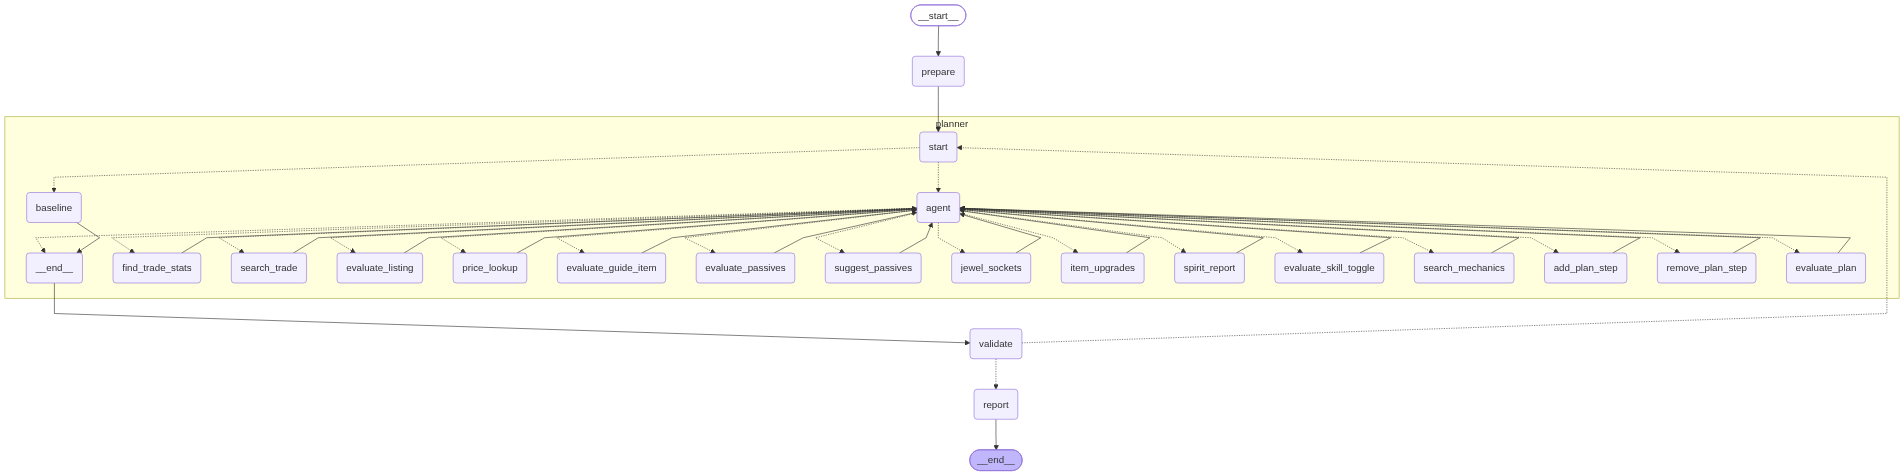

In [39]:
from IPython.display import Image, Markdown, display
from planner.graph import build_graph
try:
    import truststore; truststore.inject_into_ssl()
    display(Image(build_graph().get_graph(xray=True).draw_mermaid_png()))
except Exception as e:
    print("Sin render PNG:", e); print(build_graph().get_graph(xray=True).draw_mermaid())

## 7. Experimento

La celda siguiente corre el grafo completo en un modo y muestra el reporte con sus métricas.

In [40]:
import json
from langgraph.types import Command
from planner import graph as graph_mod

def run_plan(mode, thread):
    graph = graph_mod.build_graph()
    config = {"configurable": {"thread_id": thread}}
    inputs = {"build_path": str(BUILD_PATH), "wallet_path": WALLET, "guide_id": GUIDE or "", "objective": OBJECTIVE,
              "resist_floor": RESIST_FLOOR, "mode": mode}
    result = graph.invoke(inputs, config)
    while "__interrupt__" in result:   # nivel insuficiente para la guía: pide otra
        payload = result["__interrupt__"][0].value
        print(payload["message"], "| repertorio:", payload.get("options"))
        result = graph.invoke(Command(resume=input("> ")), config)
    print("Reporte:", result["report_path"])
    return result


### 7.1 Línea base: reglas fijas y selección greedy, sin LLM

In [41]:
baseline = run_plan("baseline", "baseline")
display(Markdown(Path(baseline["report_path"]).read_text(encoding="utf-8")))

Guía elegida automáticamente: coc-comet-animeprincess (parecido por guía: {'coc-comet-animeprincess': 0.584, 'spark-stormweaver-poevault': 0.106})


  ronda 1, necesidades: ['Str 74 < requisito 75', 'Spirit sobre-reservado (-26)', 'Caos es la capa más débil (golpe máx. 2493)', 'Más Energy Shield']
  search Ring 1 for str >= 1 (+2 keep) <= 150 ex


  search Amulet for str >= 15 (+0 keep) <= 150 ex


  search Amulet for spirit >= 26 (+1 keep) <= 150 ex


  search Body Armour for spirit >= 81 (+2 keep) <= 150 ex


...

  search Belt for chaos >= 20 (+2 keep) <= 150 ex


  search Amulet for es >= 81 (+1 keep) <= 150 ex


  search Belt for es >= 40 (+2 keep) <= 150 ex


Reporte: reports\2026-10-15_poe2.2_coc-comet-animeprincess_sin-llm-baseline.md


# Plan para Stormweaver nivel 81, guía `coc-comet-animeprincess`

Modo: baseline | Variante: `basic` | Presupuesto: 2897 ex, 300,000 oro

## Pasos

| # | Tipo | Acción | Costo | Motivo |
|---|---|---|---|---|
| 1 | skill | Apagar Mana Remnants (libera 30 de spirit) | - | Es la skill que menos pierde al apagarla (DPS +0.0%). |
| 2 | compra | Comprar Sol Spiral Amethyst Ring para Ring 1 ([trade](https://www.pathofexile.com/trade2/search/poe2/Forbidden%20Rites?q=%7B%22query%22%3A%7B%22status%22%3A%7B%22option%22%3A%22securable%22%7D%2C%22stats%22%3A%5B%7B%22type%22%3A%22and%22%2C%22filters%22%3A%5B%7B%22id%22%3A%22pseudo.pseudo_total_strength%22%2C%22value%22%3A%7B%22min%22%3A1%7D%7D%2C%7B%22id%22%3A%22pseudo.pseudo_total_lightning_resistance%22%2C%22value%22%3A%7B%22min%22%3A25%7D%7D%2C%7B%22id%22%3A%22pseudo.pseudo_total_dexterity%22%2C%22value%22%3A%7B%22min%22%3A13%7D%7D%5D%7D%5D%2C%22filters%22%3A%7B%22type_filters%22%3A%7B%22filters%22%3A%7B%22category%22%3A%7B%22option%22%3A%22accessory.ring%22%7D%7D%7D%2C%22trade_filters%22%3A%7B%22filters%22%3A%7B%22price%22%3A%7B%22max%22%3A150.0%2C%22option%22%3A%22exalted%22%7D%2C%22account%22%3A%7B%22input%22%3A%22%5Cuc0c1%5Cuc790%5Cuc18d%5Cuc138%5Cuc0c1%233941%22%7D%7D%7D%2C%22req_filters%22%3A%7B%22filters%22%3A%7B%22lvl%22%3A%7B%22max%22%3A81%7D%7D%7D%7D%7D%2C%22sort%22%3A%7B%22price%22%3A%22asc%22%7D%7D)) | 1 ex | Mayor puntaje (99.8): corrige ['Str 74 < requisito 75'], DPS -2.6%, EHP +2.2% |

## Efecto combinado (PoB)

| Stat | Antes | Después | Cambio |
|---|---|---|---|
| BuildDPS | 103,924.3 | 101,238.0 | -2,686.3 |
| TotalEHP | 6,584.7 | 6,732.3 | +147.6 |
| Life | 1,214 | 1,218 | +4 |
| Mana | 915 | 919 | +4 |
| SpiritUnreserved | -26 | 4 | +30 |
| ChaosResist | 0 | 7 | +7 |
| PhysicalMaximumHitTaken | 3,703 | 3,707 | +4 |
| ChaosMaximumHitTaken | 2,493 | 2,684 | +191 |
| Str | 74 | 76 | +2 |
| Int | 153 | 155 | +2 |

| Skill | DPS antes | DPS después | Crítico antes | Crítico después |
|---|---|---|---|---|
| Spark | 20,120 | 18,946 | 67.2% | 67.2% |
| Orb of Storms | 22,285 | 21,108 | 74.7% | 74.7% |
| Comet | 61,520 | 61,184 | 97.1% | 97.1% |

Problemas resueltos: Spirit sobre-reservado (-26); Str 74 < requisito 75

Gasto: 1.0 ex | Tiempo: 219 s | Llamadas al LLM: 0 | Costo LLM: $0.00

## Resumen

Línea base: compras elegidas por puntaje fijo, sin LLM.

### 7.2 Solución: agente ReAct con Claude
Cuesta entre $1 y $2 con Opus 5.5.

In [42]:
agent = run_plan("react", "agente") if HAS_KEY else None
if agent:
    display(Markdown(Path(agent["report_path"]).read_text(encoding="utf-8")))
else:
    print("Sin ANTHROPIC_API_KEY: se omite el agente.")

Guía elegida automáticamente: coc-comet-animeprincess (parecido por guía: {'coc-comet-animeprincess': 0.584, 'spark-stormweaver-poevault': 0.106})


  - evaluate_skill_toggle({"disable_groups": [9]})
  - item_upgrades({})
  - jewel_sockets({})
  - suggest_passives({"max_points": 6, "top": 8})


  - evaluate_guide_item({"slot": "Weapon 1"})  - find_trade_stats({"text": "to Spirit"})



  - find_trade_stats({"text": "to Level of all Spell Skills"})


  - evaluate_guide_item({"slot": "Amulet"})


...

  - add_plan_step({"kind": "level-up", "description": "Próximos 2 puntos: Dampening Shield", "cost_exalted": 0, "rationale": "Me)
  - add_plan_step({"kind": "level-up", "description": "Siguientes 5 puntos: Illuminated Crown (por los nodos de Atributo, elige )
  - add_plan_step({"kind": "ascendancy", "description": "Próxima prueba de ascendencia: Remnant Range y luego Storm's Recollecti)


  - evaluate_plan({})


  planner: 54 turns, claude-opus-5-5, cost $1.88


Reporte: reports\2026-10-15_poe2.2_coc-comet-animeprincess_opus-5-5-react.md


# Plan para Stormweaver nivel 81, guía `coc-comet-animeprincess`

Modo: react | Variante: `basic` | Presupuesto: 2897 ex, 300,000 oro

## Pasos

| # | Tipo | Acción | Costo | Motivo |
|---|---|---|---|---|
| 1 | skill | Desactivar Convalescence (grupo 9) para liberar 30 de espíritu | - | El espíritu está sobre-reservado (-26). Desactivar Convalescence lo deja en +4 sin ningún cambio de DPS ni de crítico (Spark 67.2%, Orb 74.7%, Comet 97.1%). Es una habilidad manual de recarga de ES (calidad de vida), mientras que Cast on Critical/Comet (59% del daño), Siphon Elements (infusiones para Comet) y Mana Remnants (maná) son núcleo. El bastón de la guía con espíritu costaría -24.3% BuildDPS y el amuleto de la guía -8.6% BuildDPS y -422 EHP. (guía: "You want 181 total spirit") |
| 2 | respec | Reasignar Lingering Horror, Branching Bolts y Echoing Flames a Turn the Clock Forward y Melding: Turn the Clock Forward > Energy Shield > Melding | - | Los tres nodos retirados no aportan nada medido (daño de caos, cadenas, ignite). Medido: +3367 BuildDPS (+3.2%), +476 ES, +564 TotalEHP, -88 maná. 3 puntos devueltos, 3 usados. |
| 3 | compra | Comprar Soul Shard Sapphire (11% ES máx, 11% crítico, 4% vel. lanzamiento, +12% daño de hechizos activados) para sustituir Fulgent Glisten ([trade](https://www.pathofexile.com/trade2/search/poe2/Forbidden%20Rites?q=%7B%22query%22%3A%7B%22status%22%3A%7B%22option%22%3A%22securable%22%7D%2C%22type%22%3A%22Sapphire%22%2C%22stats%22%3A%5B%7B%22type%22%3A%22and%22%2C%22filters%22%3A%5B%7B%22id%22%3A%22explicit.stat_2482852589%22%2C%22value%22%3A%7B%22min%22%3A10.0%7D%7D%2C%7B%22id%22%3A%22explicit.stat_587431675%22%2C%22value%22%3A%7B%22min%22%3A10.0%7D%7D%2C%7B%22id%22%3A%22explicit.stat_2891184298%22%2C%22value%22%3A%7B%22min%22%3A2.0%7D%7D%5D%7D%5D%2C%22filters%22%3A%7B%22type_filters%22%3A%7B%22filters%22%3A%7B%22category%22%3A%7B%22option%22%3A%22jewel%22%7D%7D%7D%2C%22trade_filters%22%3A%7B%22filters%22%3A%7B%22price%22%3A%7B%22max%22%3A200.0%2C%22option%22%3A%22exalted%22%7D%2C%22account%22%3A%7B%22input%22%3A%22madang009%230957%22%7D%7D%7D%2C%22req_filters%22%3A%7B%22filters%22%3A%7B%22lvl%22%3A%7B%22max%22%3A81%7D%7D%7D%7D%7D%2C%22sort%22%3A%7B%22price%22%3A%22asc%22%7D%7D)) | 50 ex | Fulgent Glisten tiene un mod de minions inútil. Medido: +1523 BuildDPS (+1.5%), +95 ES, +183 TotalEHP; Comet sube su crítico de 97.1% a 99.4%. (guía: "I would say % max energy shield is a mandatory mod though.") |
| 4 | compra | Comprar Vengeance Cord Double Belt (3 ranuras de charm, +85 maná, +26 Fuerza, +44% fuego, +24% rayo) ([trade](https://www.pathofexile.com/trade2/search/poe2/Forbidden%20Rites?q=%7B%22query%22%3A%7B%22status%22%3A%7B%22option%22%3A%22securable%22%7D%2C%22stats%22%3A%5B%7B%22type%22%3A%22and%22%2C%22filters%22%3A%5B%7B%22id%22%3A%22explicit.stat_3372524247%22%2C%22value%22%3A%7B%22min%22%3A40.0%7D%7D%2C%7B%22id%22%3A%22explicit.stat_1671376347%22%2C%22value%22%3A%7B%22min%22%3A15.0%7D%7D%2C%7B%22id%22%3A%22explicit.stat_4080418644%22%2C%22value%22%3A%7B%22min%22%3A5.0%7D%7D%5D%7D%5D%2C%22filters%22%3A%7B%22type_filters%22%3A%7B%22filters%22%3A%7B%22category%22%3A%7B%22option%22%3A%22accessory.belt%22%7D%7D%7D%2C%22trade_filters%22%3A%7B%22filters%22%3A%7B%22price%22%3A%7B%22max%22%3A300.0%2C%22option%22%3A%22exalted%22%7D%2C%22account%22%3A%7B%22input%22%3A%22Baalsulghor%235753%22%7D%7D%7D%2C%22req_filters%22%3A%7B%22filters%22%3A%7B%22lvl%22%3A%7B%22max%22%3A81%7D%7D%7D%7D%7D%2C%22sort%22%3A%7B%22price%22%3A%22asc%22%7D%7D)) | 16 ex | Compensa la resistencia al rayo que pierde el anillo nuevo y da fuego de sobra para poder cambiar el casco por uno con crítico. Mantiene 3 ranuras de charm y la Fuerza por encima de 75 junto con el anillo. |
| 5 | compra | Comprar Hypnotic Glance Ancestral Tiara (68% ES, 19% crítico, +31% frío, +41% rayo, ranura de runa libre) ([trade](https://www.pathofexile.com/trade2/search/poe2/Forbidden%20Rites?q=%7B%22query%22%3A%7B%22status%22%3A%7B%22option%22%3A%22securable%22%7D%2C%22stats%22%3A%5B%7B%22type%22%3A%22and%22%2C%22filters%22%3A%5B%7B%22id%22%3A%22explicit.stat_587431675%22%2C%22value%22%3A%7B%22min%22%3A15.0%7D%7D%2C%7B%22id%22%3A%22explicit.stat_4015621042%22%2C%22value%22%3A%7B%22min%22%3A40.0%7D%7D%2C%7B%22id%22%3A%22explicit.stat_1671376347%22%2C%22value%22%3A%7B%22min%22%3A26.0%7D%7D%2C%7B%22id%22%3A%22explicit.stat_4220027924%22%2C%22value%22%3A%7B%22min%22%3A19.0%7D%7D%5D%7D%5D%2C%22filters%22%3A%7B%22type_filters%22%3A%7B%22filters%22%3A%7B%22category%22%3A%7B%22option%22%3A%22armour.helmet%22%7D%7D%7D%2C%22trade_filters%22%3A%7B%22filters%22%3A%7B%22price%22%3A%7B%22max%22%3A1500.0%2C%22option%22%3A%22exalted%22%7D%2C%22account%22%3A%7B%22input%22%3A%22terazan%233762%22%7D%7D%7D%2C%22req_filters%22%3A%7B%22filters%22%3A%7B%22lvl%22%3A%7B%22max%22%3A81%7D%7D%7D%7D%7D%2C%22sort%22%3A%7B%22price%22%3A%22asc%22%7D%7D)) | 5 ex | Victory Ward no da ES ni crítico. Medido solo: +2389 BuildDPS (+2.3%), +382 ES, +180 TotalEHP; crítico de Spark 67.2→70.0%, Orb 74.7→77.8%, Comet 100%. El fuego que pierde lo cubren el cinturón y la runa del paso siguiente. (guía: "20-30 spirit - Helmet corruption") |
| 6 | calidad/runas | Casco nuevo: poner Greater Desert Rune en la ranura libre y subir calidad a 20% (3 Armourer's Scrap) | 37 ex | potential_if_finished del casco: +399 ES y +487 TotalEHP en total, y la runa de fuego elimina el aviso de resistencia al fuego. Coste 37.4 ex. |
| 7 | compra | Comprar Rune Circle Prismatic Ring (+7% todas las resistencias, 23% vel. lanzamiento, 12% daño de rayo, +13 Fuerza, +22 Destreza) para el Anillo 1 ([trade](https://www.pathofexile.com/trade2/search/poe2/Forbidden%20Rites?q=%7B%22query%22%3A%7B%22status%22%3A%7B%22option%22%3A%22securable%22%7D%2C%22stats%22%3A%5B%7B%22type%22%3A%22and%22%2C%22filters%22%3A%5B%7B%22id%22%3A%22explicit.stat_2891184298%22%2C%22value%22%3A%7B%22min%22%3A15.0%7D%7D%2C%7B%22id%22%3A%22explicit.stat_4080418644%22%2C%22value%22%3A%7B%22min%22%3A5.0%7D%7D%2C%7B%22id%22%3A%22explicit.stat_3261801346%22%2C%22value%22%3A%7B%22min%22%3A15.0%7D%7D%5D%7D%5D%2C%22filters%22%3A%7B%22type_filters%22%3A%7B%22filters%22%3A%7B%22category%22%3A%7B%22option%22%3A%22accessory.ring%22%7D%7D%7D%2C%22trade_filters%22%3A%7B%22filters%22%3A%7B%22price%22%3A%7B%22max%22%3A800.0%2C%22option%22%3A%22exalted%22%7D%2C%22account%22%3A%7B%22input%22%3A%22Gifli%237382%22%7D%7D%7D%2C%22req_filters%22%3A%7B%22filters%22%3A%7B%22lvl%22%3A%7B%22max%22%3A81%7D%7D%7D%7D%7D%2C%22sort%22%3A%7B%22price%22%3A%22asc%22%7D%7D)) | 1 ex | Corrige la Fuerza (requisito 75) sin perder el +7% a todas las resistencias ni bajar la Destreza por debajo de 56. Medido solo: +697 BuildDPS (+0.7%). El Skull Twirl Pearl daba +2079 DPS pero junto con el casco nuevo dejaba el fuego en 67% (< suelo de 70%). |
| 8 | subir de nivel | Próximos 2 puntos: Dampening Shield: Stun and Ailment Threshold from Energy Shield > Dampening Shield | - | Medido: +242 ES, +330 TotalEHP (2.51% por punto), además de umbral de aturdimiento/ailments basado en ES. Paso previo a Chaos Inoculation. |
| 9 | subir de nivel | Siguientes 5 puntos: Illuminated Crown (por los nodos de Atributo, elige Fuerza/Inteligencia): Attribute > Attribute > Attribute > Energy Shield > Illuminated Crown | - | Medido con el casco actual (sin ES): +182 ES, +270 TotalEHP; con el casco nuevo de 68% ES el valor será mayor. Necesario antes de Chaos Inoculation según la guía. |
| 10 | ascendencia | Próxima prueba de ascendencia: Remnant Range y luego Storm's Recollection: Remnant Range > Storm's Recollection | - | PoB no mide cambio (efecto de recogida de Remnants), pero los Remnants reaparecen una vez y se recogen hasta un 75% más lejos: más infusiones para Comet y más Mana Remnants, lo que la guía usa para el maná y Elemental Equilibrium. |

## Efecto combinado (PoB)

| Stat | Antes | Después | Cambio |
|---|---|---|---|
| BuildDPS | 103,924.3 | 111,023.2 | +7,098.9 |
| TotalEHP | 6,584.7 | 7,812.9 | +1,228.2 |
| Life | 1,214 | 1,226 | +12 |
| EnergyShield | 2,379 | 3,424 | +1,045 |
| Mana | 915 | 805 | -110 |
| SpiritUnreserved | -26 | 4 | +30 |
| FireResist | 75 | 74 | -1 |
| PhysicalMaximumHitTaken | 3,703 | 4,739 | +1,036 |
| ChaosMaximumHitTaken | 2,493 | 3,027 | +534 |
| Str | 74 | 80 | +6 |
| Dex | 72 | 65 | -7 |

| Skill | DPS antes | DPS después | Crítico antes | Crítico después |
|---|---|---|---|---|
| Spark | 20,120 | 21,608 | 67.2% | 71.6% |
| Orb of Storms | 22,285 | 24,013 | 74.7% | 79.5% |
| Comet | 61,520 | 65,402 | 97.1% | 100.0% |

Problemas resueltos: Spirit sobre-reservado (-26); Str 74 < requisito 75

Gasto: 109.4 ex | Tiempo: 1252 s | Llamadas al LLM: 54 | Costo LLM: $1.88

## Resumen

## Resumen del plan

El plan ya está medido en conjunto y no deja problemas pendientes. Corrige los dos problemas graves que tenías y sube el daño sin perder defensa:

- **BuildDPS:** de 103 924 a 111 023 (+7 099, +6.8%).
  - Spark: de 20 120 a 21 608 DPS; crítico de 67.2% a 71.6%.
  - Orb of Storms: de 22 285 a 24 013 DPS; crítico de 74.7% a 79.5%.
  - Comet: de 61 520 a 65 402 DPS; crítico de 97.1% a 100%. Al subir el crítico, Cast on Critical carga más rápido en el juego real.
- **Defensa:** el Energy Shield sube de 2 379 a 3 424 (+1 045) y el TotalEHP de 6 584 a 7 813 (+1 228).
- **Resistencias:** todas siguen en 75%, salvo el fuego, que queda en 74%.
- **Problemas corregidos:** la Fuerza pasa de 74 a 80 (el requisito es 75) y el espíritu de −26 a +4.
- **Coste:** 109.4 ex de 2 897 y unos 69 000 de oro de las comisiones de compra. No sé cuánto oro cuesta reasignar los 3 puntos del respec.
- **Lo que pierdes:** 110 de maná (de 915 a 805).
- **Mejora del casco no incluida en las cifras:** el paso de "craft" (Greater Desert Rune y calidad al 20%) no se aplica en la simulación del plan. Medido aparte con tu equipo de antes, ese casco terminado daba +399 ES y +487 TotalEHP en vez de +382 y +180.

**Espíritu: las dos opciones medidas**
- **(a) Comprar espíritu.** No sale a cuenta:
  - El bastón de la guía con +43 de espíritu cuesta −24.3% BuildDPS y baja el crítico de Comet de 97.1% a 82.6%.
  - El amuleto de la guía con +38 baja el BuildDPS un 8.6% y el TotalEHP en 422, y deja la Fuerza en 60.
  - No encontré a la venta ningún amuleto con +2 a hechizos y espíritu.
- **(b) Desactivar Convalescence (grupo 9).** Es la opción elegida:
  - Libera 30 de espíritu sin ningún cambio de DPS ni de crítico.
  - Es la habilidad más prescindible: es manual y solo sirve para empezar a recargar el ES (calidad de vida).
  - Las otras son núcleo: Cast on Critical + Comet son el 59% del daño, Siphon Elements da las infusiones y Mana Remnants mantiene el maná.

**Otras decisiones**
- **Bastón:** Rune Goad se queda. Las tres alternativas que medí perdían entre un 20% y un 26% de BuildDPS, y entre un 7% y un 20% incluso terminadas.
- **Joyas:** solo cambio Fulgent Glisten, porque tiene un mod de minions inútil. Las otras dos joyas están bien: los reemplazos que medí daban como mucho +628 DPS por 190 ex.
- **Calidad de tu equipo actual:**
  - Casco: subirlo al 20% costaba 88.6 ex por solo +19 de ES, y ese casco se reemplaza en el plan.
  - Botas: subirlas costaba 19.7 ex por +8 de ES. No merece la pena.
- **Anillo:** elegí el Rune Circle Prismatic aunque el Skull Twirl Pearl daba más daño (+2 079 DPS frente a +697). El Pearl, junto con el casco nuevo, dejaba el fuego en 67%, por debajo de tu mínimo de 70%.

**Qué hacer después del plan**
1. **Pasivos:** al subir de nivel, coge Dampening Shield y luego Illuminated Crown. Este último valdrá más con el nuevo casco de ES. Echoing Thunder y Arcane Remnants no aportan nada medido, así que son los próximos puntos a reasignar.
2. **Chaos Inoculation:** tu ES (3 424) ya supera de largo a tu vida (1 226). Cuando tengas Dampening Shield e Illuminated Crown, mide CI y después Hallowed. Con CI la vida y la resistencia al caos dejan de importar.
3. **Daño con más currency:**
   - un anillo con velocidad de lanzamiento que mantenga las resistencias;
   - un amuleto con espíritu, +2 a hechizos y crítico, para poder reactivar Convalescence;
   - en endgame, los nodos Stormcharged y Brain Freeze.
4. **Botas:** tienen solo un 5% de velocidad de movimiento. Busca unas con más velocidad que conserven el ES. Las Warlock Leggings que medí costaban 200 ex y quitaban 426 de ES, así que las descarté.

## 8. Evaluación

La misma medida y el costo de las dos opciones, sobre la misma build y el mismo momento del mercado.

In [43]:
runs = [(name, r["metrics"]) for name, r in [("Línea base (reglas, sin LLM)", baseline),
                                              ("Agente ReAct (Opus)", agent)] if r]
def cells(f):
    return [f(m) for _, m in runs]
rows = [
    ("BuildDPS (cambio %)", cells(lambda m: f"{m['build_dps_pct']:+.1f}")),
    ("EHP (cambio %)", cells(lambda m: f"{m['ehp_pct']:+.1f}")),
    ("Energy Shield (cambio %)", cells(lambda m: f"{m['es_pct']:+.1f}")),
    ("Problemas antes", cells(lambda m: len(m["problems_before"]))),
    ("Problemas resueltos", cells(lambda m: len(m["problems_fixed"]))),
    ("Problemas pendientes", cells(lambda m: "; ".join(m["problems_left"]) or "0")),
    ("Plan válido", cells(lambda m: "sí" if m["valid"] else "no")),
    ("**Tarea resuelta**", cells(lambda m: "**sí**" if m["solved"] else "no")),
    ("Pasos del plan", cells(lambda m: m["steps"])),
    ("Gasto (ex / oro)", cells(lambda m: f"{m['spent_exalted']:,.0f} / {m['spent_gold']:,}")),
    ("Tiempo (s)", cells(lambda m: m["seconds"])),
    ("Llamadas al LLM", cells(lambda m: m["llm_requests"])),
    ("Tokens entrada / salida", cells(lambda m: f"{m['input_tokens']:,} / {m['output_tokens']:,}")),
    ("Costo LLM (USD)", cells(lambda m: f"{m['cost_usd']:.2f}")),
    ("Búsquedas en trade", cells(lambda m: m["trade_searches"])),
    ("Evaluaciones del motor PoB", cells(lambda m: m["engine_evals"])),
]
a = runs[-1][1]
table = ["| Medida | " + " | ".join(name for name, _ in runs) + " |", "|---" * (len(runs) + 1) + "|"]
table += [f"| {name} | " + " | ".join(str(v) for v in vals) + " |" for name, vals in rows]
display(Markdown(f"Build `{a['build']}` (nivel {a['level']}), guía `{a['guide']}`, variante `{a['variant']}`, "
                 f"presupuesto {a['budget_exalted']:,.0f} ex\n\n" + "\n".join(table)))

Build `poe2.2` (nivel 81), guía `coc-comet-animeprincess`, variante `basic`, presupuesto 2,897 ex

| Medida | Línea base (reglas, sin LLM) | Agente ReAct (Opus) |
|---|---|---|
| BuildDPS (cambio %) | -2.6 | +6.8 |
| EHP (cambio %) | +2.2 | +18.7 |
| Energy Shield (cambio %) | +0.0 | +43.9 |
| Problemas antes | 2 | 2 |
| Problemas resueltos | 2 | 2 |
| Problemas pendientes | 0 | 0 |
| Plan válido | sí | sí |
| **Tarea resuelta** | **sí** | **sí** |
| Pasos del plan | 2 | 10 |
| Gasto (ex / oro) | 1 / 11,135 | 109 / 68,556 |
| Tiempo (s) | 219 | 1252 |
| Llamadas al LLM | 0 | 54 |
| Tokens entrada / salida | 0 / 0 | 3,298,340 / 32,201 |
| Costo LLM (USD) | 0.00 | 1.88 |
| Búsquedas en trade | 17 | 20 |
| Evaluaciones del motor PoB | 317 | 445 |

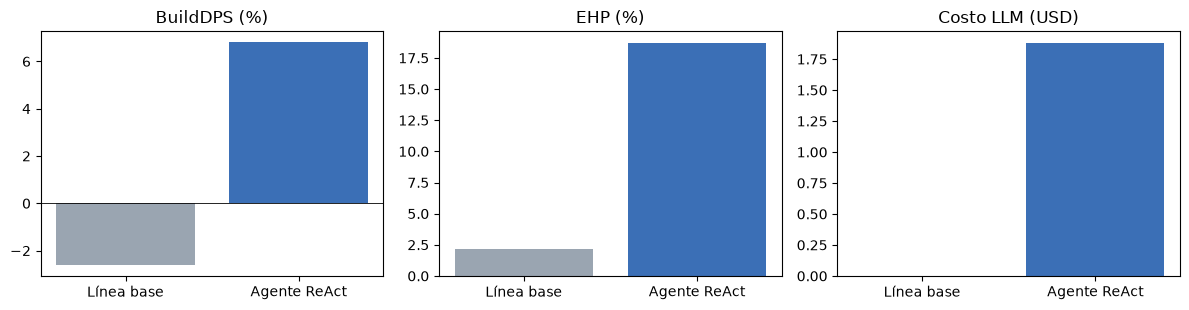

In [44]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
labels = [name.split(" (")[0] for name, _ in runs]
for ax, (title, key) in zip(axes, [("BuildDPS (%)", "build_dps_pct"), ("EHP (%)", "ehp_pct"), ("Costo LLM (USD)", "cost_usd")]):
    ax.bar(labels, [m[key] for _, m in runs], color=["#9aa5b1", "#3b6fb6"][:len(runs)])
    ax.set_title(title); ax.axhline(0, color="black", lw=0.6)
plt.tight_layout(); plt.show()

## 9. Conclusiones

El experimento se hizo con un solo personaje (`poe2.2`, una Stormweaver nivel 81) y con la guía que el sistema eligió sola por parecido (`coc-comet-animeprincess`). Los números exactos están en la tabla de la sección 8; aquí van las ideas principales con valores aproximados.

Las dos variantes resolvieron la tarea: arreglaron la Fuerza por debajo del requisito y el spirit sobre-reservado, y dejaron un plan válido. La línea base lo hizo gastando casi nada (1 ex en un anillo, además de apagar una skill) y moviendo el plan levemente hacia la defensa: el EHP subió cerca de un 2% a cambio de perder un poco de daño (alrededor de un 3%). El agente gastó más (unos 110 ex, cerca de un 4% del presupuesto) y subió las dos cosas a la vez: alrededor de un 7% de daño y un 19% de EHP, con un 44% más de Energy Shield y más crítico en todas las skills.

Que la línea base también resuelva la tarea muestra que, para los problemas que se pueden medir, unas pocas reglas bien elegidas son suficientes, pero tal vez no brindan la mejor opción (la línea base fue demasiado conservadora con el presupuesto). Por otro lado, también se evidencia la diferencia cuando los resultados no se pueden medir fácilmente con un motor: para liberar spirit la regla apagó la skill que según PoB no perdía nada, Mana Remnants, pero PoB no mide los efectos por evento, y en esta build esa skill es indispensable para el maná. El agente revisó lo que hace cada skill, decidió que esa era parte del núcleo y apagó Convalescence, una recarga manual de ES que sí era prescindible. También comparó esa opción con comprar equipo con spirit y la descartó porque costaba mucho daño.

La otra diferencia es lo que cada uno puede hacer. La línea base solo compra equipo y apaga una skill. El agente, además de comprar, propuso un respec que cambia tres nodos que no aportan por otros que sí, una joya mejor, calidad y una runa para el casco nuevo, los siguientes puntos al subir de nivel, la siguiente ascendencia y cuándo pasar a Chaos Inoculation según la guía. Eso es lo que un jugador necesita para seguir una guía sin copiarla al pie de la letra, y una regla fija no lo cubre.

Usar Path of Building como fuente de verdad fue una pieza importante del diseño y permitió definir el baseline así como lograr combinar lenguaje natural con valores exactos y no solamente basar las posibilidades en suposiciones.

En cuanto a RAG, la búsqueda híbrida no fue claramente mejor que la densa según la evaluación de RAGAS y también existen fallos generales dado que el modelo de embeddings funciona en inglés únicamente. A pesar de ello, se mantuvo como decisión fija usar el buscador híbrido por si los embeddings no entienden un término del juego, así la búsqueda literal evita perder ese pasaje. Un trabajo futuro consistiría en pasar toda la wiki como base local y usar un embedder multilingüe.

El costo del agente fue razonable (alrededor de dos dólares por corrida y unos 20 minutos, la mayor parte esperando el rate limit del trade site), pero el modelo no es determinista: con la misma build, otra corrida puede inclinar el plan más hacia el daño o más hacia la defensa. En una corrida anterior con la misma build y la misma guía, el agente subió el EHP un 4%; en esta, un 19%. 

Para lograr mejores resultados, el trabajo futuro consistirá en lograr que el LLM sea menos conservador y se acerque más al presupuesto, así como incluir otra arquitectura como Deep Agents para lograr que el LLM logre entender mejor el dominio. De igual manera, es necesario mejorar los tools para que abarquen más conceptos del juego (objetos únicos, objetos de supervivencia que no alteran estadísticas como frascos de vida, mejoras sin guía de build basadas únicamente en un LLM, entre otros) y posiblemente generar un servidor MCP o skills que permitan a los ecosistemas más usados actualmente (Claude Code, OpenCode, Codex) interactuar directamente y aprovechar su ingeniería de prompts.


### Limitaciones

- "Tarea resuelta" es una medida usada para comparar ambas variantes. Únicamente mide la validez del nuevo plan y que se arreglen los problemas iniciales del personaje. Pero justamente que se solucionen esos problemas no necesariamente implica que el resultado sea mejor o peor, por lo que limita mucho la comparación (de ahí la evaluación con porcentajes de mejora o empeoramiento en daño y defensas).
- Con un solo personaje de una clase específica y para una build específica es imposible confirmar que el agente es lo suficientemente bueno para todo el dominio del juego y las condiciones específicas en otras clases/builds.
- El mercado cambia, así que el mismo experimento en otro momento encuentra otros ítems y precios.
- PoB no mide los efectos por evento (Remnants, infusiones, frascos y charms); ahí la decisión depende del razonamiento del LLM, y la línea base no tiene cómo verlos. Para abarcar todos estos posibles efectos se necesitarían cientos de condicionales anidados por el personaje actual, progresión y build a seguir que sería inviable.
- No hay API de stash ni de oro, así que el presupuesto se escribe a mano.
- La evaluación del RAG es pequeña y no necesariamente refleja todo el dominio del juego y las posibilidades de consulta del agente.

## 10. Declaración de uso de IA generativa

- Desarrollo: se usó Claude Code (modelo Claude Opus 5.5) como asistente de programación para el diseño de módulos, la escritura y depuración del código, la investigación de herramientas y formas de obtener datos del juego, y el diseño de la presentación del proyecto con sus distintas variantes.

  La IA no intervino en la definición del problema, las preferencias, los criterios de evaluación ni en la iteración del proyecto para lograr los mejores resultados, que se basaron en la experiencia personal.

- Como parte de la solución: el agente usa la API de Claude (Opus 5.5) para planificar con tools, extraer las prioridades de la guía con citas literales y resumir la dirección de la build. Todos los números del reporte salen del motor PoB, del trade site o de poe.ninja, no del modelo, y el costo en tokens y dólares se mide en cada corrida.